In [1]:
import glob
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import bootstrap
from sklearn import datasets
from sklearn.feature_selection import RFE, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score, multilabel_confusion_matrix, RocCurveDisplay
from sklearn.preprocessing import LabelBinarizer
import statsmodels.api as sm

In [2]:
csv_files = glob.glob('Data'+'/**/*.csv', recursive=True)

features = []

for file in csv_files:
    data = pd.read_csv(file, header=None, na_values="?", skiprows=5)
    data.columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"] 
    data = data.drop(columns = ["time"])
    d1 = data.iloc[:int(np.ceil(len(data)/2)), :]
    d1.columns = ["avg_rss11", "var_rss11", "avg_rss21", "var_rss21", "avg_rss31", "var_rss31"] 
    d2 = data.iloc[int(np.ceil(len(data)/2)):, :].reset_index()
    d2 = d2.drop(columns = ["index"])
    d2.columns = ["avg_rss12", "var_rss12", "avg_rss22", "var_rss22", "avg_rss32", "var_rss32"] 
    data = d1.join(d2)
    features.append(data)


In [3]:
X = []
for f in features:
    x = {}
    for col in f.columns:
        x[f'min_{col}'] = f[col].min()
        x[f'max_{col}'] = f[col].max()
        x[f'mean_{col}'] = f[col].mean()
        x[f'median_{col}'] = f[col].median()
        x[f'std_{col}'] = f[col].std()
        x[f'1st_quart_{col}'] = f[col].quantile(0.25)
        x[f'3rd_quart_{col}'] = f[col].quantile(0.75)
    X.append(x)

df = pd.DataFrame(X)

In [4]:
bending_rows = []
for i,a in enumerate(csv_files):
    if 'bending' in a:
        bending_rows.append("Bending")
    else:
        bending_rows.append("Other")

df_ = df.join(pd.DataFrame({"bending": bending_rows}))
print(df_.columns)

Index(['min_avg_rss11', 'max_avg_rss11', 'mean_avg_rss11', 'median_avg_rss11',
       'std_avg_rss11', '1st_quart_avg_rss11', '3rd_quart_avg_rss11',
       'min_var_rss11', 'max_var_rss11', 'mean_var_rss11', 'median_var_rss11',
       'std_var_rss11', '1st_quart_var_rss11', '3rd_quart_var_rss11',
       'min_avg_rss21', 'max_avg_rss21', 'mean_avg_rss21', 'median_avg_rss21',
       'std_avg_rss21', '1st_quart_avg_rss21', '3rd_quart_avg_rss21',
       'min_var_rss21', 'max_var_rss21', 'mean_var_rss21', 'median_var_rss21',
       'std_var_rss21', '1st_quart_var_rss21', '3rd_quart_var_rss21',
       'min_avg_rss31', 'max_avg_rss31', 'mean_avg_rss31', 'median_avg_rss31',
       'std_avg_rss31', '1st_quart_avg_rss31', '3rd_quart_avg_rss31',
       'min_var_rss31', 'max_var_rss31', 'mean_var_rss31', 'median_var_rss31',
       'std_var_rss31', '1st_quart_var_rss31', '3rd_quart_var_rss31',
       'min_avg_rss12', 'max_avg_rss12', 'mean_avg_rss12', 'median_avg_rss12',
       'std_avg_rss12', '1s

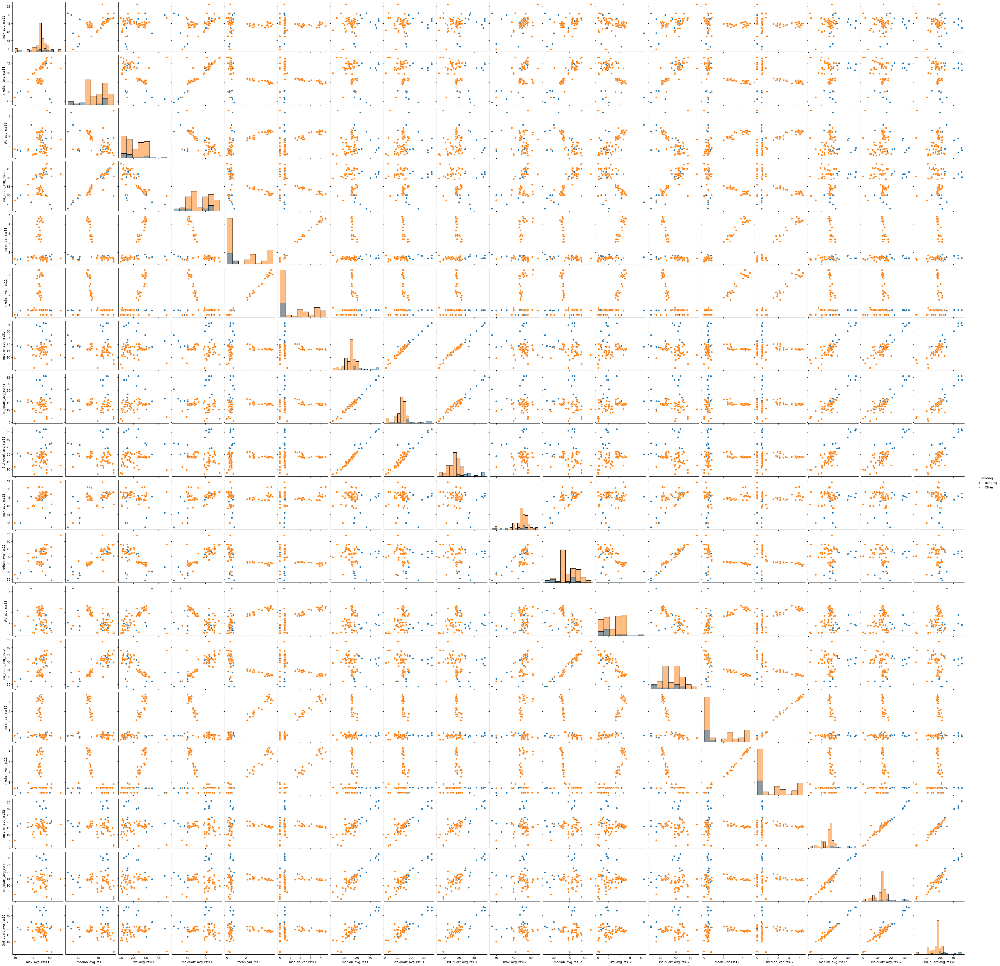

In [5]:
disp_cols = df_.iloc[:, [1, 3, 4, 5, 9, 10, 31, 33, 34, 1+42, 3+42, 4+42, 5+42, 9+42, 10+42, 31+42, 33+42, 34+42, -1]]
sns.pairplot(disp_cols, hue="bending", diag_kind="hist")

No, there is no discrenable difference in the results. 

In [6]:
X_train = {}
X_test = {}
for l in range(1, 21, 1):
    features = []
    
    for file in csv_files:
        data = pd.read_csv(file, header=None, na_values="?", skiprows=5)
        data.columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"] 
        data = data.drop(columns = ["time"])
        d1 = data.iloc[:int(np.ceil(len(data)/l)), :]
        d1.columns = ["avg_rss11", "var_rss11", "avg_rss21", "var_rss21", "avg_rss31", "var_rss31"] 
        for i in range(1, l, 1):
            d2 = data.iloc[i*int(np.ceil(len(data)/l)):(i+1)*int(np.ceil(len(data)/l)), :].reset_index()
            d2 = d2.drop(columns = ["index"])
            d2.columns = ["avg_rss1"+str(i+1), "var_rss1"+str(i+1), "avg_rss2"+str(i+1), 
                          "var_rss2"+str(i+1), "avg_rss3"+str(i+1), "var_rss3"+str(i+1)] 
            d1 = d1.join(d2)
        
        features.append(d1)

    train = []
    test = []
    for i,f in enumerate(features):
        x = {}
        for col in f.columns:
            x[f'min_{col}'] = f[col].min()
            x[f'max_{col}'] = f[col].max()
            x[f'mean_{col}'] = f[col].mean()
            x[f'median_{col}'] = f[col].median()
            x[f'std_{col}'] = f[col].std()
            x[f'1st_quart_{col}'] = f[col].quantile(0.25)
            x[f'3rd_quart_{col}'] = f[col].quantile(0.75)
        if 'dataset1.csv' in csv_files[i] or 'dataset2.csv' in csv_files[i] or 'dataset3.csv' in csv_files[i]:
            if 'dataset3' in csv_files[i] and 'bending' in csv_files[i]:
                train.append(x)
            else:
                test.append(x)
        else:
            train.append(x)
            
    X_train[l] = pd.DataFrame(train)
    X_test[l] = pd.DataFrame(test)


In [7]:
Y_train = []
Y_test = []
for i,a in enumerate(csv_files):
    if 'dataset1.csv' in a or 'dataset2.csv' in a or 'dataset3.csv' in a:
        if 'dataset3' in a and 'bending' in a:
            Y_train.append(1)
        else:
            if 'bending' in a:
                Y_test.append(1)
            else:
                Y_test.append(0)
    else:
        if 'bending' in a:
            Y_train.append(1)
        else:
            Y_train.append(0)

Y_train = np.array(Y_train)
Y_test = np.array(Y_test)

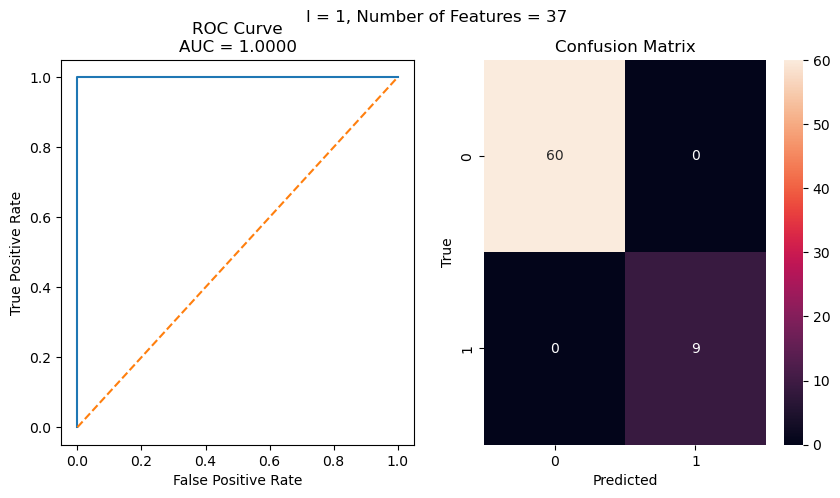

l = 1, Number of Relevant Features = 37, Features:
 Index(['min_avg_rss11', 'max_avg_rss11', 'mean_avg_rss11', 'median_avg_rss11',
       'std_avg_rss11', '1st_quart_avg_rss11', '3rd_quart_avg_rss11',
       'min_var_rss11', 'max_var_rss11', 'mean_var_rss11', 'median_var_rss11',
       'std_var_rss11', '1st_quart_var_rss11', '3rd_quart_var_rss11',
       'min_avg_rss21', 'max_avg_rss21', 'mean_avg_rss21', 'median_avg_rss21',
       'std_avg_rss21', '1st_quart_avg_rss21', '3rd_quart_avg_rss21',
       'min_var_rss21', 'mean_var_rss21', 'median_var_rss21', 'std_var_rss21',
       '1st_quart_var_rss21', '3rd_quart_var_rss21', 'min_avg_rss31',
       'max_avg_rss31', 'mean_avg_rss31', 'median_avg_rss31', 'std_avg_rss31',
       '3rd_quart_avg_rss31', 'min_var_rss31', 'mean_var_rss31',
       'median_var_rss31', '3rd_quart_var_rss31'],
      dtype='object')
                     Model Params  P-Values
min_avg_rss11           -0.112281  0.864027
max_avg_rss11           -0.278865  0.077461
mea

/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


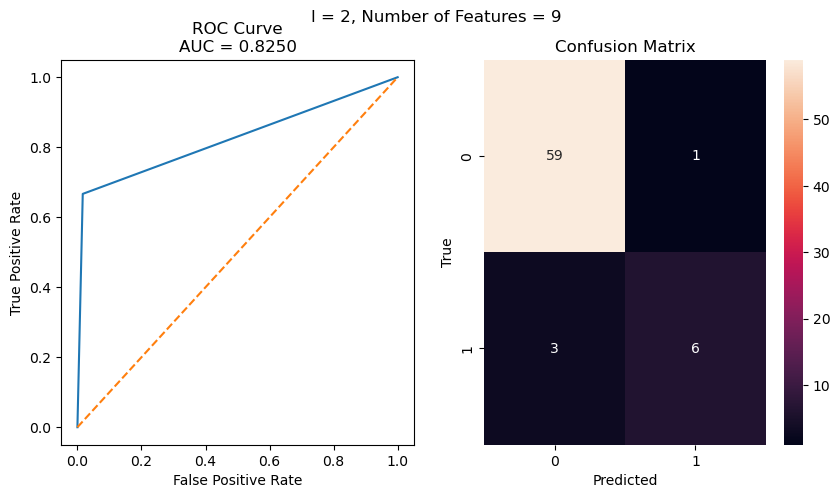

l = 2, Number of Relevant Features = 9, Features:
 Index(['max_avg_rss22', 'std_avg_rss11', 'median_var_rss31', 'std_avg_rss31',
       'max_avg_rss11', 'std_var_rss22', 'mean_var_rss31', 'median_var_rss12',
       'mean_var_rss12'],
      dtype='object')
                  Model Params      P-Values
max_avg_rss22         0.395531  2.244858e-26
std_avg_rss11         0.880445  2.469272e-28
median_var_rss31      5.740317  1.997106e-28
std_avg_rss31         0.533578  1.449261e-29
max_avg_rss11        -0.197789  7.755209e-30
std_var_rss22        -4.084660  4.958248e-30
mean_var_rss31       -8.106920  4.160937e-30
median_var_rss12      0.294304  3.211358e-30
mean_var_rss12        0.349482  7.316208e-31
*********************************************
No Feature with P-Value >= 0.05 for l = 3
choosing feature with top 10% P-Values


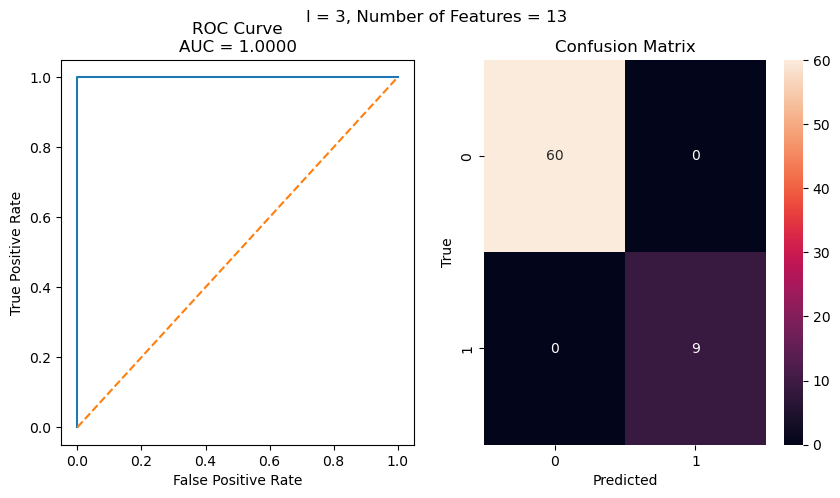

l = 3, Number of Relevant Features = 13, Features:
 Index(['1st_quart_var_rss21', 'std_avg_rss21', 'median_var_rss31',
       'mean_var_rss21', '3rd_quart_avg_rss12', '3rd_quart_avg_rss23',
       'mean_var_rss31', 'std_var_rss31', 'min_var_rss12', 'std_avg_rss31',
       '3rd_quart_avg_rss32', 'min_var_rss23', '3rd_quart_var_rss31'],
      dtype='object')
                     Model Params      P-Values
1st_quart_var_rss21     -3.040258  2.690158e-28
std_avg_rss21           42.272485  2.168834e-28
median_var_rss31        -5.868682  1.150956e-28
mean_var_rss21           0.866444  2.649513e-29
3rd_quart_avg_rss12    -19.678624  2.290991e-29
3rd_quart_avg_rss23    -16.788659  1.466906e-29
mean_var_rss31          -5.739702  1.045761e-29
std_var_rss31            0.333573  1.124084e-30
min_var_rss12           -0.091028  4.169789e-31
std_avg_rss31           36.815162  1.479350e-31
3rd_quart_avg_rss32     37.374439  1.395384e-31
min_var_rss23           -0.091935  1.025746e-31
3rd_quart_var_rss

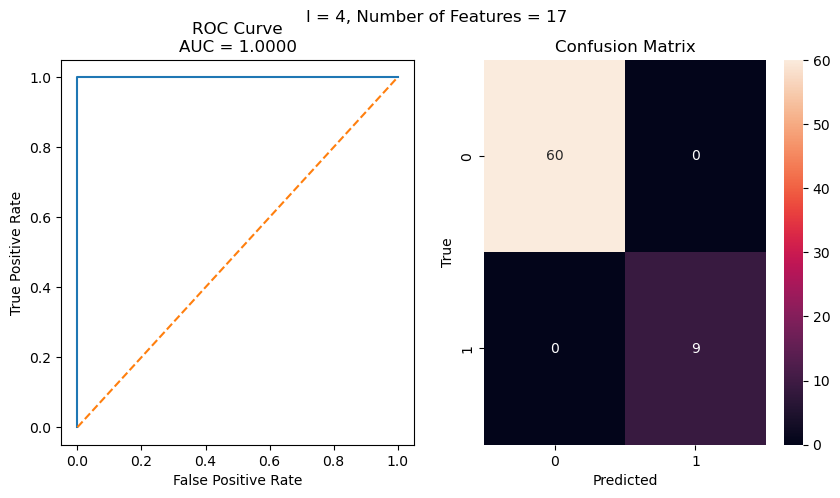

l = 4, Number of Relevant Features = 17, Features:
 Index(['1st_quart_var_rss31', 'std_var_rss23', 'max_var_rss22',
       'mean_var_rss32', 'median_avg_rss23', 'max_var_rss12', 'mean_avg_rss21',
       'median_var_rss32', '3rd_quart_var_rss31', 'std_var_rss31',
       '3rd_quart_avg_rss11', '1st_quart_avg_rss14', 'std_avg_rss23',
       'median_var_rss33', 'min_var_rss14', 'max_var_rss14',
       '1st_quart_var_rss32'],
      dtype='object')
                     Model Params      P-Values
1st_quart_var_rss31   -214.083487  4.474005e-30
std_var_rss23           96.127320  1.186904e-31
max_var_rss22           12.278758  8.130576e-33
mean_var_rss32        -119.739008  7.741353e-33
median_avg_rss23         6.281378  6.557859e-34
max_var_rss12          -25.709845  5.337264e-34
mean_avg_rss21           7.820606  1.827178e-34
median_var_rss32        62.412933  1.401657e-34
3rd_quart_var_rss31   -153.653860  1.353196e-34
std_var_rss31          463.655769  1.112297e-34
3rd_quart_avg_rss11    -1

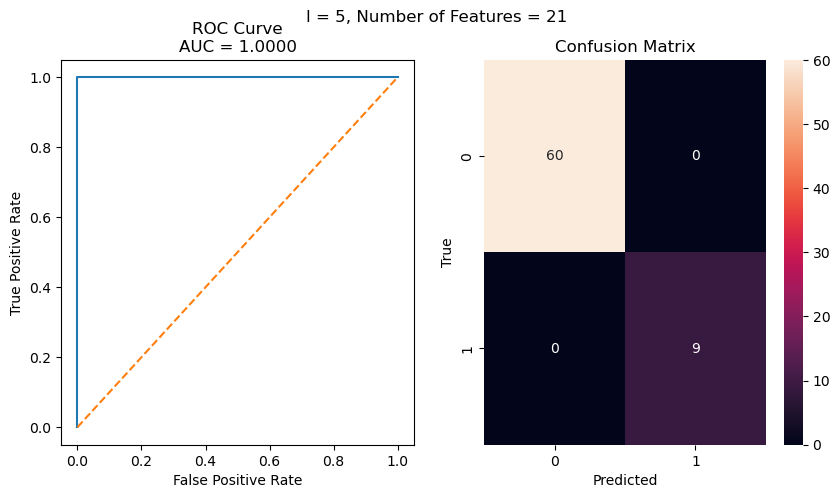

l = 5, Number of Relevant Features = 21, Features:
 Index(['3rd_quart_var_rss23', '1st_quart_avg_rss31', 'mean_var_rss21',
       'std_avg_rss33', 'mean_avg_rss21', 'max_var_rss31', 'mean_var_rss31',
       'mean_avg_rss31', 'median_avg_rss15', '3rd_quart_avg_rss24',
       'std_avg_rss14', 'std_var_rss21', 'std_var_rss31', 'median_var_rss33',
       'max_var_rss35', 'max_avg_rss13', '3rd_quart_avg_rss33',
       'median_avg_rss22', 'max_avg_rss21', 'std_avg_rss21',
       '1st_quart_var_rss12'],
      dtype='object')
                     Model Params      P-Values
3rd_quart_var_rss23     -0.272004  7.426214e-28
1st_quart_avg_rss31      1.745228  5.864335e-28
mean_var_rss21          -0.147027  1.831015e-28
std_avg_rss33            0.008601  9.160901e-29
mean_avg_rss21          -1.040225  7.347793e-29
max_var_rss31            0.178603  2.460020e-29
mean_var_rss31          -0.211566  1.829998e-29
mean_avg_rss31           2.308771  1.367394e-29
median_avg_rss15        -0.544518  5.223827e

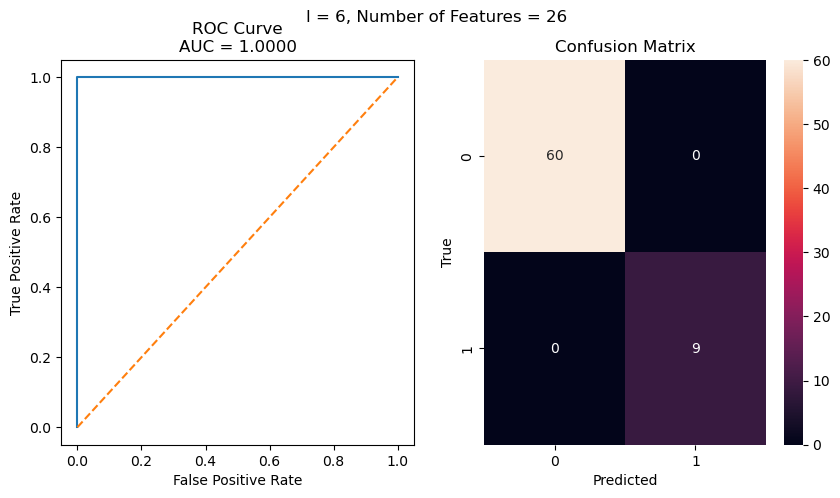

l = 6, Number of Relevant Features = 26, Features:
 Index(['median_var_rss21', '3rd_quart_var_rss26', 'max_avg_rss35',
       'max_avg_rss21', 'min_var_rss31', 'mean_var_rss21', 'median_var_rss31',
       'std_var_rss36', 'max_var_rss25', 'mean_var_rss31', 'std_var_rss21',
       'mean_avg_rss21', 'max_var_rss13', 'std_var_rss31', 'mean_var_rss24',
       '1st_quart_var_rss32', 'min_avg_rss21', 'mean_var_rss13',
       'std_avg_rss25', '3rd_quart_var_rss36', 'max_avg_rss24',
       'min_avg_rss22', 'median_var_rss36', '1st_quart_var_rss24',
       'min_var_rss16', 'std_avg_rss32'],
      dtype='object')
                     Model Params      P-Values
median_var_rss21       -79.032539  2.529638e-27
3rd_quart_var_rss26    -19.829457  1.296210e-29
max_avg_rss35           47.716398  3.579567e-30
max_avg_rss21           22.763688  2.544339e-30
min_var_rss31           -2.213017  1.724509e-30
mean_var_rss21          23.222768  1.342234e-30
median_var_rss31      -201.705103  5.532543e-31
std_v

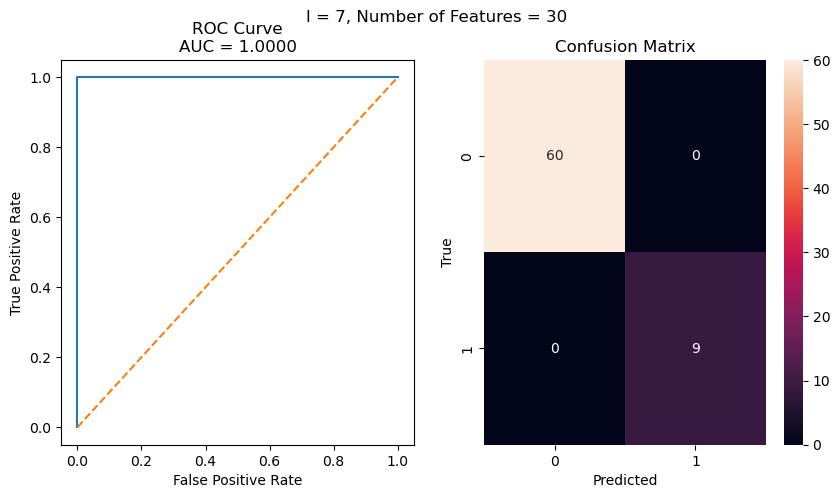

l = 7, Number of Relevant Features = 30, Features:
 Index(['mean_var_rss31', 'std_var_rss31', 'mean_var_rss21', 'std_avg_rss21',
       'mean_avg_rss21', 'mean_avg_rss31', 'std_var_rss21', 'min_var_rss26',
       'median_avg_rss12', 'mean_avg_rss14', 'std_avg_rss23',
       'median_var_rss36', '3rd_quart_var_rss34', '3rd_quart_var_rss27',
       'min_avg_rss17', 'max_avg_rss13', 'mean_var_rss27',
       '1st_quart_var_rss21', 'std_avg_rss11', '3rd_quart_avg_rss33',
       '3rd_quart_avg_rss32', 'max_avg_rss21', 'median_var_rss17',
       'std_avg_rss26', 'std_avg_rss31', 'median_var_rss31',
       '3rd_quart_avg_rss21', 'mean_avg_rss33', 'min_var_rss27',
       'median_var_rss27'],
      dtype='object')
                     Model Params      P-Values
mean_var_rss31          -0.563039  1.522785e-25
std_var_rss31           -0.196213  1.383053e-25
mean_var_rss21          -0.303695  7.893371e-26
std_avg_rss21            1.142088  1.065803e-29
mean_avg_rss21          -1.801986  9.692025e-30

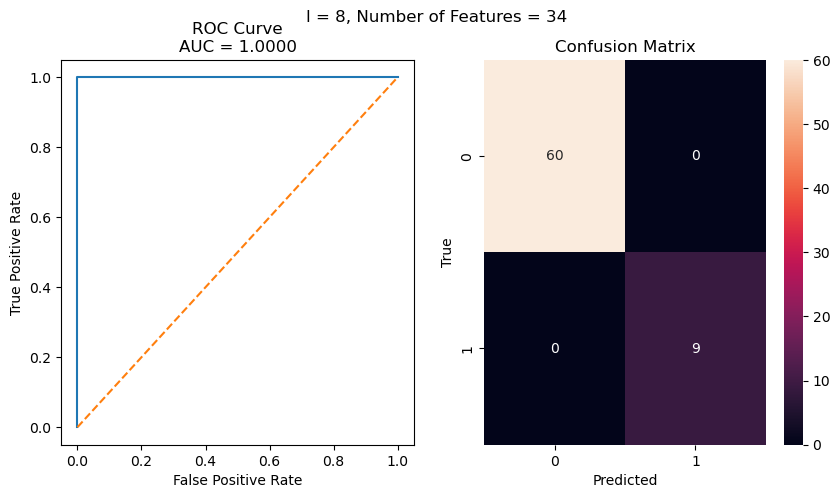

l = 8, Number of Relevant Features = 34, Features:
 Index(['std_var_rss34', 'min_var_rss25', 'mean_var_rss21', 'std_var_rss31',
       'median_var_rss25', 'mean_var_rss31', 'mean_avg_rss21', 'std_avg_rss21',
       'std_var_rss21', 'std_avg_rss34', 'std_avg_rss31', 'min_avg_rss16',
       'std_var_rss24', 'mean_avg_rss31', 'max_avg_rss23', 'min_var_rss36',
       'std_avg_rss26', 'max_avg_rss34', 'median_avg_rss22', 'max_avg_rss21',
       '3rd_quart_avg_rss21', 'min_avg_rss17', '1st_quart_avg_rss22',
       'min_var_rss17', '3rd_quart_avg_rss18', 'median_var_rss28',
       'min_avg_rss31', 'median_avg_rss18', '1st_quart_var_rss38',
       '1st_quart_var_rss21', 'min_avg_rss38', 'max_var_rss11',
       'std_avg_rss18', '1st_quart_avg_rss13'],
      dtype='object')
                     Model Params      P-Values
std_var_rss34           -1.150498  1.287160e-25
min_var_rss25           -0.155896  1.603228e-26
mean_var_rss21          -1.507646  8.079525e-28
std_var_rss31           -0.534973

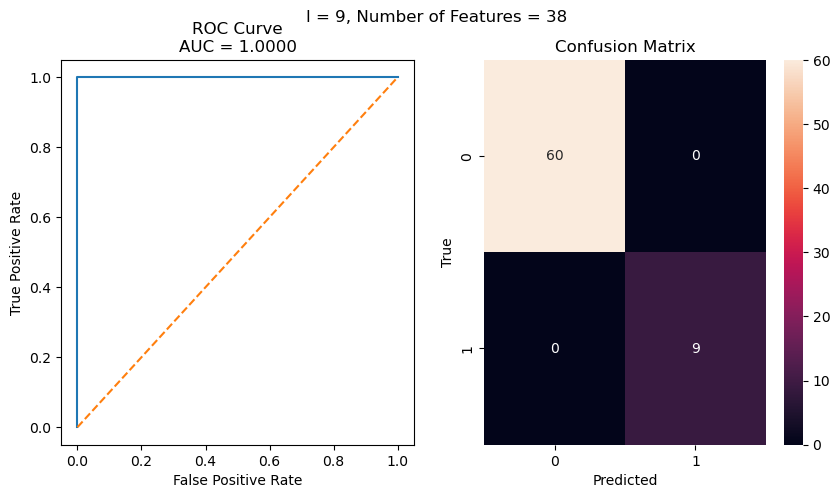

l = 9, Number of Relevant Features = 38, Features:
 Index(['3rd_quart_avg_rss19', 'median_var_rss21', 'mean_var_rss21',
       'std_var_rss31', 'median_var_rss31', 'mean_var_rss31', 'std_avg_rss24',
       'std_avg_rss21', 'std_var_rss33', 'std_var_rss21', 'std_var_rss22',
       'median_avg_rss25', 'mean_avg_rss31', '1st_quart_var_rss23',
       'median_var_rss18', 'mean_avg_rss21', 'max_avg_rss31',
       'median_avg_rss33', 'std_avg_rss31', 'std_var_rss32',
       '3rd_quart_avg_rss11', '3rd_quart_avg_rss21', 'max_avg_rss21',
       'mean_avg_rss15', '3rd_quart_var_rss14', 'median_var_rss14',
       'median_var_rss28', 'std_var_rss38', 'median_var_rss23',
       'mean_var_rss22', 'median_var_rss26', '3rd_quart_avg_rss38',
       'max_var_rss33', 'min_var_rss19', '1st_quart_var_rss21',
       'std_avg_rss11', '3rd_quart_var_rss15', 'max_avg_rss12'],
      dtype='object')
                     Model Params      P-Values
3rd_quart_avg_rss19     -1.347906  2.335057e-23
median_var_rss21  

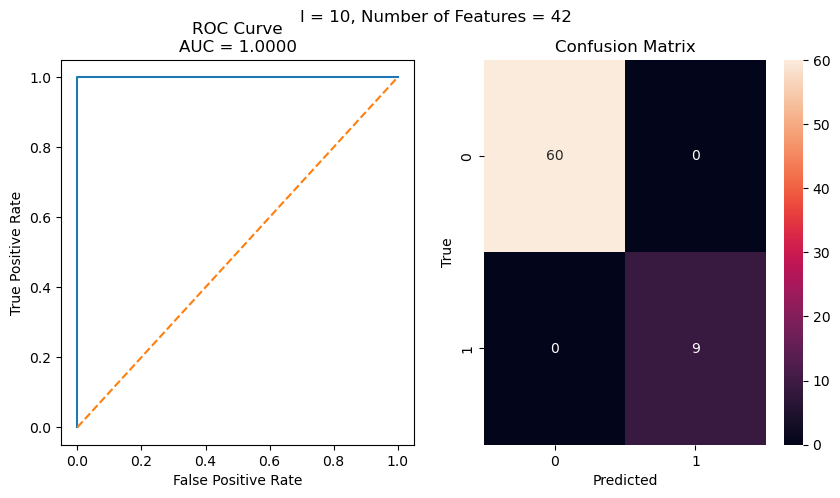

l = 10, Number of Relevant Features = 42, Features:
 Index(['median_var_rss21', 'min_var_rss35', '3rd_quart_var_rss23',
       'std_var_rss31', 'mean_var_rss31', 'min_var_rss28',
       '3rd_quart_avg_rss21', 'mean_avg_rss11', 'std_avg_rss21',
       'median_var_rss210', 'min_var_rss31', 'mean_var_rss12', 'min_var_rss27',
       'max_var_rss19', 'min_avg_rss21', 'mean_var_rss21',
       '1st_quart_var_rss21', 'mean_avg_rss22', 'max_avg_rss37',
       '3rd_quart_avg_rss33', 'min_avg_rss13', 'std_avg_rss29',
       'min_var_rss23', '3rd_quart_var_rss34', 'mean_avg_rss21',
       'min_avg_rss310', 'median_avg_rss210', 'max_avg_rss35',
       '1st_quart_var_rss110', 'min_var_rss15', 'min_avg_rss24',
       'mean_var_rss34', 'median_var_rss27', 'std_var_rss33', 'std_var_rss18',
       'median_var_rss26', 'std_var_rss35', '3rd_quart_var_rss19',
       'std_var_rss39', 'max_var_rss25', 'std_avg_rss18', 'min_var_rss25'],
      dtype='object')
                      Model Params      P-Values
me

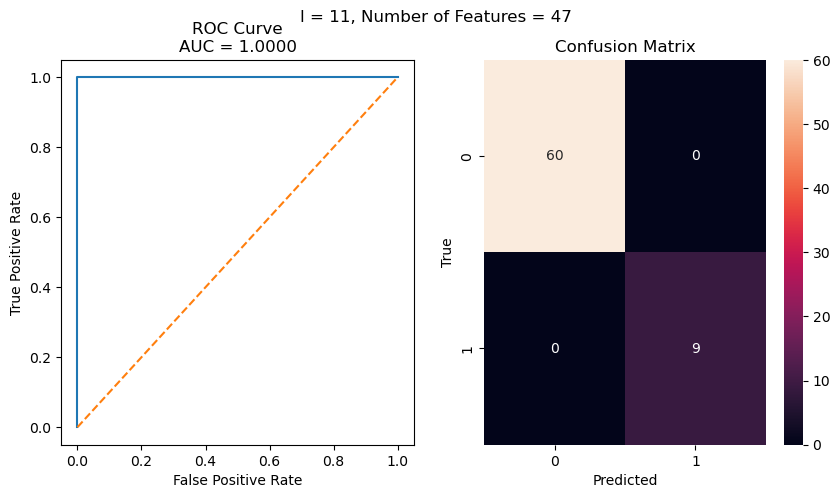

l = 11, Number of Relevant Features = 47, Features:
 Index(['min_avg_rss11', 'median_var_rss21', 'std_avg_rss39', 'max_var_rss36',
       '1st_quart_var_rss12', 'min_avg_rss14', '1st_quart_var_rss31',
       'std_var_rss21', 'median_avg_rss31', 'max_avg_rss35', 'std_avg_rss21',
       'median_var_rss33', '3rd_quart_var_rss310', 'median_avg_rss26',
       '1st_quart_var_rss18', 'min_avg_rss31', 'std_avg_rss22',
       'mean_var_rss11', '3rd_quart_avg_rss37', '1st_quart_avg_rss26',
       'mean_var_rss21', 'min_avg_rss39', '3rd_quart_var_rss23',
       'std_avg_rss31', 'median_var_rss36', 'max_avg_rss32', 'max_avg_rss26',
       'mean_var_rss111', '3rd_quart_var_rss35', 'std_var_rss31',
       'median_var_rss23', 'mean_var_rss31', 'median_var_rss27',
       'min_avg_rss32', 'median_avg_rss27', 'mean_var_rss23',
       'median_var_rss311', '1st_quart_var_rss19', 'median_var_rss38',
       'median_avg_rss34', '3rd_quart_avg_rss11', 'max_avg_rss36',
       'mean_avg_rss310', 'median_avg_rss

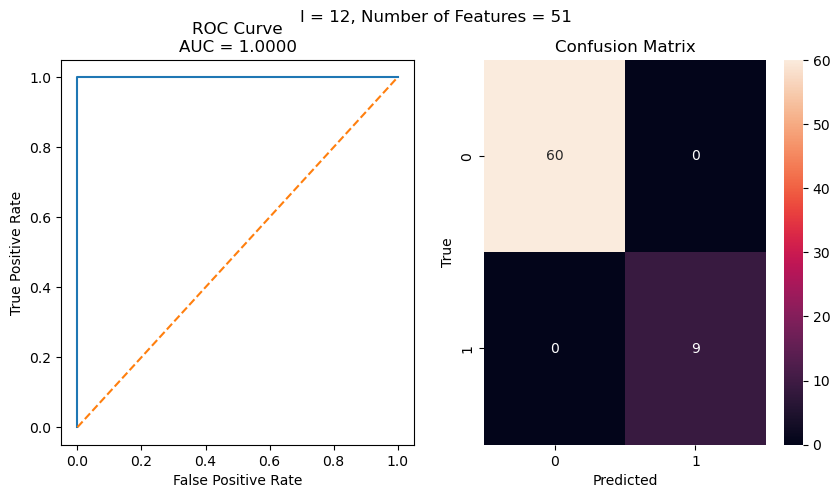

l = 12, Number of Relevant Features = 51, Features:
 Index(['1st_quart_var_rss31', 'mean_avg_rss112', 'median_avg_rss311',
       'min_avg_rss211', 'median_var_rss23', 'max_var_rss21',
       '3rd_quart_var_rss31', 'median_var_rss311', 'min_var_rss28',
       '1st_quart_avg_rss110', '1st_quart_avg_rss16', 'min_var_rss110',
       '1st_quart_avg_rss12', '3rd_quart_var_rss37', '3rd_quart_avg_rss11',
       'mean_var_rss111', 'mean_var_rss31', '3rd_quart_avg_rss26',
       'median_avg_rss14', 'mean_avg_rss37', 'mean_var_rss15', 'min_var_rss23',
       'min_var_rss29', 'median_var_rss15', 'std_avg_rss16',
       'median_avg_rss28', 'mean_avg_rss21', '1st_quart_var_rss310',
       '1st_quart_avg_rss14', 'mean_var_rss21', '3rd_quart_var_rss36',
       'median_var_rss24', 'min_var_rss36', 'std_avg_rss31',
       '1st_quart_var_rss36', 'max_avg_rss31', 'min_avg_rss32',
       'max_avg_rss210', 'std_var_rss31', 'mean_avg_rss35', 'min_var_rss35',
       'median_avg_rss110', 'min_avg_rss310', '3r

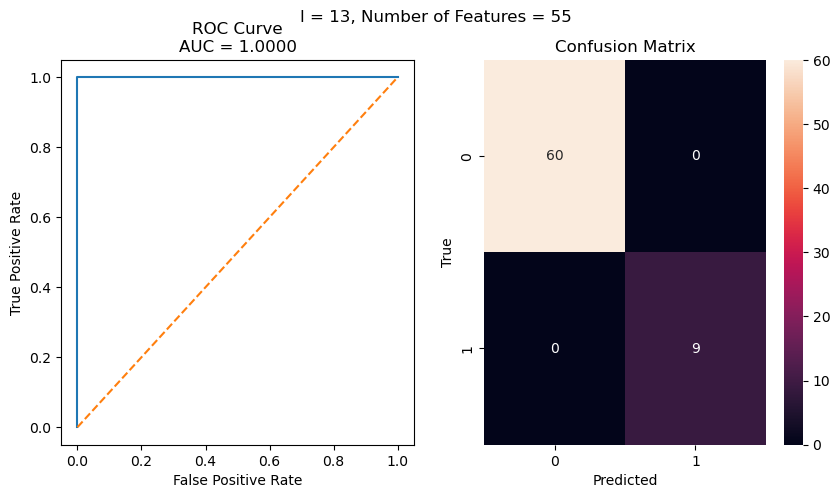

l = 13, Number of Relevant Features = 55, Features:
 Index(['3rd_quart_var_rss21', 'mean_var_rss21', 'min_var_rss23',
       'min_var_rss16', 'std_var_rss21', 'std_var_rss17', 'std_avg_rss21',
       'mean_var_rss31', 'mean_avg_rss36', 'std_var_rss31',
       '3rd_quart_var_rss29', '3rd_quart_avg_rss27', 'mean_avg_rss38',
       'mean_var_rss29', 'min_var_rss211', '1st_quart_var_rss26',
       'std_var_rss23', 'min_avg_rss313', 'std_var_rss26', 'min_avg_rss23',
       'std_var_rss19', 'mean_var_rss22', 'max_var_rss18',
       '1st_quart_var_rss32', '1st_quart_var_rss21', 'min_avg_rss24',
       '1st_quart_avg_rss12', '3rd_quart_avg_rss38', 'min_var_rss310',
       'min_avg_rss38', '3rd_quart_var_rss38', '3rd_quart_var_rss22',
       'min_var_rss39', 'median_var_rss13', 'mean_var_rss211', 'max_var_rss27',
       '3rd_quart_avg_rss211', 'median_var_rss29', 'max_avg_rss111',
       'median_avg_rss211', 'median_var_rss212', 'min_var_rss33',
       '3rd_quart_var_rss35', 'min_var_rss29', 'm

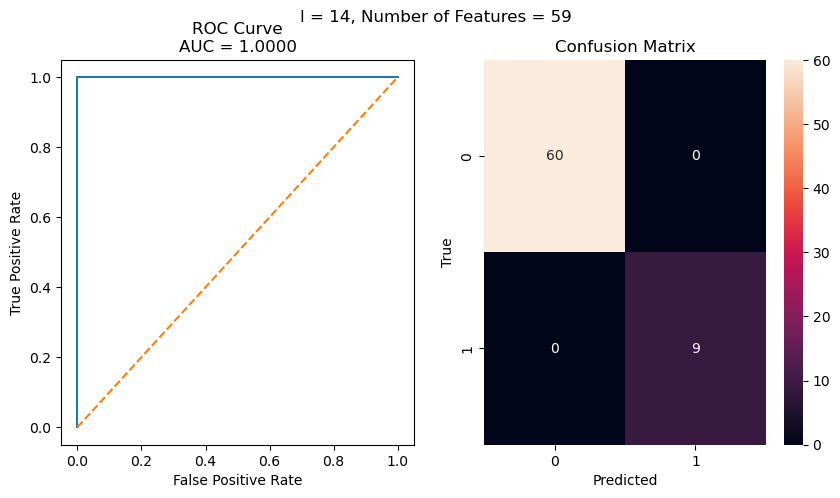

l = 14, Number of Relevant Features = 59, Features:
 Index(['median_var_rss21', 'std_avg_rss34', '3rd_quart_var_rss21',
       'median_var_rss212', 'max_avg_rss111', 'std_var_rss21',
       'median_var_rss31', 'mean_var_rss21', '3rd_quart_var_rss31',
       'std_var_rss29', 'std_var_rss31', 'max_var_rss18', 'median_var_rss13',
       'min_var_rss11', 'median_var_rss311', 'mean_var_rss31',
       'std_var_rss113', '3rd_quart_var_rss24', 'min_var_rss17',
       '1st_quart_avg_rss310', '3rd_quart_avg_rss12', 'min_var_rss211',
       'std_avg_rss21', '1st_quart_avg_rss17', 'min_var_rss33',
       'std_var_rss39', 'max_avg_rss18', 'min_var_rss37', 'median_avg_rss22',
       'std_var_rss213', 'median_var_rss26', '3rd_quart_var_rss313',
       'max_avg_rss19', 'mean_var_rss110', 'median_avg_rss35', 'std_avg_rss11',
       'min_avg_rss27', 'std_var_rss35', 'median_var_rss24', 'min_var_rss311',
       'max_var_rss39', 'std_var_rss110', 'mean_var_rss312', 'mean_var_rss313',
       'std_avg_rss13

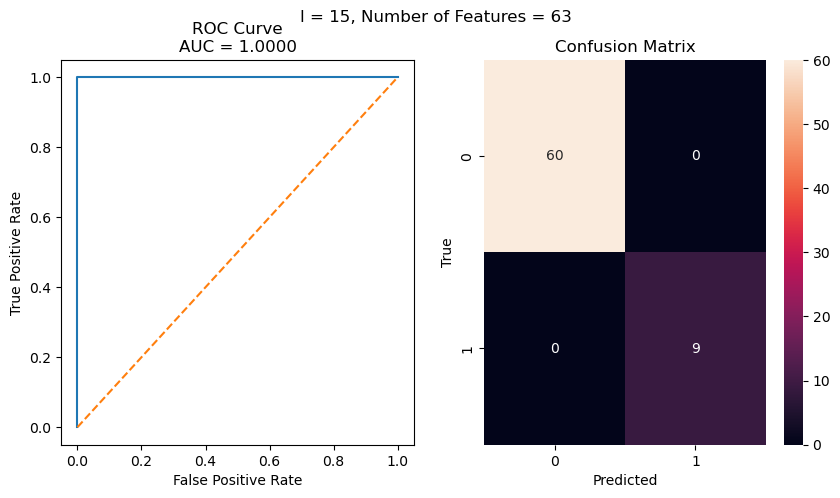

l = 15, Number of Relevant Features = 63, Features:
 Index(['std_var_rss21', '1st_quart_avg_rss110', 'mean_var_rss21',
       'median_var_rss21', '3rd_quart_var_rss21', 'min_var_rss34',
       '1st_quart_var_rss36', 'mean_var_rss26', 'std_var_rss31',
       'max_var_rss19', 'median_var_rss31', '3rd_quart_var_rss28',
       'mean_var_rss31', 'median_var_rss313', 'mean_var_rss32',
       '3rd_quart_var_rss111', 'median_var_rss34', 'median_var_rss212',
       '3rd_quart_var_rss27', 'mean_var_rss34', '3rd_quart_var_rss19',
       'min_var_rss214', 'mean_var_rss311', 'max_avg_rss31',
       'median_avg_rss115', 'median_avg_rss28', 'mean_var_rss210',
       'std_avg_rss113', '3rd_quart_var_rss212', '3rd_quart_var_rss310',
       'mean_avg_rss22', 'mean_var_rss36', 'median_var_rss214',
       '3rd_quart_avg_rss17', 'median_avg_rss36', 'min_var_rss37',
       'max_var_rss26', 'median_var_rss28', 'std_avg_rss21',
       'median_var_rss23', 'min_avg_rss24', 'min_avg_rss112',
       'mean_var_rss

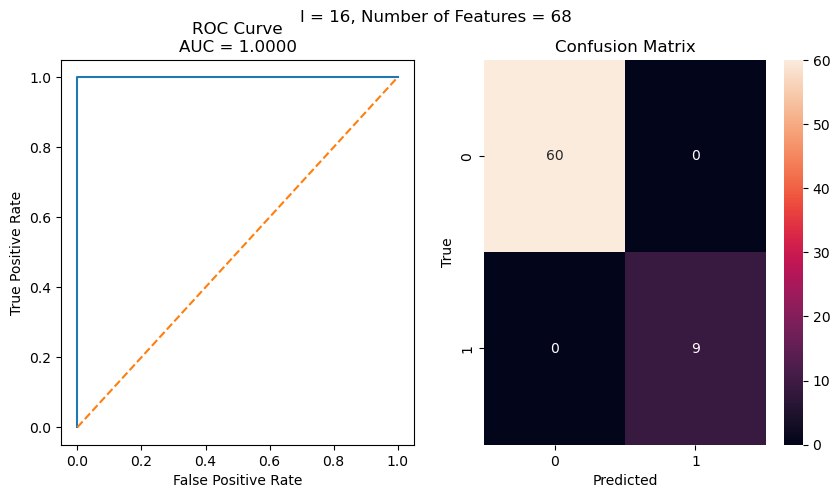

l = 16, Number of Relevant Features = 68, Features:
 Index(['median_var_rss21', 'std_var_rss31', '3rd_quart_var_rss21',
       'min_var_rss26', 'mean_var_rss21', 'median_var_rss215',
       '3rd_quart_avg_rss18', 'std_var_rss21', 'median_var_rss31',
       'std_var_rss37', 'median_var_rss26', 'mean_var_rss31',
       '1st_quart_avg_rss13', '1st_quart_var_rss29', '3rd_quart_var_rss215',
       'median_avg_rss115', 'max_var_rss31', 'mean_var_rss35', 'std_avg_rss11',
       'std_avg_rss31', 'mean_var_rss27', 'max_var_rss27', 'max_avg_rss18',
       'mean_var_rss18', 'mean_var_rss316', 'mean_avg_rss22', 'min_avg_rss35',
       'median_avg_rss39', 'min_var_rss210', '3rd_quart_var_rss213',
       '1st_quart_var_rss315', '3rd_quart_var_rss12', 'mean_avg_rss21',
       'mean_var_rss29', 'min_var_rss112', '3rd_quart_var_rss27',
       'mean_var_rss24', 'max_var_rss36', 'min_var_rss311', 'min_var_rss21',
       'max_var_rss112', 'median_var_rss33', 'median_var_rss35',
       'min_var_rss212', 'm

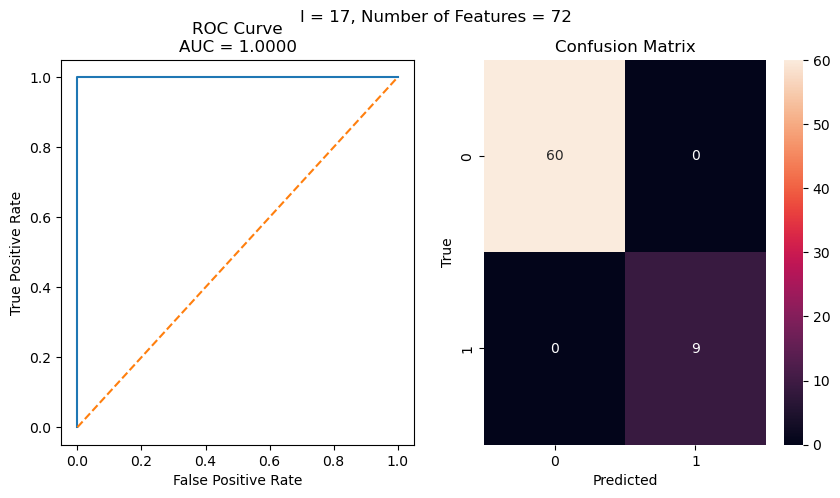

l = 17, Number of Relevant Features = 72, Features:
 Index(['median_var_rss21', '3rd_quart_var_rss21', 'min_avg_rss31',
       'min_var_rss27', 'min_avg_rss12', 'median_var_rss31', 'max_var_rss19',
       'mean_var_rss21', 'median_var_rss29', 'std_var_rss21', 'mean_var_rss31',
       'max_var_rss214', 'std_var_rss115', 'std_var_rss31',
       '1st_quart_var_rss33', 'min_var_rss213', 'median_avg_rss14',
       '1st_quart_avg_rss314', '3rd_quart_var_rss39', 'median_var_rss23',
       '3rd_quart_var_rss28', 'min_avg_rss212', '3rd_quart_var_rss27',
       '1st_quart_var_rss23', 'mean_avg_rss21', 'std_avg_rss115',
       'std_avg_rss112', 'min_avg_rss210', '3rd_quart_var_rss25',
       'min_var_rss117', 'std_avg_rss21', 'std_var_rss112',
       'median_var_rss316', 'mean_var_rss29', 'std_avg_rss17', 'std_var_rss18',
       '3rd_quart_var_rss17', 'max_avg_rss29', 'median_var_rss215',
       'median_avg_rss13', '3rd_quart_var_rss213', 'min_avg_rss111',
       'mean_var_rss117', 'min_var_rss14

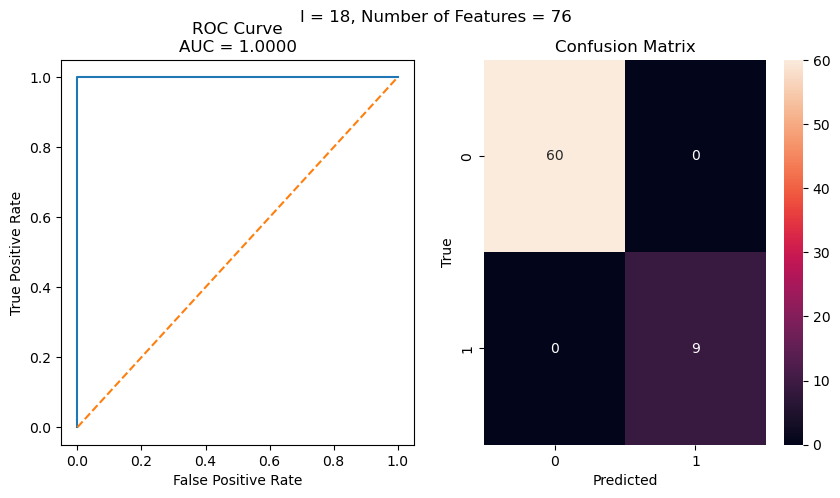

l = 18, Number of Relevant Features = 76, Features:
 Index(['std_avg_rss31', '3rd_quart_var_rss21', 'std_var_rss31',
       'mean_var_rss21', 'std_var_rss21', 'mean_var_rss313',
       '1st_quart_var_rss21', 'mean_var_rss31', 'median_var_rss37',
       'max_var_rss36', 'mean_var_rss34', 'median_avg_rss28', 'mean_avg_rss31',
       'max_var_rss315', 'std_avg_rss21', 'min_avg_rss29', 'mean_avg_rss216',
       'min_avg_rss28', 'mean_avg_rss21', 'min_avg_rss114', 'min_var_rss214',
       '3rd_quart_var_rss15', 'mean_avg_rss215', 'median_avg_rss11',
       'min_avg_rss313', 'max_var_rss110', 'mean_var_rss13',
       'median_var_rss318', 'max_var_rss17', 'median_avg_rss317',
       'median_var_rss117', '1st_quart_var_rss38', '1st_quart_var_rss24',
       'max_avg_rss114', 'min_avg_rss26', 'max_var_rss21',
       '1st_quart_avg_rss211', 'std_var_rss32', '3rd_quart_avg_rss31',
       'max_avg_rss34', 'median_var_rss27', 'min_avg_rss213',
       '3rd_quart_avg_rss11', 'min_var_rss215', 'std_avg

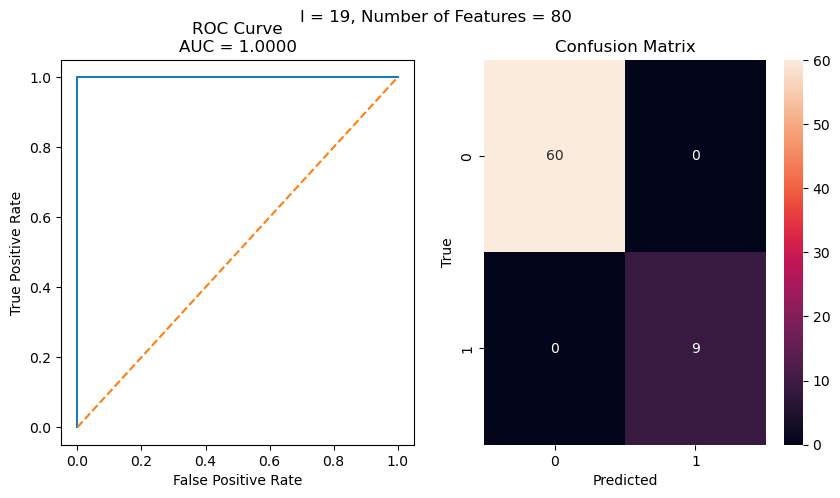

l = 19, Number of Relevant Features = 80, Features:
 Index(['std_var_rss21', 'mean_var_rss21', 'min_var_rss28',
       '3rd_quart_var_rss21', 'min_var_rss37', 'std_var_rss29',
       '1st_quart_var_rss119', 'std_var_rss31', 'median_var_rss31',
       'mean_var_rss31', 'min_var_rss110', 'std_var_rss16',
       'median_avg_rss119', 'std_var_rss14', '3rd_quart_var_rss113',
       '1st_quart_avg_rss35', 'median_avg_rss115', 'mean_avg_rss21',
       'min_var_rss29', '3rd_quart_var_rss317', 'std_avg_rss21',
       'std_avg_rss31', '3rd_quart_var_rss16', 'std_var_rss11',
       'median_avg_rss216', 'min_var_rss311', '1st_quart_var_rss219',
       'median_avg_rss21', '3rd_quart_var_rss118', 'std_var_rss112',
       'std_avg_rss111', 'mean_var_rss15', 'mean_avg_rss31', 'max_var_rss112',
       'std_var_rss18', 'std_avg_rss315', '3rd_quart_var_rss212',
       'max_var_rss210', 'median_var_rss17', 'median_avg_rss24',
       'mean_var_rss16', 'mean_var_rss210', 'std_avg_rss32', 'max_avg_rss15',
  

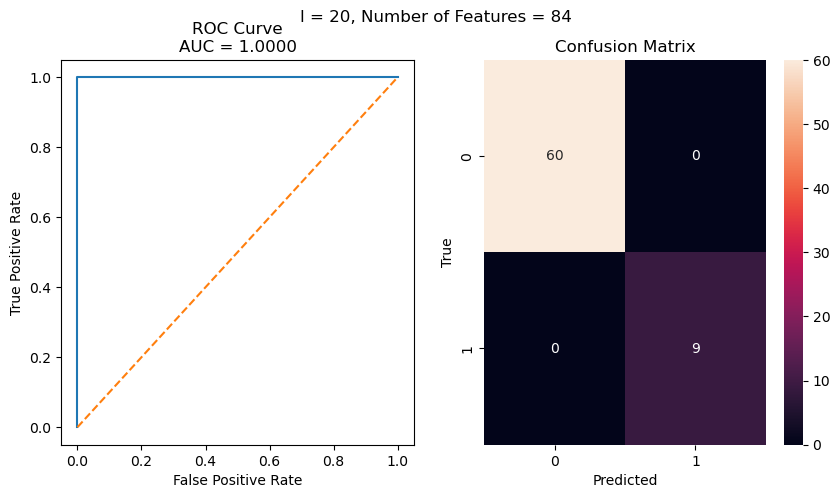

l = 20, Number of Relevant Features = 84, Features:
 Index(['mean_var_rss21', 'std_var_rss21', '3rd_quart_var_rss21',
       'median_var_rss31', 'std_avg_rss31', 'std_var_rss215', 'std_var_rss31',
       'mean_var_rss31', '1st_quart_var_rss25', 'std_avg_rss21',
       'std_avg_rss114', '3rd_quart_avg_rss218', 'mean_avg_rss31',
       'mean_avg_rss21', 'mean_var_rss23', '3rd_quart_avg_rss311',
       'std_var_rss34', 'min_var_rss14', 'max_var_rss17', 'median_var_rss114',
       'std_var_rss313', 'median_avg_rss110', 'mean_var_rss33',
       'std_var_rss32', '3rd_quart_avg_rss35', 'mean_var_rss17',
       '3rd_quart_var_rss17', 'std_avg_rss14', 'mean_var_rss110',
       'min_var_rss23', 'min_var_rss11', 'mean_var_rss118', 'mean_avg_rss314',
       'max_avg_rss117', '1st_quart_avg_rss12', '3rd_quart_var_rss36',
       'max_var_rss215', 'median_var_rss29', 'min_var_rss33', 'min_var_rss320',
       'max_var_rss110', 'mean_var_rss29', 'max_var_rss312', 'min_var_rss119',
       'mean_var_rss1

In [8]:
X_reduced_train = {}
X_reduced_test = {}
model = LogisticRegression(penalty=None, max_iter=100)

for l in range(1, 21, 1): 
    model_statsmodels = sm.OLS(Y_train, X_train[l])
    results = model_statsmodels.fit()    
    p = results.pvalues
    indicies = [i for i in range(len(p)) if p.iloc[i] >= 0.05]
    if indicies == []:
        print("*********************************************")
        print(f'No Feature with P-Value >= 0.05 for l = {l}')
        print("choosing feature with top 10% P-Values")
        indicies = np.argsort(-p)[:int(np.ceil(len(p)/10))]

    p = p.iloc[indicies]
    X_reduced_train[l] = X_train[l].iloc[:, indicies]
    X_reduced_test[l] = X_test[l].iloc[:, indicies]
    if l == 1:
        pca_indicies = indicies

    model.fit(X_reduced_train[l], Y_train)
    Y_pred = model.predict(X_reduced_train[l])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f'l = {l}, Number of Features = {len(indicies)}')
    FPR, TPR, thresholds = roc_curve(Y_train, Y_pred) 
    ax1.plot(FPR, TPR)
    ax1.plot([0, 1], [0, 1], linestyle = '--')  
    ax1.set(xlabel="False Positive Rate", ylabel="True Positive Rate")
    ax1.set_title(f'ROC Curve\nAUC = {roc_auc_score(Y_train, Y_pred):.4f}')
    sns.heatmap(confusion_matrix(Y_train, Y_pred), annot=True)
    ax2.set(xlabel="Predicted", ylabel="True")
    ax2.set_title("Confusion Matrix")
    plt.show()
    
    print(f'l = {l}, Number of Relevant Features = {len(indicies)}, Features:\n', X_reduced_train[l].columns)
    print(pd.DataFrame({"Model Params": model.coef_[0], "P-Values": p}))

In [9]:
for l in range(1, 21, 1):
    print(f'l = {l}')
    print("Cross Validation Scores:", cross_val_score(model, X_reduced_train[l], Y_train, cv=5))
    model.fit(X_reduced_train[l], Y_train)
    Y_pred = model.predict(X_reduced_test[l])
    print(f'Test Accuracy: {accuracy_score(Y_test, Y_pred):.4f}')


l = 1
Cross Validation Scores: [0.85714286 1.         0.92857143 0.92857143 1.        ]
Test Accuracy: 1.0000
l = 2
Cross Validation Scores: [0.85714286 1.         0.35714286 0.64285714 0.92307692]
Test Accuracy: 0.7895
l = 3


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-

Cross Validation Scores: [0.85714286 1.         0.64285714 0.92857143 1.        ]
Test Accuracy: 0.9474
l = 4
Cross Validation Scores: [0.92857143 0.78571429 0.35714286 0.78571429 0.92307692]
Test Accuracy: 0.9474
l = 5
Cross Validation Scores: [0.85714286 1.         0.85714286 0.92857143 1.        ]
Test Accuracy: 1.0000
l = 6
Cross Validation Scores: [0.92857143 0.85714286 0.71428571 0.71428571 0.92307692]
Test Accuracy: 0.8947
l = 7
Cross Validation Scores: [0.85714286 1.         0.85714286 0.85714286 1.        ]
Test Accuracy: 1.0000
l = 8
Cross Validation Scores: [0.85714286 1.         0.85714286 0.71428571 1.        ]
Test Accuracy: 0.9474
l = 9
Cross Validation Scores: [0.92857143 1.         0.92857143 1.         1.        ]
Test Accuracy: 0.9474
l = 10
Cross Validation Scores: [0.85714286 1.         0.85714286 0.92857143 1.        ]
Test Accuracy: 0.9474
l = 11
Cross Validation Scores: [0.92857143 1.         0.92857143 1.         1.        ]
Test Accuracy: 1.0000
l = 12
Cross V

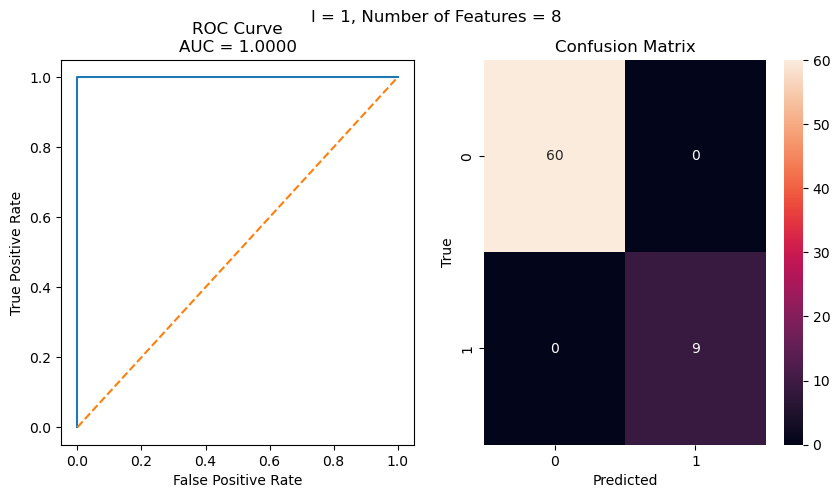

l = 1, Number of Relevant Features = 8, Features:
 Index(['mean_avg_rss11', '1st_quart_avg_rss11', '3rd_quart_avg_rss11',
       'max_var_rss11', 'median_avg_rss21', 'min_avg_rss31', 'max_avg_rss31',
       '1st_quart_avg_rss31'],
      dtype='object')
   Model Params
0     -0.082179
1     -0.078559
2     -0.400251
3     -0.380053
4     -0.000030
5      0.441105
6      0.584879
7      0.206547


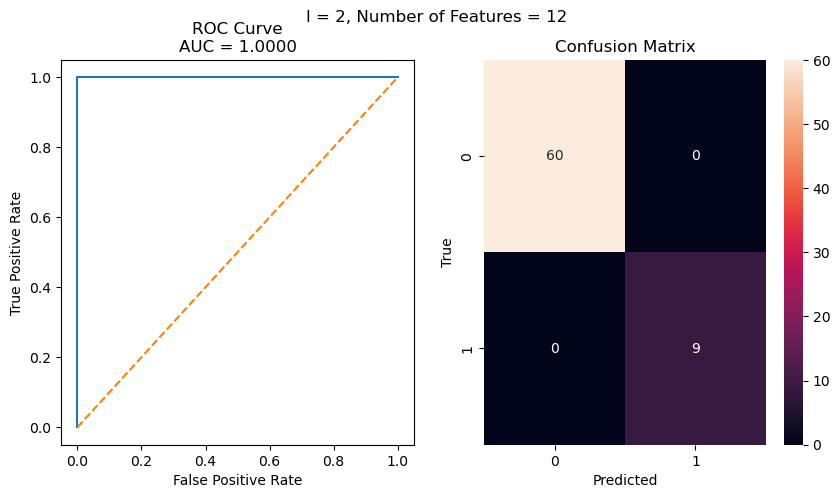

l = 2, Number of Relevant Features = 12, Features:
 Index(['median_avg_rss11', '1st_quart_avg_rss11', 'max_var_rss11',
       '1st_quart_avg_rss21', 'min_avg_rss31', 'max_avg_rss31',
       'max_avg_rss12', 'median_avg_rss12', '3rd_quart_avg_rss12',
       'max_var_rss12', 'min_avg_rss32', '1st_quart_avg_rss32'],
      dtype='object')
    Model Params
0      -0.221749
1      -0.029192
2      -0.337857
3      -0.048074
4       0.488541
5       0.508783
6      -0.037688
7      -0.150087
8      -0.048585
9      -0.125354
10      0.022175
11      0.150408


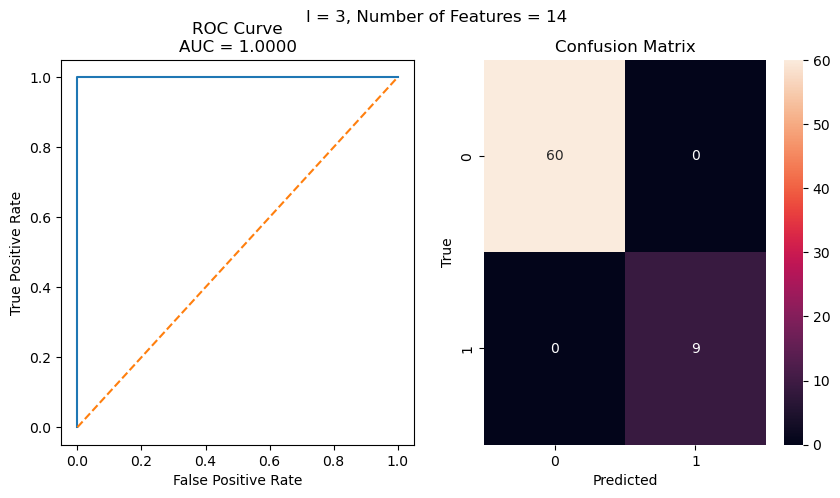

l = 3, Number of Relevant Features = 14, Features:
 Index(['median_avg_rss11', '3rd_quart_avg_rss11', 'max_var_rss11',
       '1st_quart_avg_rss21', 'min_avg_rss31', 'max_avg_rss31',
       '3rd_quart_avg_rss31', 'max_avg_rss12', '3rd_quart_avg_rss12',
       'min_avg_rss32', 'max_avg_rss13', 'max_var_rss13', 'min_avg_rss33',
       'max_var_rss33'],
      dtype='object')
    Model Params
0      -0.071573
1      -0.038809
2      -0.386865
3      -0.059897
4       0.172736
5       0.497836
6       0.126392
7      -0.068251
8      -0.204059
9       0.064038
10     -0.054221
11     -0.007369
12      0.084560
13     -0.005160


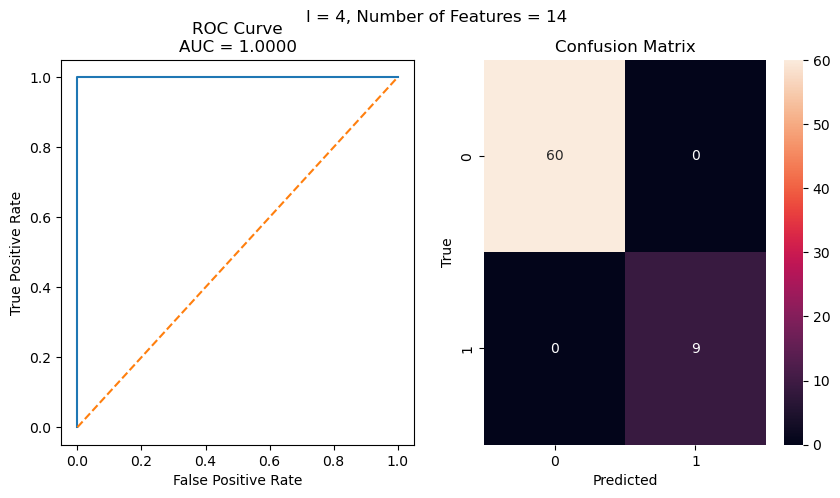

l = 4, Number of Relevant Features = 14, Features:
 Index(['max_avg_rss11', '3rd_quart_avg_rss11', 'max_var_rss11',
       '1st_quart_avg_rss21', 'max_avg_rss31', 'mean_avg_rss31',
       '1st_quart_avg_rss31', '3rd_quart_avg_rss31', 'max_avg_rss12',
       'median_avg_rss13', '1st_quart_avg_rss13', '3rd_quart_avg_rss13',
       'min_avg_rss33', 'max_var_rss33'],
      dtype='object')
    Model Params
0      -0.049119
1      -0.043616
2      -0.226747
3      -0.123689
4       0.405980
5       0.006577
6       0.017167
7       0.285172
8      -0.009848
9      -0.081341
10     -0.079354
11     -0.185424
12      0.161956
13     -0.147363


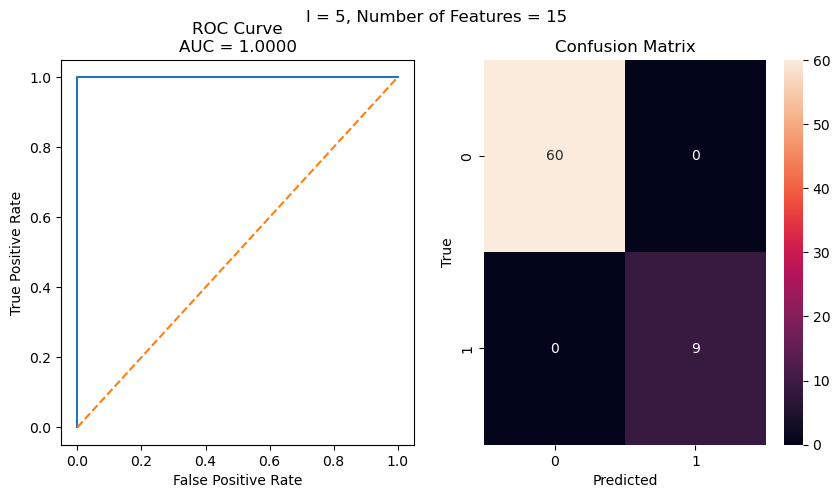

l = 5, Number of Relevant Features = 15, Features:
 Index(['min_avg_rss21', 'median_avg_rss21', 'min_avg_rss31', 'max_avg_rss31',
       'mean_avg_rss31', '3rd_quart_avg_rss31', 'max_var_rss12',
       'min_avg_rss32', 'max_avg_rss13', '3rd_quart_avg_rss13',
       'max_avg_rss14', '3rd_quart_avg_rss14', 'max_var_rss14',
       'min_avg_rss34', '1st_quart_avg_rss35'],
      dtype='object')
    Model Params
0      -0.150227
1      -0.000137
2       0.074698
3       0.205289
4       0.121435
5       0.357986
6      -0.208057
7       0.029742
8      -0.079554
9      -0.213772
10     -0.029801
11     -0.145813
12     -0.000437
13      0.030658
14      0.125857


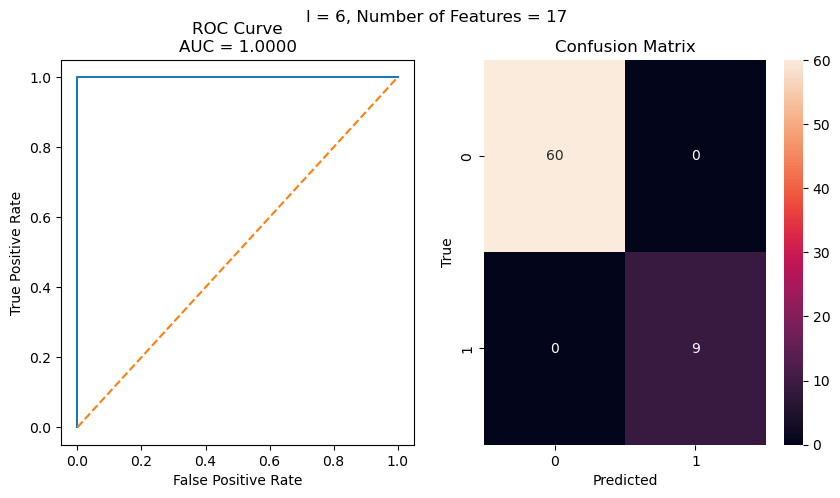

l = 6, Number of Relevant Features = 17, Features:
 Index(['max_avg_rss11', '3rd_quart_avg_rss11', 'min_avg_rss21',
       'min_avg_rss31', 'max_avg_rss31', 'mean_avg_rss31',
       '3rd_quart_avg_rss31', 'max_var_rss12', 'min_avg_rss32',
       'max_avg_rss32', 'max_avg_rss13', 'median_avg_rss14',
       '3rd_quart_avg_rss14', 'min_avg_rss34', '3rd_quart_avg_rss15',
       'max_var_rss16', '1st_quart_avg_rss36'],
      dtype='object')
    Model Params
0      -0.052653
1      -0.019769
2      -0.080617
3       0.030445
4       0.143550
5       0.083892
6       0.216466
7      -0.228761
8       0.116129
9       0.148253
10     -0.039671
11     -0.133452
12     -0.086863
13      0.130712
14     -0.122539
15     -0.062636
16      0.081359


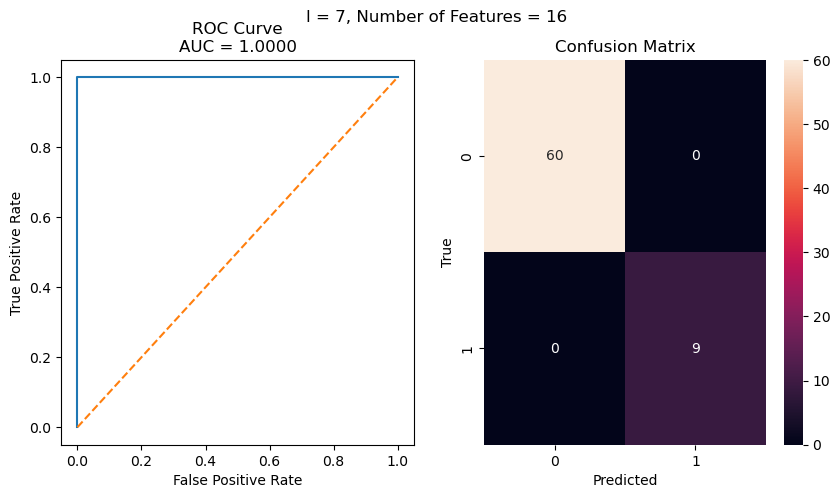

l = 7, Number of Relevant Features = 16, Features:
 Index(['max_avg_rss11', '3rd_quart_avg_rss11', 'min_avg_rss21',
       'max_avg_rss31', '3rd_quart_avg_rss31', 'max_var_rss12',
       'min_avg_rss32', 'max_avg_rss32', 'max_avg_rss14',
       '3rd_quart_avg_rss14', 'max_var_rss14', 'max_avg_rss15',
       '3rd_quart_avg_rss15', 'min_avg_rss35', 'min_avg_rss36',
       '1st_quart_avg_rss37'],
      dtype='object')
    Model Params
0      -0.044811
1      -0.002303
2      -0.079970
3       0.175286
4       0.271470
5      -0.132747
6       0.196406
7       0.106615
8      -0.152823
9      -0.086186
10     -0.006737
11     -0.095399
12     -0.080247
13      0.072657
14      0.123094
15      0.050528


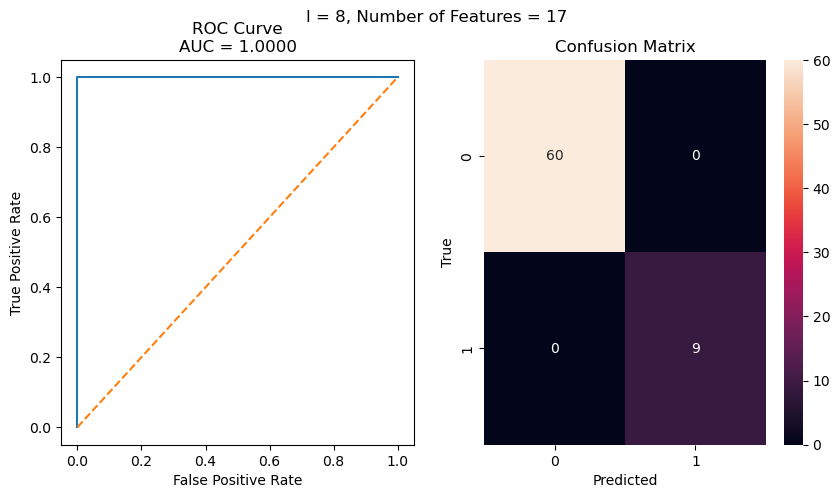

l = 8, Number of Relevant Features = 17, Features:
 Index(['max_avg_rss11', 'max_avg_rss31', '3rd_quart_avg_rss31',
       'max_var_rss12', 'min_avg_rss22', 'max_avg_rss32', 'mean_avg_rss32',
       '3rd_quart_avg_rss32', 'min_avg_rss33', 'max_avg_rss15',
       'median_avg_rss15', '3rd_quart_avg_rss15', 'min_avg_rss35',
       'max_avg_rss16', '3rd_quart_avg_rss16', 'max_var_rss16',
       'min_avg_rss37'],
      dtype='object')
    Model Params
0      -0.042053
1       0.143393
2       0.090356
3      -0.044354
4      -0.001871
5       0.117610
6       0.013063
7       0.219005
8       0.140340
9      -0.004207
10     -0.103469
11     -0.131279
12      0.000562
13     -0.112939
14     -0.083325
15     -0.197627
16      0.255821


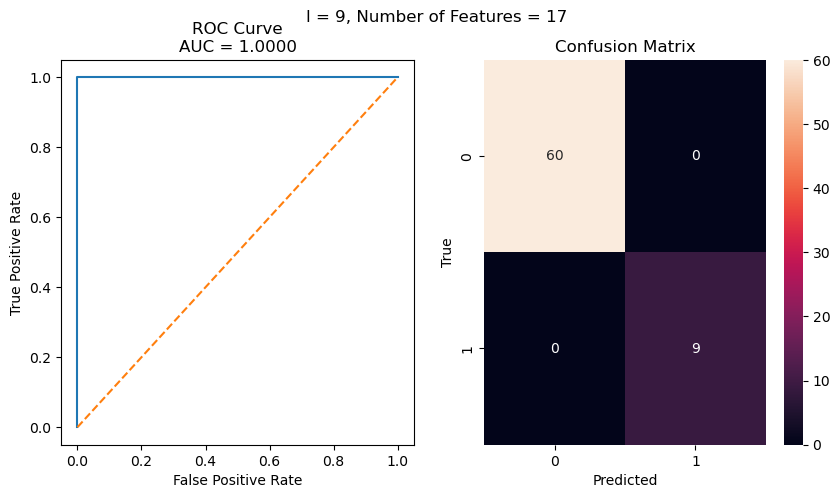

l = 9, Number of Relevant Features = 17, Features:
 Index(['max_avg_rss11', 'max_avg_rss31', 'max_avg_rss32', 'mean_avg_rss32',
       'median_avg_rss32', '1st_quart_avg_rss32', '3rd_quart_avg_rss32',
       'min_avg_rss33', 'max_avg_rss15', '3rd_quart_avg_rss15',
       'max_var_rss15', 'max_avg_rss16', '3rd_quart_avg_rss16',
       'max_avg_rss17', '3rd_quart_avg_rss17', 'max_var_rss17',
       'min_avg_rss38'],
      dtype='object')
    Model Params
0      -0.033100
1       0.161882
2       0.007163
3       0.037098
4       0.302547
5       0.024538
6       0.103564
7       0.109319
8      -0.229782
9      -0.016082
10     -0.086608
11     -0.022706
12     -0.018126
13     -0.087697
14     -0.063029
15     -0.000959
16      0.245194


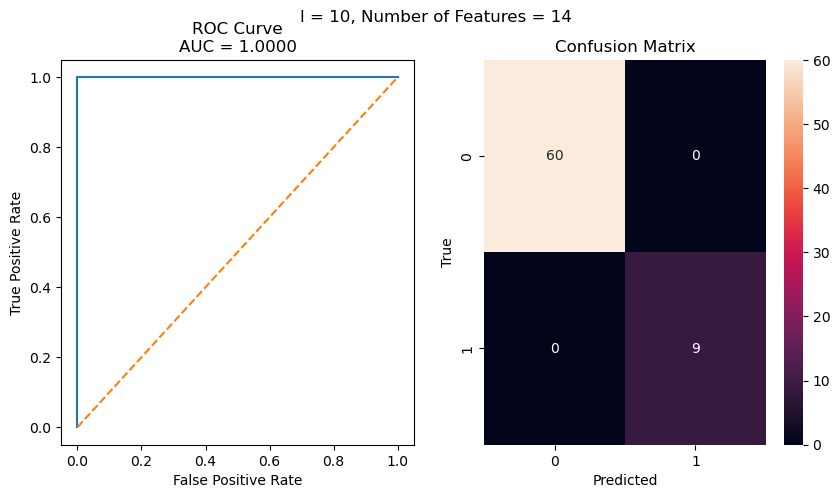

l = 10, Number of Relevant Features = 14, Features:
 Index(['max_avg_rss11', 'max_avg_rss31', 'median_avg_rss32',
       '1st_quart_avg_rss32', '3rd_quart_avg_rss32', 'min_avg_rss14',
       '1st_quart_avg_rss24', 'max_avg_rss15', 'max_avg_rss16',
       'median_avg_rss16', '3rd_quart_avg_rss16', 'max_avg_rss18',
       '3rd_quart_avg_rss18', 'min_avg_rss39'],
      dtype='object')
    Model Params
0      -0.035358
1       0.125825
2       0.135990
3       0.362641
4       0.049114
5       0.062620
6      -0.007765
7      -0.090811
8      -0.094419
9      -0.014657
10     -0.118458
11     -0.119011
12     -0.036492
13      0.290510


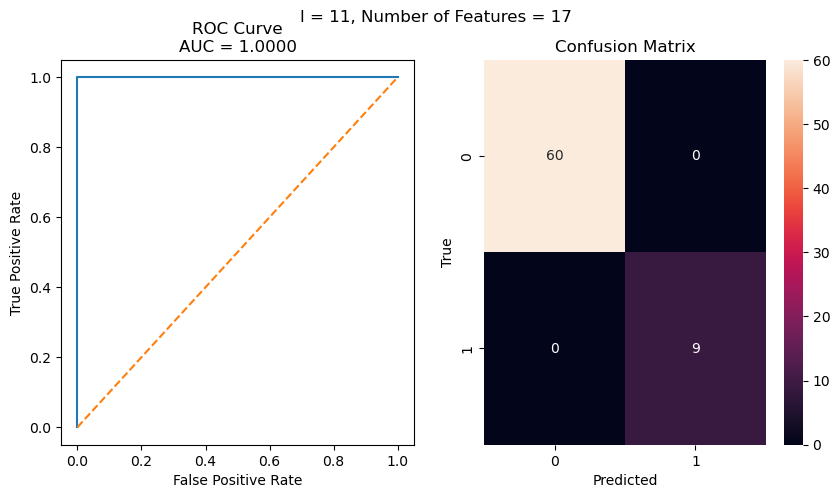

l = 11, Number of Relevant Features = 17, Features:
 Index(['max_avg_rss31', 'max_avg_rss12', 'min_avg_rss32', 'mean_avg_rss32',
       'median_avg_rss32', '1st_quart_avg_rss32', 'max_var_rss13',
       'min_avg_rss34', 'max_avg_rss16', 'median_avg_rss17',
       '3rd_quart_avg_rss17', 'max_avg_rss18', '3rd_quart_avg_rss18',
       '3rd_quart_avg_rss19', 'min_avg_rss110', 'max_avg_rss210',
       'min_avg_rss310'],
      dtype='object')
    Model Params
0       0.042893
1      -0.050819
2       0.120781
3       0.071809
4       0.153724
5       0.271819
6      -0.020101
7       0.013432
8      -0.167179
9      -0.033104
10     -0.062206
11     -0.071317
12     -0.025828
13     -0.032826
14      0.033773
15     -0.023130
16      0.268068


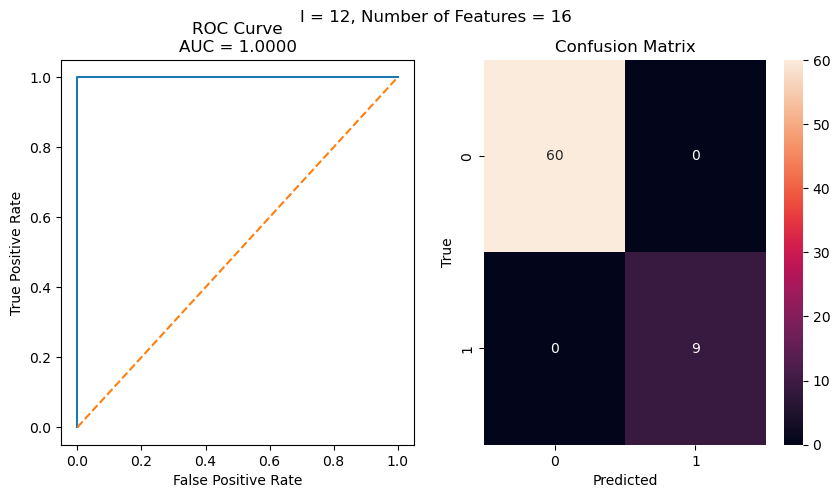

l = 12, Number of Relevant Features = 16, Features:
 Index(['max_avg_rss31', 'max_avg_rss12', 'min_avg_rss32', 'mean_avg_rss32',
       'median_avg_rss32', '1st_quart_avg_rss32', 'min_avg_rss34',
       'max_avg_rss16', 'max_avg_rss17', '3rd_quart_avg_rss17',
       'max_avg_rss18', '3rd_quart_avg_rss18', 'max_avg_rss19',
       '3rd_quart_avg_rss19', 'max_avg_rss211', 'min_avg_rss311'],
      dtype='object')
    Model Params
0       0.000172
1      -0.026875
2       0.177028
3       0.045455
4       0.096146
5       0.301126
6       0.097998
7      -0.080238
8      -0.109405
9      -0.045150
10     -0.055050
11     -0.012370
12     -0.049388
13     -0.013017
14     -0.042709
15      0.242257


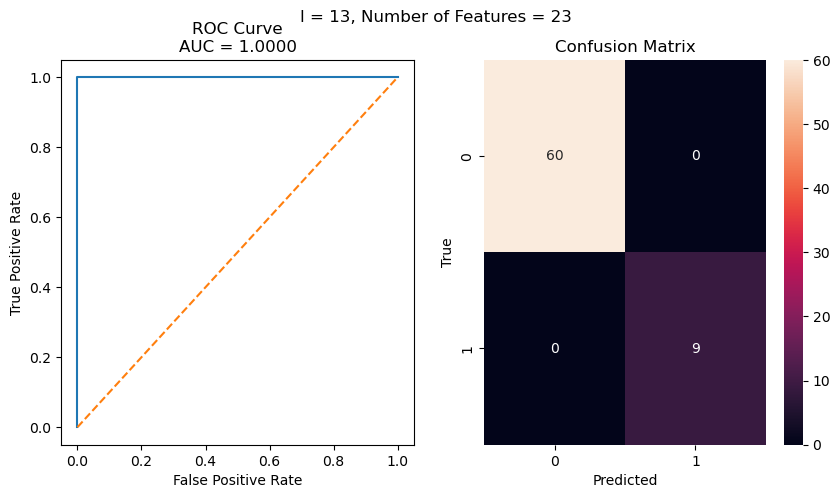

l = 13, Number of Relevant Features = 23, Features:
 Index(['max_avg_rss11', 'max_avg_rss12', 'min_avg_rss32', 'mean_avg_rss32',
       'median_avg_rss32', '1st_quart_avg_rss32', '3rd_quart_avg_rss32',
       'max_avg_rss14', 'min_avg_rss34', 'max_avg_rss16', 'max_avg_rss26',
       'max_avg_rss17', 'max_avg_rss18', 'mean_avg_rss18', 'median_avg_rss18',
       '3rd_quart_avg_rss18', 'max_avg_rss19', '3rd_quart_avg_rss19',
       'max_avg_rss110', '3rd_quart_avg_rss110', 'max_avg_rss111',
       'min_avg_rss312', 'max_avg_rss113'],
      dtype='object')
    Model Params
0      -0.020853
1      -0.039263
2       0.301573
3       0.089844
4       0.105850
5       0.127071
6       0.002718
7      -0.000107
8       0.144407
9      -0.018033
10     -0.012682
11     -0.051123
12     -0.037988
13     -0.001123
14     -0.006080
15     -0.050239
16     -0.075633
17     -0.012047
18     -0.065931
19     -0.022322
20     -0.010961
21      0.245388
22     -0.007427


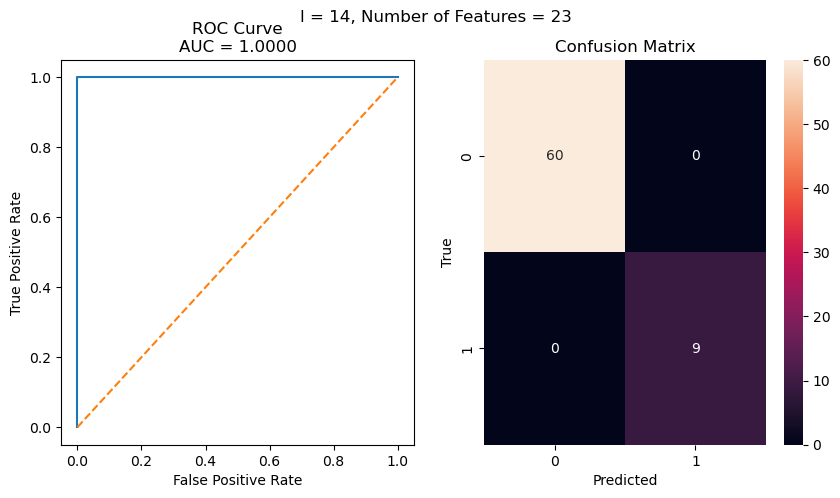

l = 14, Number of Relevant Features = 23, Features:
 Index(['max_avg_rss11', 'max_avg_rss12', 'min_avg_rss32', 'mean_avg_rss32',
       'median_avg_rss32', '3rd_quart_avg_rss32', '3rd_quart_avg_rss13',
       'median_avg_rss33', 'min_avg_rss34', 'max_avg_rss17',
       '3rd_quart_avg_rss17', 'max_avg_rss18', 'median_avg_rss18',
       '3rd_quart_avg_rss18', 'max_avg_rss19', '3rd_quart_avg_rss19',
       'max_avg_rss110', '3rd_quart_avg_rss110', 'max_avg_rss111',
       '3rd_quart_avg_rss111', 'min_avg_rss312', 'max_avg_rss213',
       'min_avg_rss313'],
      dtype='object')
    Model Params
0      -0.008908
1      -0.041202
2       0.344391
3       0.041455
4       0.096737
5       0.043962
6      -0.001791
7       0.027022
8       0.248796
9      -0.052588
10     -0.011077
11     -0.082413
12     -0.019299
13     -0.021782
14     -0.029371
15     -0.023801
16     -0.040121
17     -0.016560
18     -0.036447
19     -0.023629
20      0.126514
21     -0.008208
22      0.076148


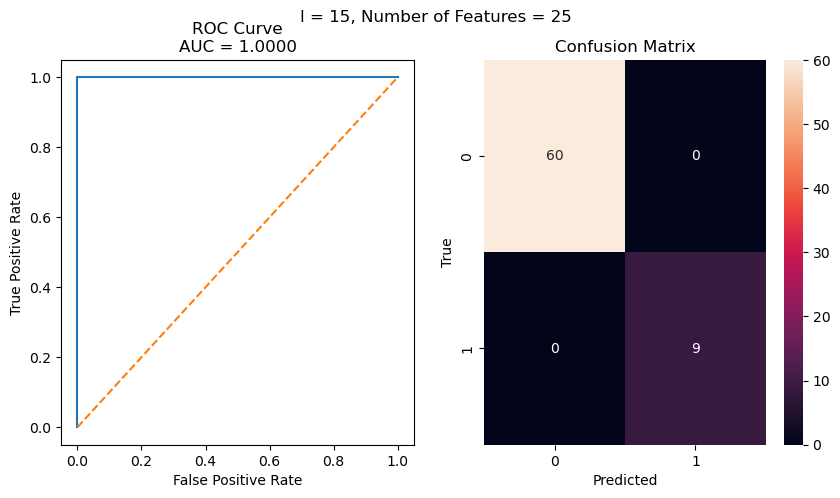

l = 15, Number of Relevant Features = 25, Features:
 Index(['max_avg_rss31', 'max_avg_rss12', 'min_avg_rss32', 'mean_avg_rss32',
       'median_avg_rss32', '3rd_quart_avg_rss32', 'mean_avg_rss33',
       'median_avg_rss33', '1st_quart_avg_rss33', '3rd_quart_avg_rss33',
       'min_avg_rss35', 'max_avg_rss17', 'max_avg_rss18', 'max_avg_rss19',
       'mean_avg_rss19', 'median_avg_rss19', '3rd_quart_avg_rss19',
       'max_avg_rss110', '3rd_quart_avg_rss110', 'max_avg_rss111',
       '3rd_quart_avg_rss111', 'max_avg_rss112', '3rd_quart_avg_rss112',
       'max_avg_rss214', 'min_avg_rss314'],
      dtype='object')
    Model Params
0       0.023081
1      -0.016474
2       0.147906
3       0.040046
4       0.100477
5       0.044034
6       0.058645
7       0.130023
8       0.115599
9       0.031907
10      0.163057
11     -0.020857
12     -0.064834
13     -0.049734
14     -0.004293
15     -0.027861
16     -0.053957
17     -0.037556
18     -0.012496
19     -0.058389
20     -0.030991
21     

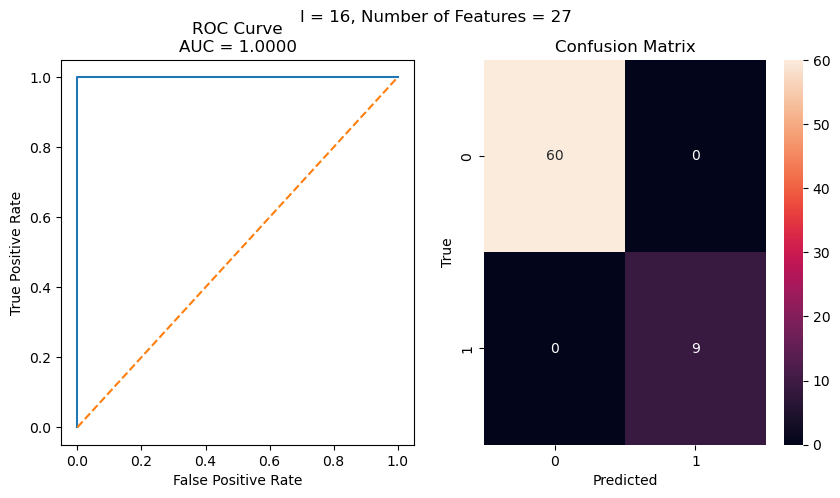

l = 16, Number of Relevant Features = 27, Features:
 Index(['max_avg_rss31', 'max_avg_rss12', 'min_avg_rss32', 'mean_avg_rss32',
       '1st_quart_avg_rss32', '3rd_quart_avg_rss32', 'max_avg_rss13',
       'min_avg_rss33', 'mean_avg_rss33', 'median_avg_rss33',
       '1st_quart_avg_rss33', '3rd_quart_avg_rss33', 'min_avg_rss35',
       'max_avg_rss18', 'max_avg_rss19', '3rd_quart_avg_rss19',
       'max_avg_rss110', 'median_avg_rss110', '3rd_quart_avg_rss110',
       'max_avg_rss111', '3rd_quart_avg_rss111', 'max_avg_rss112',
       '3rd_quart_avg_rss112', 'max_avg_rss113', '3rd_quart_avg_rss113',
       'max_avg_rss215', 'min_avg_rss315'],
      dtype='object')
    Model Params
0       0.020203
1      -0.011008
2       0.144925
3       0.007266
4       0.004173
5       0.050441
6      -0.008999
7       0.100350
8       0.050470
9       0.086313
10      0.136938
11      0.055479
12      0.139060
13     -0.062024
14     -0.066625
15     -0.012609
16     -0.024318
17     -0.018034
18    

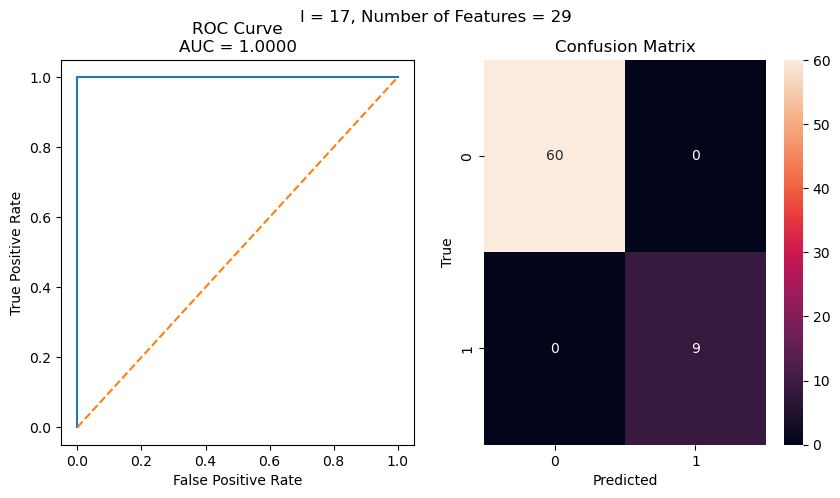

l = 17, Number of Relevant Features = 29, Features:
 Index(['max_avg_rss11', 'max_avg_rss31', 'max_avg_rss12', 'min_avg_rss32',
       'mean_avg_rss32', '3rd_quart_avg_rss32', 'max_avg_rss13',
       'min_avg_rss33', 'max_avg_rss33', 'mean_avg_rss33', 'median_avg_rss33',
       '1st_quart_avg_rss33', '3rd_quart_avg_rss33', 'min_avg_rss35',
       'max_avg_rss19', 'max_avg_rss110', 'mean_avg_rss110',
       'median_avg_rss110', '3rd_quart_avg_rss110', 'max_avg_rss111',
       '3rd_quart_avg_rss111', 'max_avg_rss112', '3rd_quart_avg_rss112',
       'max_avg_rss113', '3rd_quart_avg_rss113', 'min_avg_rss314',
       'max_avg_rss215', '3rd_quart_avg_rss215', 'min_avg_rss315'],
      dtype='object')
    Model Params
0      -0.002975
1       0.048713
2      -0.012802
3       0.103305
4       0.002118
5       0.040885
6      -0.026641
7       0.183282
8       0.000156
9       0.062920
10      0.101320
11      0.046766
12      0.038555
13      0.079705
14     -0.066056
15     -0.007843
16     -

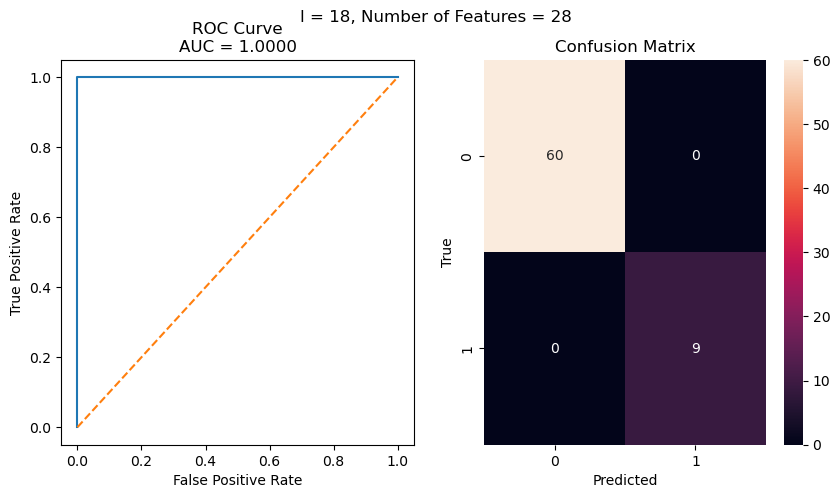

l = 18, Number of Relevant Features = 28, Features:
 Index(['max_avg_rss11', 'max_avg_rss31', 'max_avg_rss12', 'min_avg_rss32',
       'max_avg_rss13', 'min_avg_rss33', 'mean_avg_rss33', 'median_avg_rss33',
       '1st_quart_avg_rss33', 'max_avg_rss15', 'min_avg_rss35',
       'max_avg_rss19', 'max_avg_rss110', '3rd_quart_avg_rss110',
       'max_avg_rss111', 'mean_avg_rss111', 'median_avg_rss111',
       '3rd_quart_avg_rss111', 'max_avg_rss112', '3rd_quart_avg_rss112',
       'max_avg_rss113', '3rd_quart_avg_rss113', 'max_avg_rss114',
       '3rd_quart_avg_rss114', 'min_avg_rss315', '3rd_quart_avg_rss216',
       'min_avg_rss316', 'min_avg_rss317'],
      dtype='object')
    Model Params
0      -0.000219
1       0.030034
2      -0.032763
3       0.134106
4      -0.024517
5       0.140538
6       0.059495
7       0.054141
8       0.153834
9      -0.000892
10      0.165481
11     -0.060815
12     -0.067160
13     -0.025964
14     -0.021153
15     -0.006174
16     -0.021177
17     -0.029

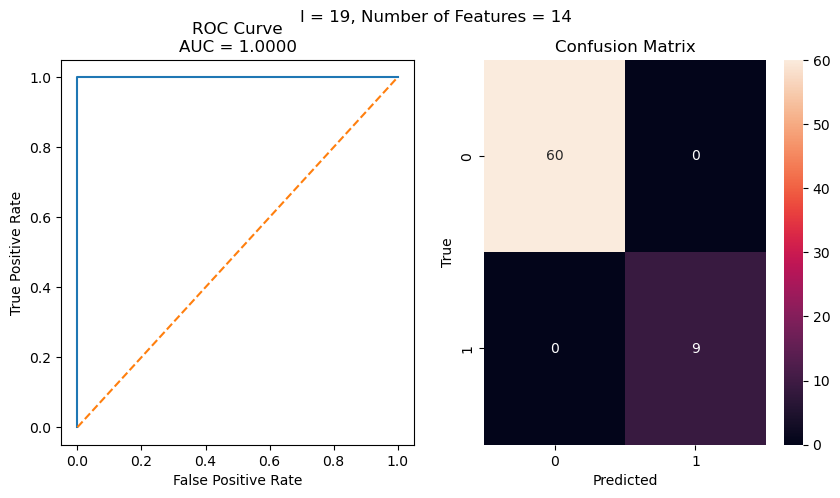

l = 19, Number of Relevant Features = 14, Features:
 Index(['min_avg_rss32', 'min_avg_rss33', 'mean_avg_rss33',
       '1st_quart_avg_rss33', 'min_avg_rss36', 'max_avg_rss110',
       'max_avg_rss111', '3rd_quart_avg_rss111', 'max_avg_rss112',
       'max_avg_rss113', 'max_avg_rss114', 'max_avg_rss115', 'max_avg_rss217',
       'min_avg_rss317'],
      dtype='object')
    Model Params
0       0.068617
1       0.220819
2       0.000076
3       0.301347
4       0.030619
5      -0.047384
6      -0.085374
7      -0.053774
8      -0.031967
9      -0.061371
10     -0.037483
11     -0.026793
12     -0.085376
13      0.240669


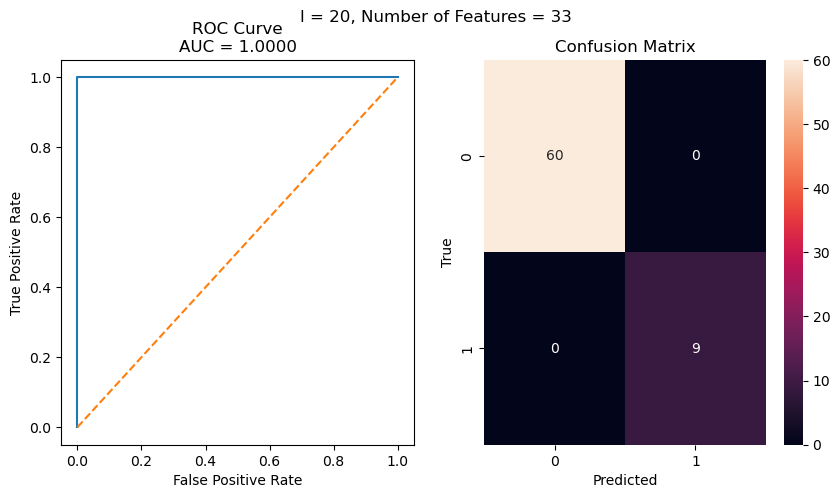

l = 20, Number of Relevant Features = 33, Features:
 Index(['max_avg_rss11', 'max_avg_rss31', 'max_avg_rss12', 'min_avg_rss32',
       'max_avg_rss13', 'min_avg_rss33', 'mean_avg_rss33', 'median_avg_rss33',
       '1st_quart_avg_rss33', 'max_avg_rss14', 'median_avg_rss34',
       '1st_quart_avg_rss34', 'max_avg_rss15', 'min_avg_rss36',
       'max_avg_rss19', 'max_avg_rss110', 'max_avg_rss111', 'max_avg_rss112',
       'mean_avg_rss112', 'median_avg_rss112', '3rd_quart_avg_rss112',
       'max_avg_rss113', '3rd_quart_avg_rss113', 'max_avg_rss114',
       '3rd_quart_avg_rss114', 'max_avg_rss115', '3rd_quart_avg_rss115',
       'max_avg_rss116', 'max_avg_rss216', 'max_avg_rss117', 'max_avg_rss218',
       'min_avg_rss318', 'min_avg_rss319'],
      dtype='object')
    Model Params
0      -0.001773
1       0.014578
2      -0.020066
3       0.083422
4      -0.014769
5       0.245178
6       0.038051
7       0.049709
8       0.118179
9      -0.000027
10      0.028288
11      0.013830
12     

In [10]:
X_reduced_train = {}
X_reduced_test = {}
model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=100)

for l in range(1, 21, 1):
    model.fit(X_train[l], Y_train)
    Y_pred = model.predict(X_train[l])

    indicies = [i for i in range(len(model.coef_[0])) if model.coef_[0][i] != 0]
    X_reduced_train[l] = X_train[l].iloc[:, indicies]
    X_reduced_test[l] = X_test[l].iloc[:, indicies]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f'l = {l}, Number of Features = {len(indicies)}')
    FPR, TPR, thresholds = roc_curve(Y_train, Y_pred) 
    ax1.plot(FPR, TPR)
    ax1.plot([0, 1], [0, 1], linestyle = '--')  
    ax1.set(xlabel="False Positive Rate", ylabel="True Positive Rate")
    ax1.set_title(f'ROC Curve\nAUC = {roc_auc_score(Y_train, Y_pred):.4f}')
    sns.heatmap(confusion_matrix(Y_train, Y_pred), annot=True)
    ax2.set(xlabel="Predicted", ylabel="True")
    ax2.set_title("Confusion Matrix")
    plt.show()
    
 
    
    print(f'l = {l}, Number of Relevant Features = {len(indicies)}, Features:\n', X_reduced_train[l].columns)
    print(pd.DataFrame({"Model Params": model.coef_[0][indicies]}))

In [11]:
for l in range(1, 21, 1):
    print(f'l = {l}')
    print("Cross Validation Scores:", cross_val_score(model, X_reduced_train[l], Y_train, cv=5))
    model.fit(X_reduced_train[l], Y_train)
    Y_pred = model.predict(X_reduced_test[l])
    print(f'Test Accuracy: {accuracy_score(Y_test, Y_pred):.4f}')


l = 1
Cross Validation Scores: [0.85714286 1.         0.92857143 1.         1.        ]
Test Accuracy: 1.0000
l = 2
Cross Validation Scores: [0.85714286 1.         0.92857143 0.92857143 1.        ]
Test Accuracy: 1.0000
l = 3
Cross Validation Scores: [0.85714286 1.         1.         0.92857143 1.        ]
Test Accuracy: 1.0000
l = 4
Cross Validation Scores: [0.92857143 1.         1.         0.92857143 1.        ]
Test Accuracy: 0.9474
l = 5
Cross Validation Scores: [0.92857143 1.         0.92857143 0.92857143 1.        ]
Test Accuracy: 1.0000
l = 6
Cross Validation Scores: [0.85714286 1.         0.92857143 0.92857143 1.        ]
Test Accuracy: 1.0000
l = 7
Cross Validation Scores: [0.85714286 1.         0.92857143 0.92857143 1.        ]
Test Accuracy: 0.9474
l = 8
Cross Validation Scores: [0.85714286 1.         1.         0.92857143 1.        ]
Test Accuracy: 0.9474
l = 9
Cross Validation Scores: [0.85714286 1.         1.         0.92857143 1.        ]
Test Accuracy: 0.9474
l = 10
Cro

In [12]:
Y_train = []
Y_test = []
for i,a in enumerate(csv_files):
    if 'dataset1.csv' in a or 'dataset2.csv' in a or 'dataset3.csv' in a:
        if 'dataset3' in a and 'bending' in a:
            Y_train.append(a.split('/')[1])
        else:
            Y_test.append(a.split('/')[1])
    else:
        Y_train.append(a.split('/')[1])

Y_train = np.array(Y_train)
Y_test = np.array(Y_test)
label_binarizer = LabelBinarizer().fit(Y_train)
Y_onehot_test = label_binarizer.transform(Y_test)
Y_onehot_train = label_binarizer.transform(Y_train)

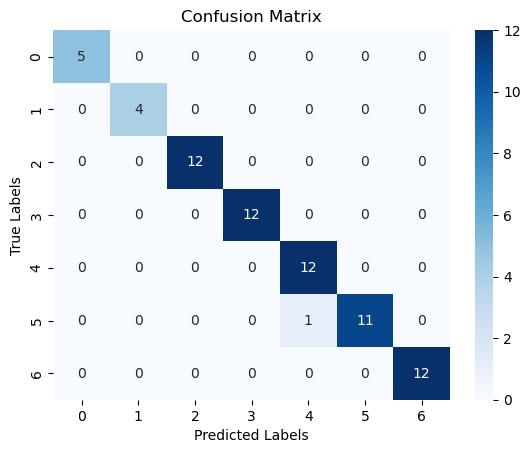

l = 1, Number of Relevant Features = 9, Features:
 Index(['min_avg_rss11', 'max_avg_rss11', '3rd_quart_avg_rss11',
       'min_avg_rss21', 'max_var_rss21', 'min_avg_rss31', 'max_avg_rss31',
       '1st_quart_avg_rss31', 'max_var_rss31'],
      dtype='object')
   Model Params
0     -0.037573
1     -0.095406
2     -0.085467
3      0.250714
4      0.024809
5      0.187959
6      0.116022
7      0.398636
8     -1.025233


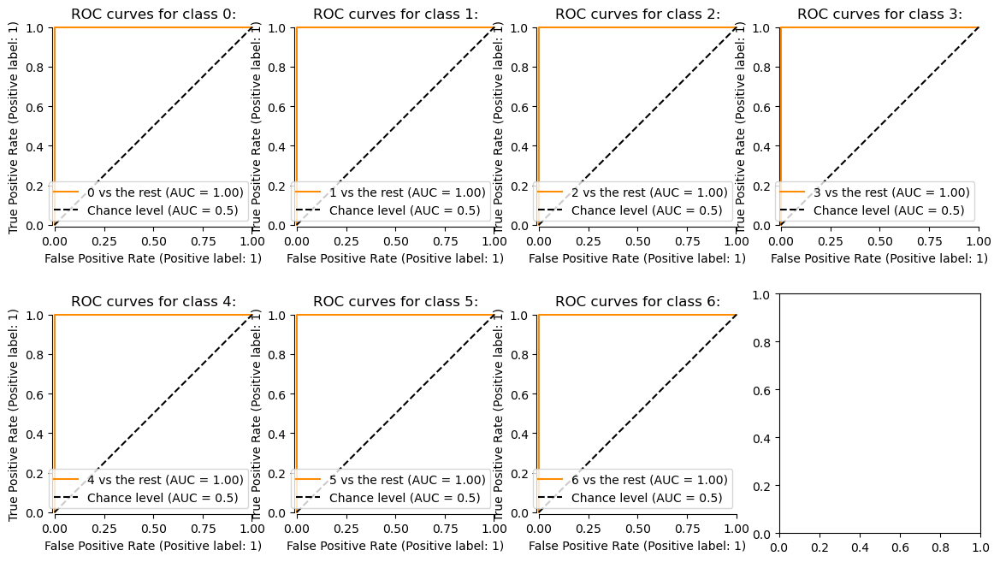

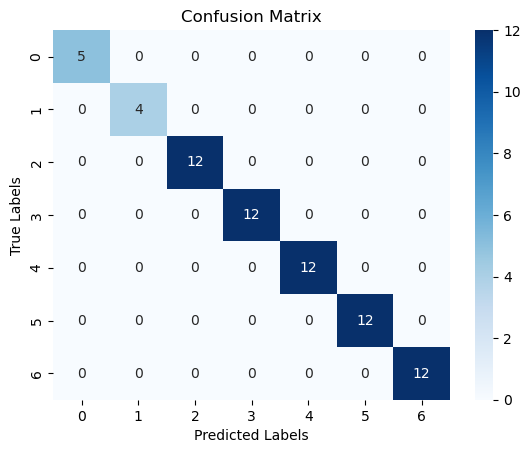

l = 2, Number of Relevant Features = 9, Features:
 Index(['max_avg_rss11', 'min_avg_rss21', 'max_avg_rss21', 'min_avg_rss31',
       'max_avg_rss31', 'max_var_rss31', '3rd_quart_avg_rss12',
       '3rd_quart_avg_rss22', '1st_quart_avg_rss32'],
      dtype='object')
   Model Params
0     -0.248841
1      0.238109
2      0.120318
3      0.163665
4      0.217861
5     -0.650719
6     -0.038187
7     -0.208638
8      0.333512


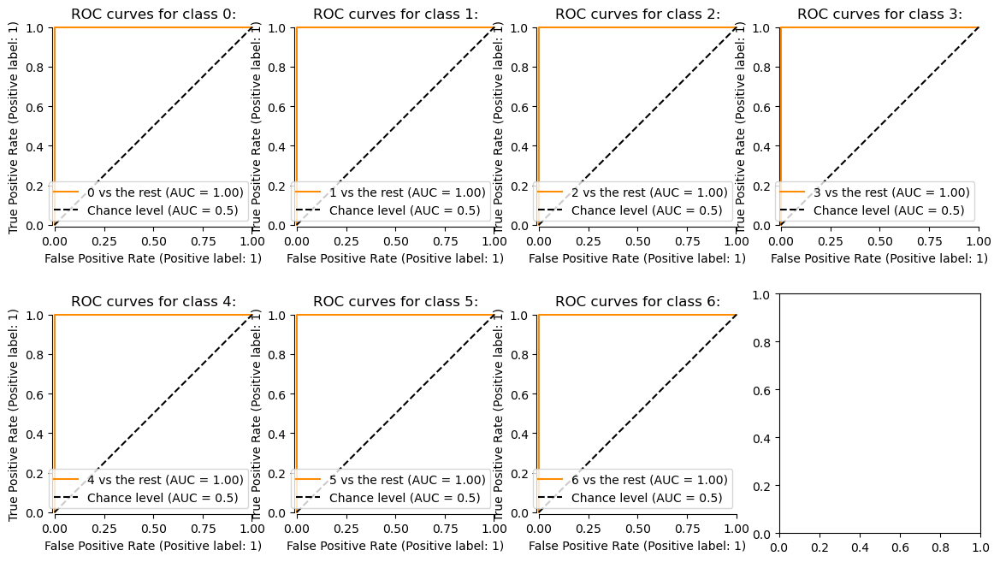

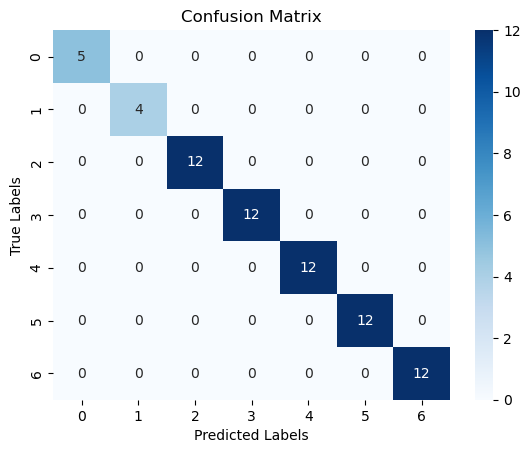

l = 3, Number of Relevant Features = 10, Features:
 Index(['max_avg_rss11', 'max_var_rss11', 'min_avg_rss21', 'max_avg_rss21',
       'min_avg_rss31', 'max_avg_rss31', 'max_var_rss31', 'min_avg_rss32',
       '3rd_quart_avg_rss23', '1st_quart_avg_rss33'],
      dtype='object')
   Model Params
0     -0.286044
1     -0.024488
2      0.143308
3      0.217490
4      0.293765
5      0.165318
6     -0.628717
7      0.038273
8     -0.165466
9      0.164514


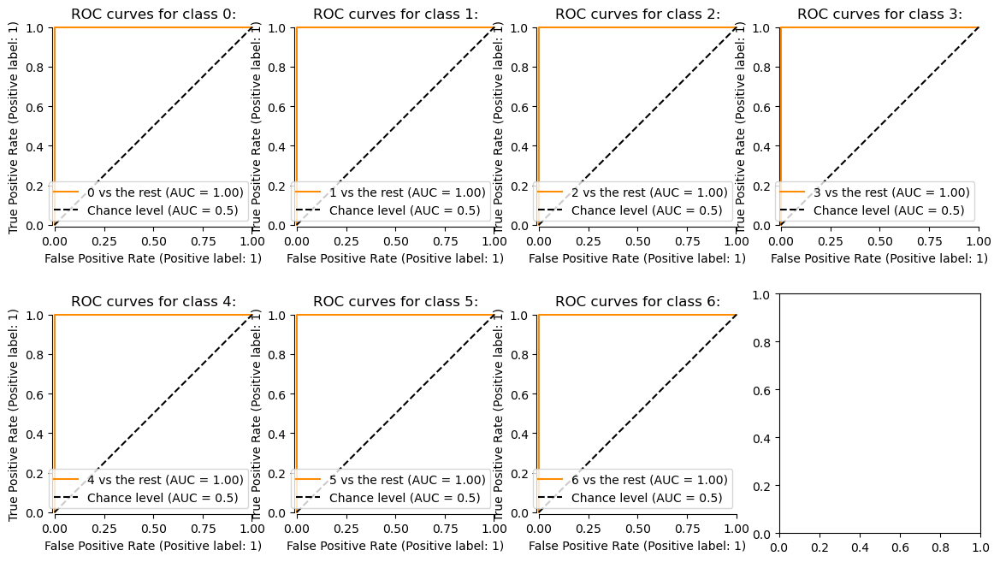

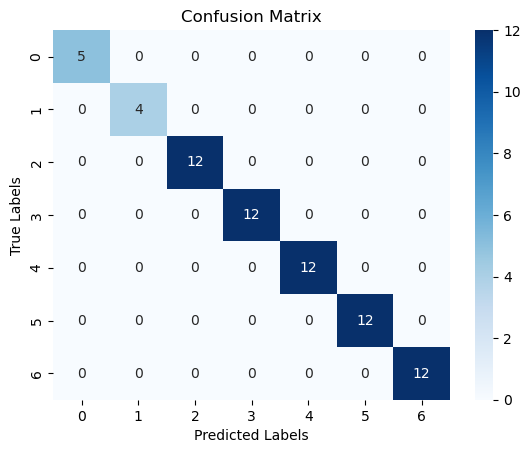

l = 4, Number of Relevant Features = 11, Features:
 Index(['max_avg_rss11', 'max_avg_rss21', 'max_var_rss31', 'mean_avg_rss22',
       'median_avg_rss22', '3rd_quart_avg_rss13', '1st_quart_avg_rss23',
       'min_avg_rss33', '3rd_quart_avg_rss24', 'min_avg_rss34',
       'max_avg_rss34'],
      dtype='object')
    Model Params
0      -0.219929
1       0.199431
2      -0.331928
3       0.011957
4       0.167525
5      -0.086623
6       0.045022
7       0.569020
8      -0.162914
9      -0.012761
10     -0.020304


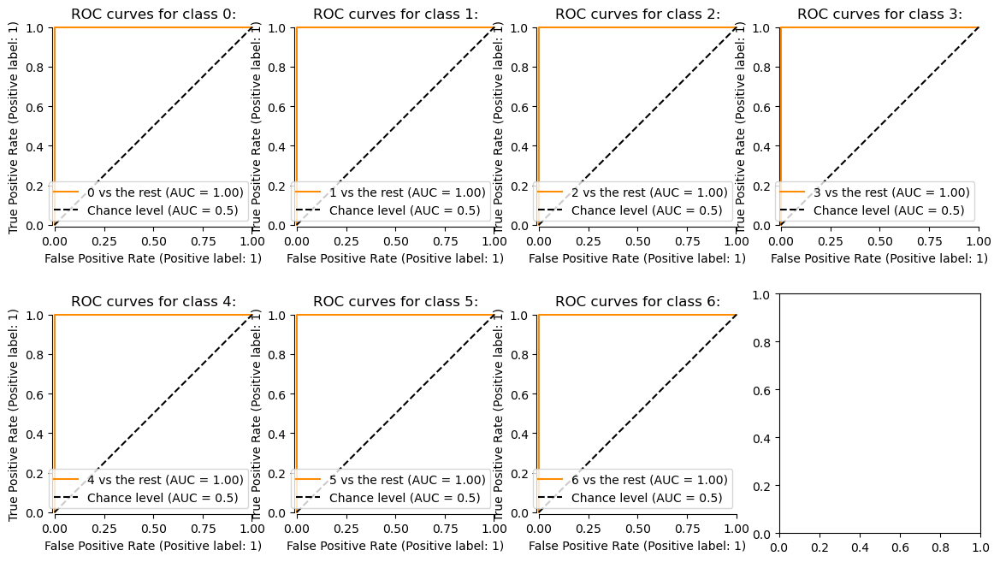

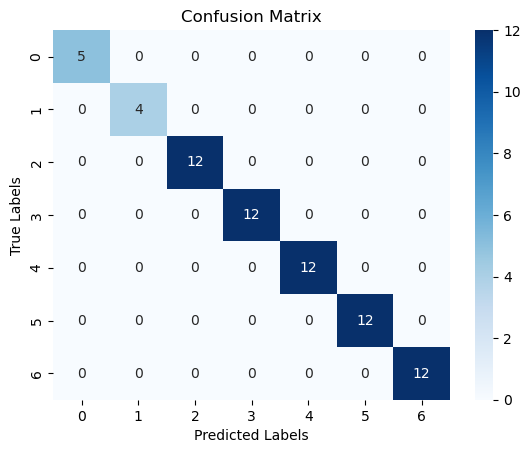

l = 5, Number of Relevant Features = 9, Features:
 Index(['max_avg_rss31', 'max_var_rss31', 'max_avg_rss12',
       '1st_quart_avg_rss22', 'min_avg_rss32', 'max_avg_rss32',
       'min_avg_rss14', 'min_avg_rss34', '3rd_quart_avg_rss25'],
      dtype='object')
   Model Params
0      0.452504
1     -0.776091
2     -0.179604
3      0.035549
4      0.208146
5     -0.058659
6     -0.080386
7      0.049750
8     -0.138487


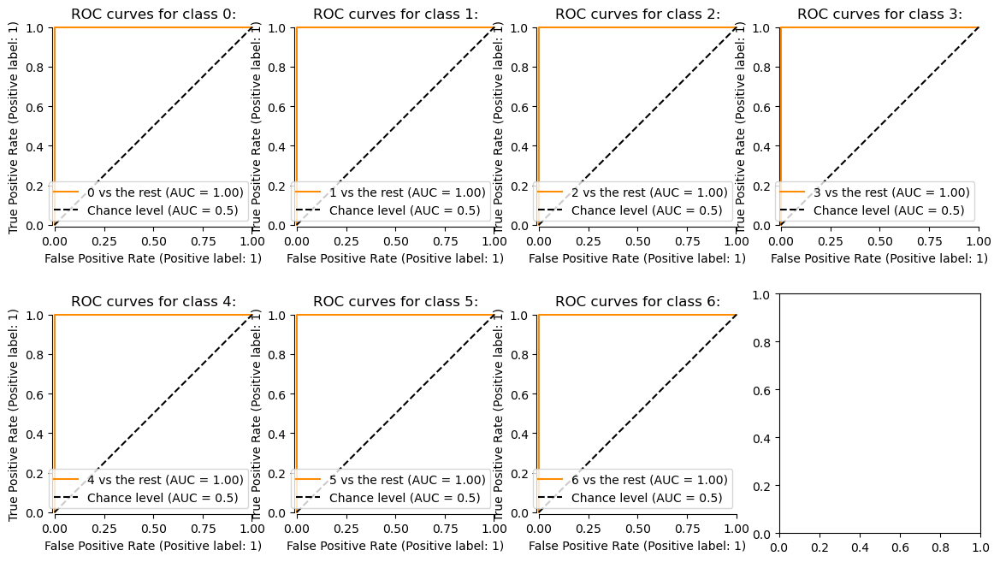

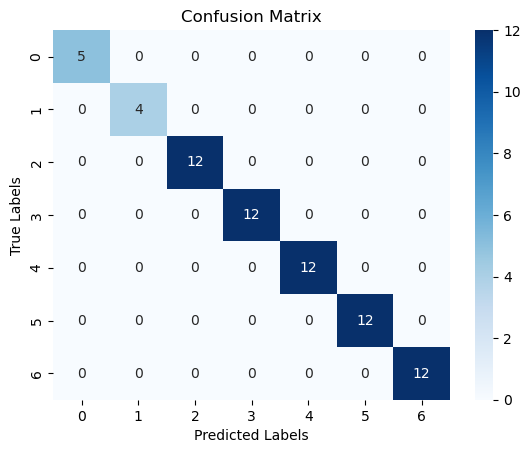

l = 6, Number of Relevant Features = 10, Features:
 Index(['max_avg_rss11', 'max_avg_rss31', 'max_var_rss31', 'max_avg_rss12',
       'min_avg_rss22', 'min_avg_rss13', 'max_avg_rss13', 'min_avg_rss23',
       'min_avg_rss34', 'max_avg_rss15'],
      dtype='object')
   Model Params
0     -0.082432
1      0.247262
2     -0.539709
3     -0.120642
4      0.138257
5     -0.082208
6     -0.049200
7      0.109599
8      0.418977
9     -0.010334


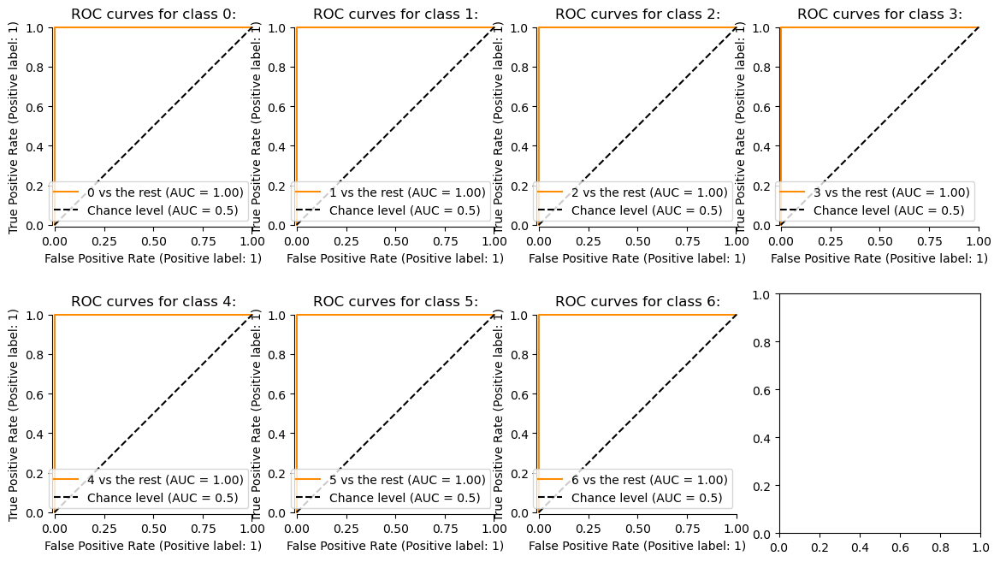

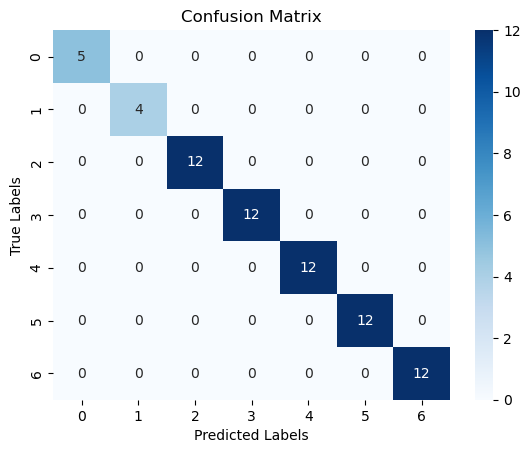

l = 7, Number of Relevant Features = 11, Features:
 Index(['max_avg_rss31', '3rd_quart_avg_rss31', 'max_var_rss31',
       'max_avg_rss12', 'min_avg_rss23', 'min_avg_rss33', 'max_avg_rss15',
       'min_avg_rss25', 'max_avg_rss25', 'min_avg_rss35', 'min_avg_rss36'],
      dtype='object')
    Model Params
0       0.309315
1       0.004796
2      -0.401757
3      -0.214930
4       0.333080
5       0.074592
6      -0.063000
7       0.036609
8      -0.181273
9       0.014464
10      0.185076


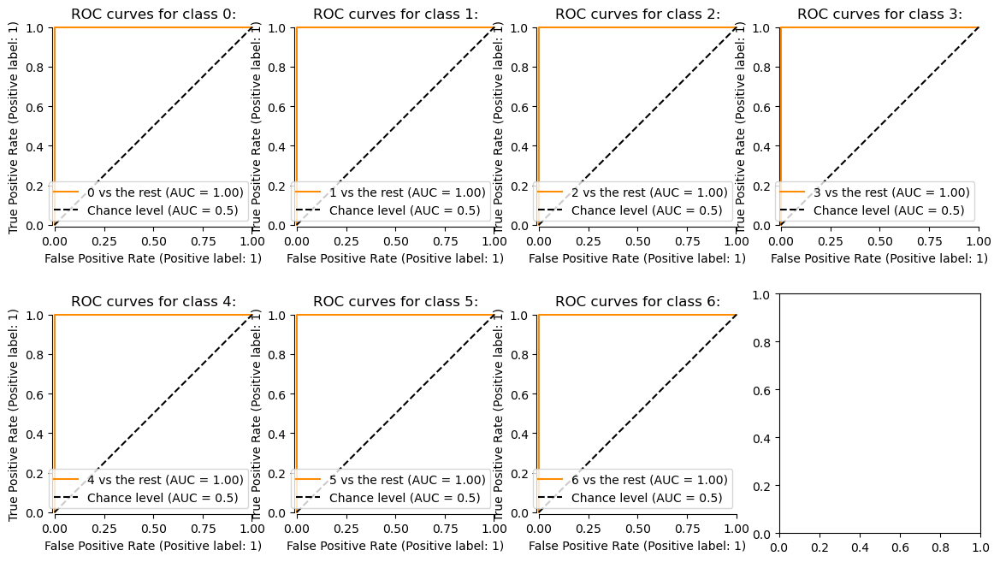

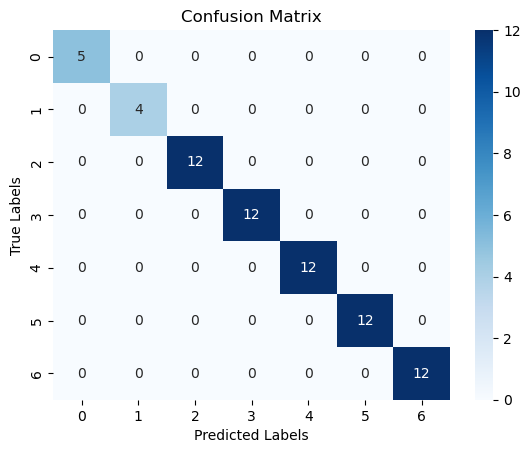

l = 8, Number of Relevant Features = 12, Features:
 Index(['max_avg_rss11', 'max_avg_rss21', 'max_var_rss31', 'max_avg_rss12',
       '1st_quart_avg_rss23', 'min_avg_rss33', 'max_avg_rss15',
       'min_avg_rss25', 'min_avg_rss35', 'max_avg_rss16', 'min_avg_rss26',
       '3rd_quart_avg_rss28'],
      dtype='object')
    Model Params
0      -0.084228
1       0.032184
2      -0.226830
3      -0.147268
4       0.204538
5       0.160279
6      -0.094549
7      -0.025255
8       0.425616
9      -0.001452
10      0.224814
11     -0.052930


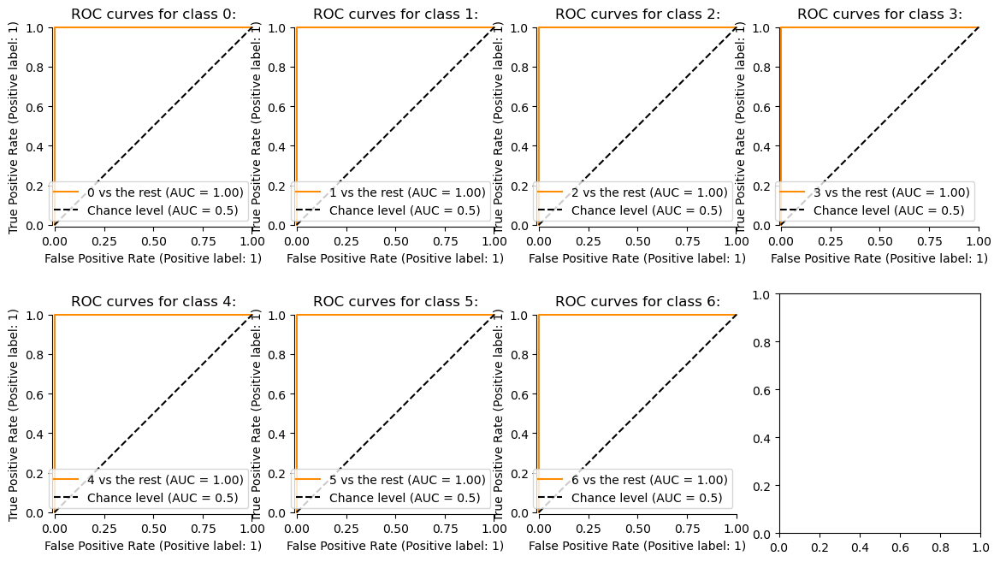

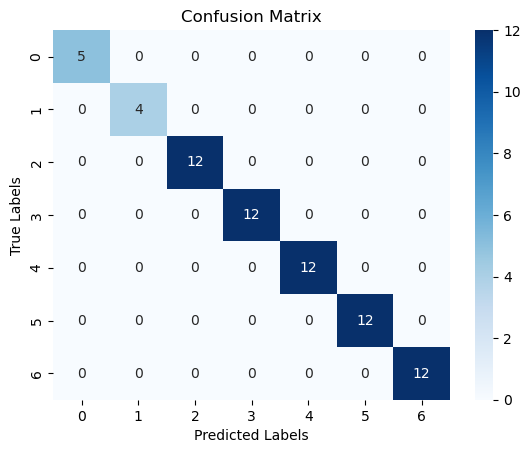

l = 9, Number of Relevant Features = 14, Features:
 Index(['max_avg_rss11', 'max_avg_rss21', '1st_quart_avg_rss21',
       'max_avg_rss12', '3rd_quart_avg_rss12', '1st_quart_avg_rss23',
       'min_avg_rss33', 'max_avg_rss14', '1st_quart_avg_rss24',
       'min_avg_rss15', 'max_avg_rss16', 'max_avg_rss26', 'min_avg_rss36',
       'max_avg_rss19'],
      dtype='object')
    Model Params
0      -0.053005
1       0.066593
2       0.085891
3      -0.097521
4      -0.027544
5       0.110534
6       0.571586
7      -0.020288
8       0.030492
9      -0.028400
10     -0.140936
11     -0.059011
12      0.170957
13     -0.030309


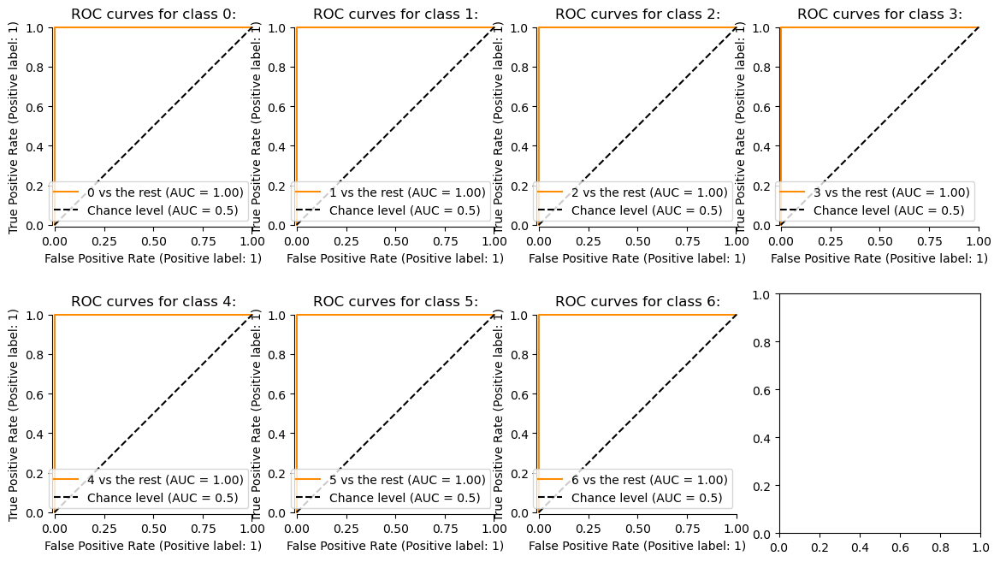

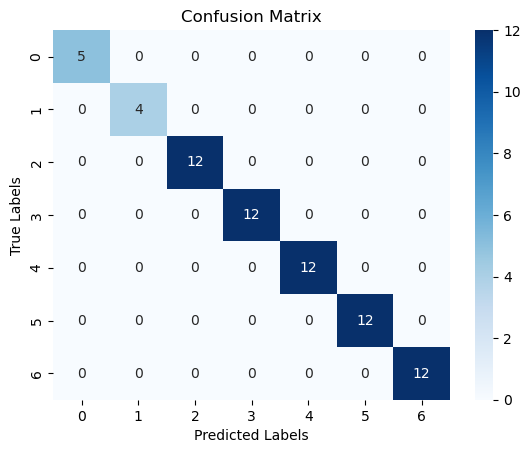

l = 10, Number of Relevant Features = 12, Features:
 Index(['max_avg_rss31', 'max_avg_rss12', '1st_quart_avg_rss32',
       'max_var_rss32', 'max_avg_rss13', 'median_avg_rss24', 'min_avg_rss15',
       'min_avg_rss36', 'max_avg_rss17', 'min_avg_rss27', 'min_avg_rss18',
       'median_avg_rss29'],
      dtype='object')
    Model Params
0       0.213777
1      -0.026531
2       0.081508
3      -0.481963
4      -0.151997
5       0.071819
6      -0.037973
7       0.371679
8      -0.139298
9       0.101850
10     -0.000002
11     -0.002718


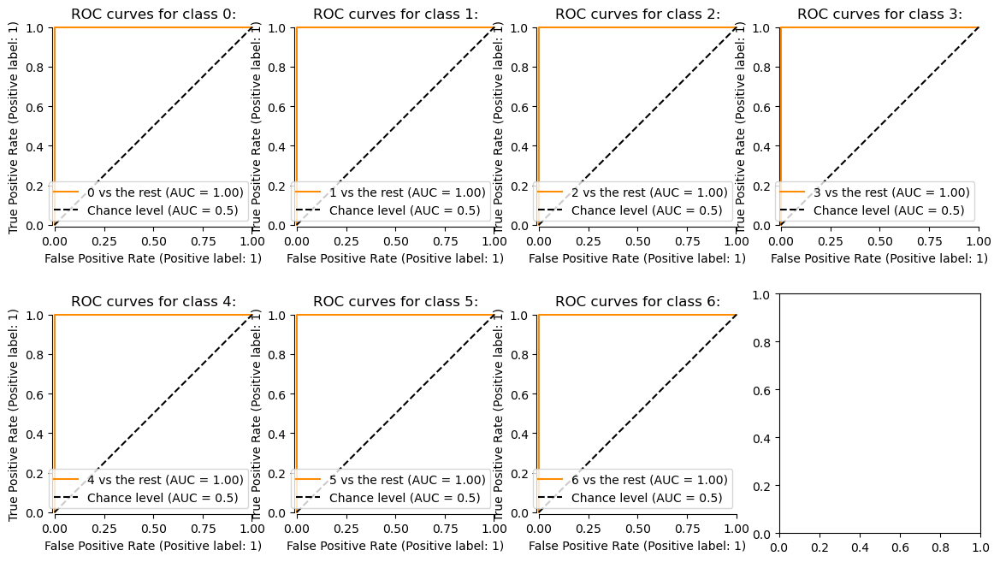

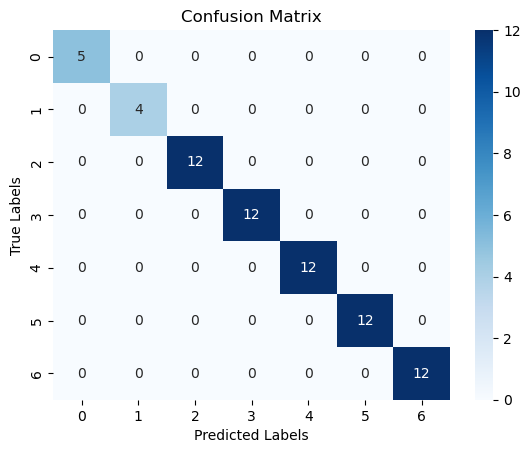

l = 11, Number of Relevant Features = 12, Features:
 Index(['max_avg_rss12', 'min_avg_rss32', 'max_avg_rss13', 'min_avg_rss24',
       'min_avg_rss34', 'max_avg_rss17', 'max_avg_rss27', 'min_avg_rss37',
       'max_avg_rss18', 'min_avg_rss28', '3rd_quart_avg_rss210',
       'max_avg_rss111'],
      dtype='object')
    Model Params
0      -0.012781
1       0.367440
2      -0.119985
3       0.208237
4       0.126162
5      -0.097876
6      -0.112320
7       0.127596
8      -0.002692
9       0.143544
10     -0.089504
11     -0.025548


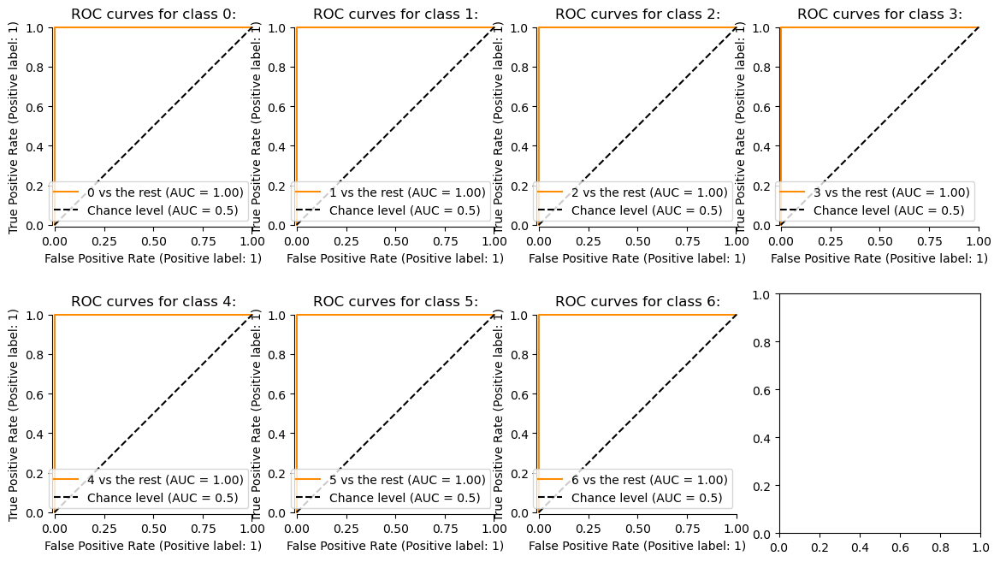

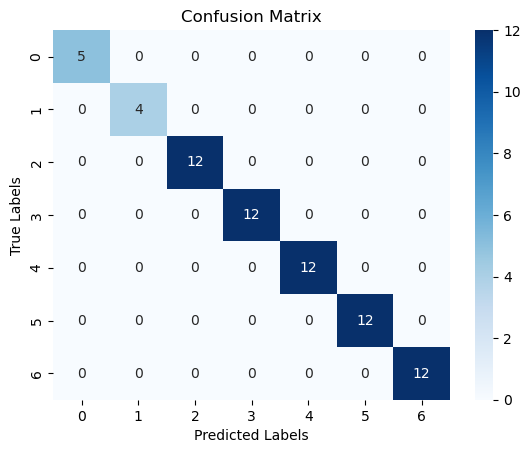

l = 12, Number of Relevant Features = 14, Features:
 Index(['min_avg_rss32', 'max_avg_rss13', '1st_quart_avg_rss24',
       'min_avg_rss34', 'min_avg_rss16', 'max_avg_rss16', 'min_avg_rss37',
       'max_avg_rss18', 'max_avg_rss28', 'min_avg_rss38', 'min_avg_rss29',
       'min_avg_rss110', 'max_avg_rss110', '3rd_quart_avg_rss211'],
      dtype='object')
    Model Params
0       0.197085
1      -0.085784
2       0.143186
3       0.167425
4      -0.023976
5      -0.018392
6       0.107728
7      -0.104707
8      -0.128363
9       0.114313
10      0.289915
11     -0.003495
12     -0.027620
13     -0.172053


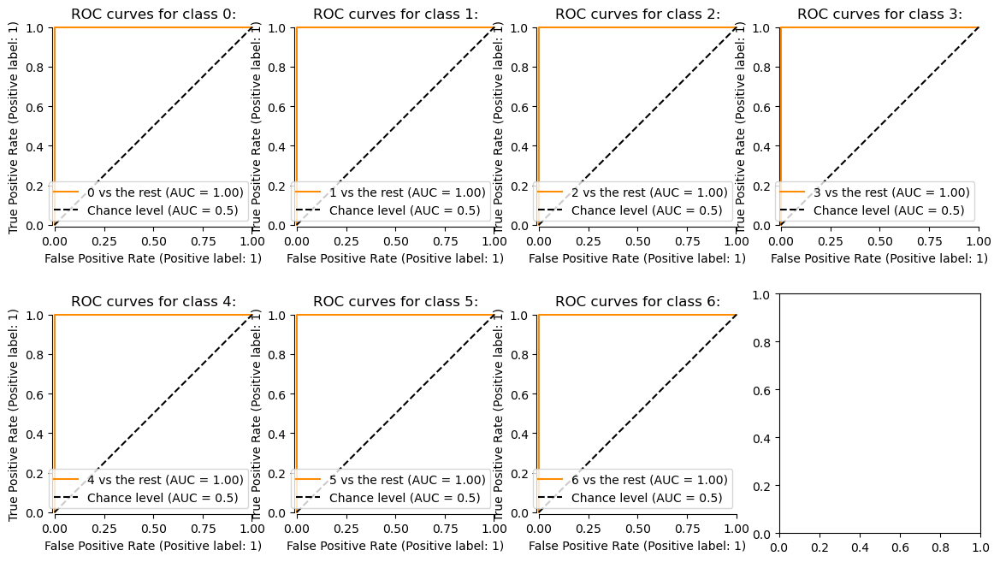

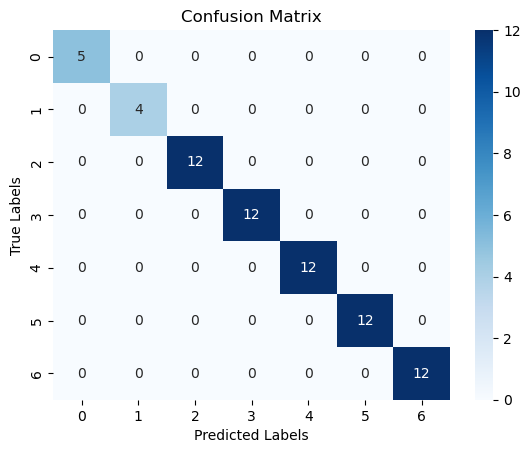

l = 13, Number of Relevant Features = 17, Features:
 Index(['max_avg_rss12', 'min_avg_rss32', 'max_avg_rss13', 'max_avg_rss14',
       '1st_quart_avg_rss24', 'min_avg_rss34', 'max_avg_rss15',
       'min_avg_rss25', 'max_avg_rss16', 'min_avg_rss36', 'min_avg_rss17',
       'max_avg_rss18', 'min_avg_rss38', 'max_avg_rss19', 'min_avg_rss210',
       'max_avg_rss111', '3rd_quart_avg_rss212'],
      dtype='object')
    Model Params
0      -0.032263
1       0.130813
2      -0.052298
3      -0.039751
4       0.063134
5       0.366317
6      -0.031117
7       0.227852
8      -0.042306
9       0.031098
10     -0.055335
11     -0.040640
12      0.148098
13     -0.027246
14      0.086187
15     -0.005360
16     -0.183891


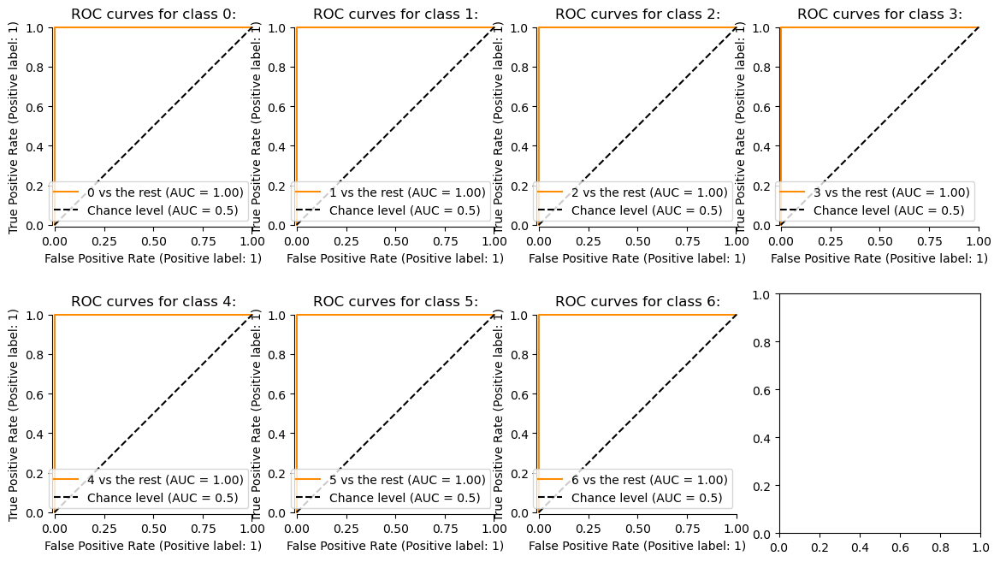

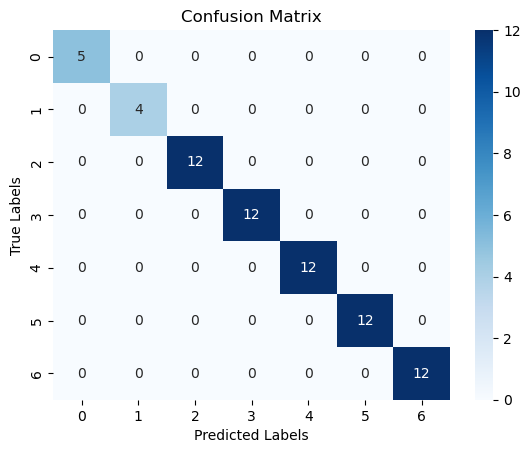

l = 14, Number of Relevant Features = 15, Features:
 Index(['min_avg_rss32', 'max_var_rss32', 'max_avg_rss13', 'max_avg_rss14',
       'min_avg_rss34', 'min_avg_rss25', 'min_avg_rss35', 'max_avg_rss16',
       'min_avg_rss28', 'max_avg_rss19', 'max_avg_rss29', 'min_avg_rss39',
       'min_avg_rss210', 'max_avg_rss213', '3rd_quart_avg_rss213'],
      dtype='object')
    Model Params
0       0.209691
1      -0.013532
2      -0.003841
3      -0.190281
4       0.246228
5       0.339536
6       0.060996
7      -0.025445
8      -0.020405
9      -0.097830
10     -0.041952
11      0.116793
12      0.050070
13     -0.020276
14     -0.041177


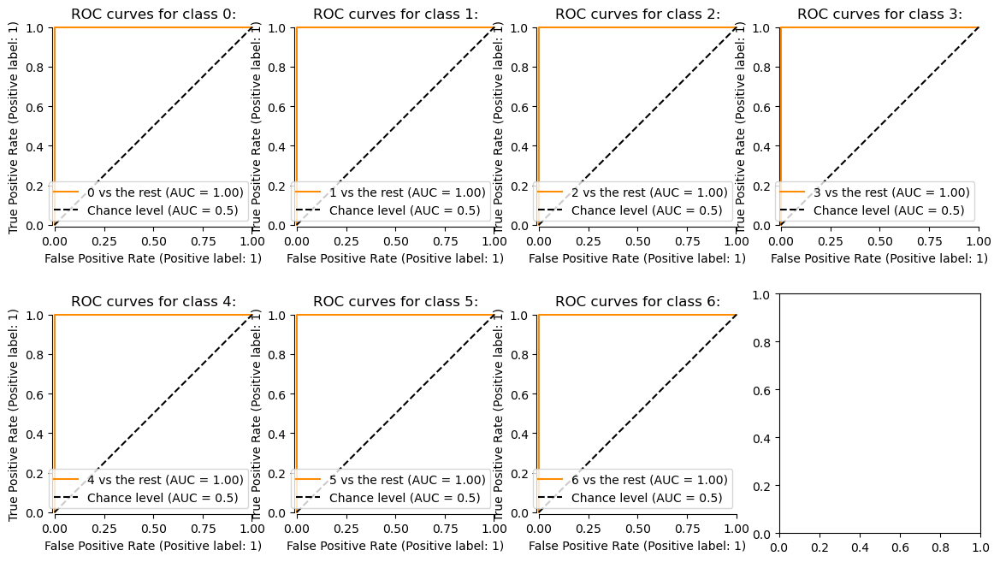

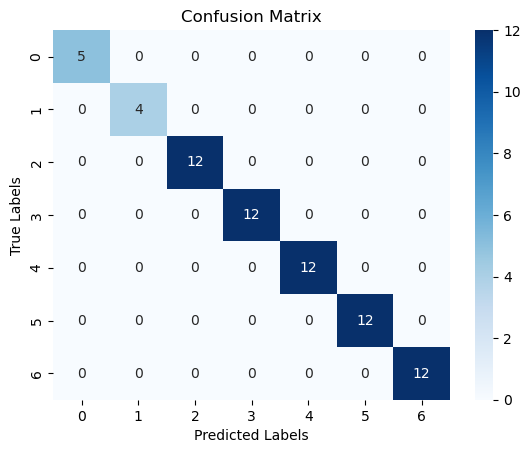

l = 15, Number of Relevant Features = 16, Features:
 Index(['3rd_quart_avg_rss22', 'min_avg_rss32', '1st_quart_avg_rss33',
       'max_avg_rss14', 'max_avg_rss15', 'min_avg_rss35', 'max_avg_rss16',
       '1st_quart_avg_rss26', 'max_avg_rss17', 'min_avg_rss18',
       'min_avg_rss39', 'max_avg_rss110', 'max_avg_rss210', 'min_avg_rss211',
       'max_avg_rss214', '3rd_quart_avg_rss214'],
      dtype='object')
    Model Params
0       0.017258
1       0.087154
2       0.053636
3      -0.037903
4      -0.024052
5       0.202087
6      -0.024016
7       0.212148
8      -0.061100
9      -0.082878
10      0.281007
11     -0.074726
12     -0.082080
13      0.181755
14     -0.062003
15     -0.153481


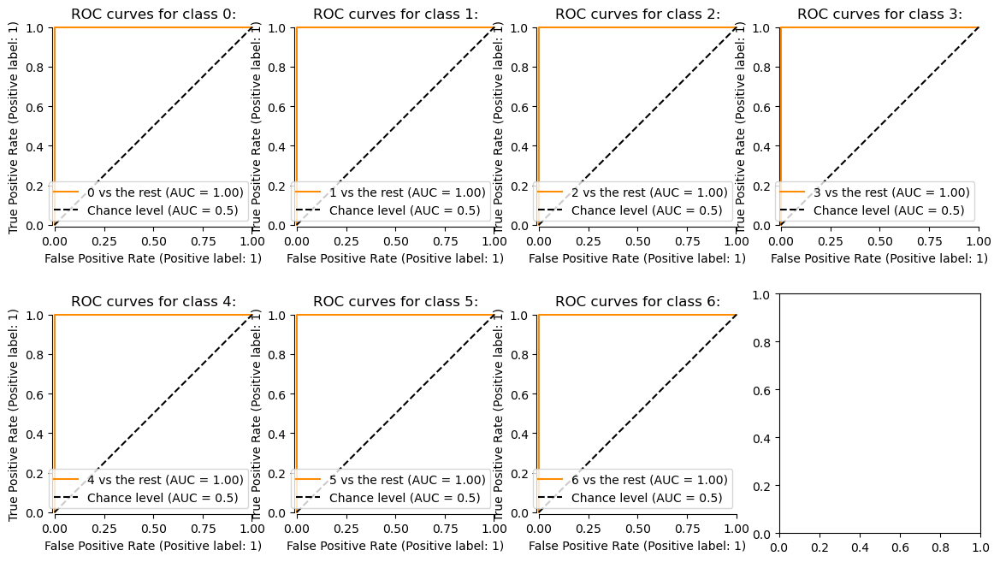

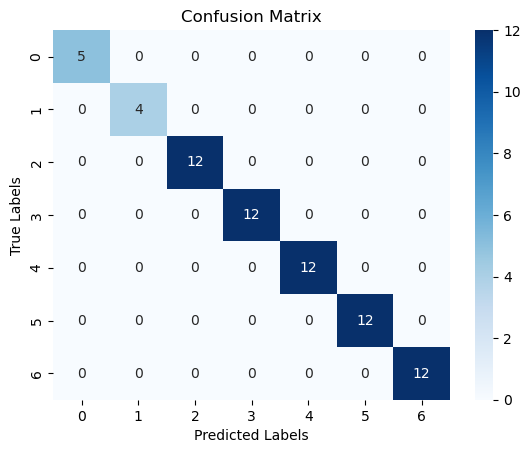

l = 16, Number of Relevant Features = 17, Features:
 Index(['max_avg_rss12', 'min_avg_rss33', 'max_avg_rss14',
       '1st_quart_avg_rss25', 'min_avg_rss35', 'min_avg_rss26',
       'median_avg_rss26', '1st_quart_avg_rss26', 'min_avg_rss18',
       'max_avg_rss110', 'max_avg_rss210', 'min_avg_rss310', 'max_avg_rss111',
       'min_avg_rss212', 'max_avg_rss113', 'max_avg_rss215',
       '3rd_quart_avg_rss215'],
      dtype='object')
    Model Params
0      -0.008110
1       0.190396
2      -0.062986
3       0.024047
4       0.137169
5       0.023281
6       0.080245
7       0.019815
8      -0.067570
9      -0.082256
10     -0.120156
11      0.219481
12     -0.020132
13      0.250356
14     -0.004204
15     -0.088464
16     -0.139727


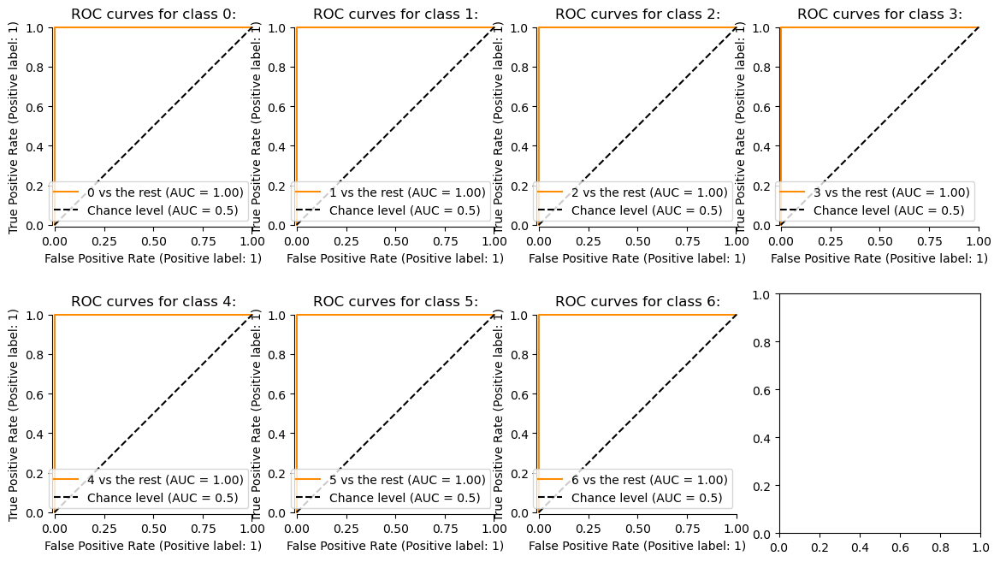

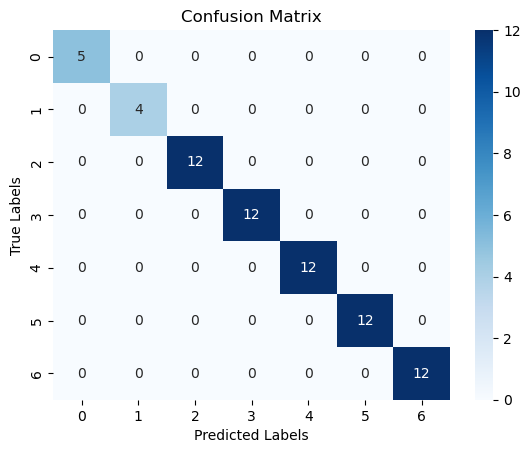

l = 17, Number of Relevant Features = 17, Features:
 Index(['max_avg_rss12', 'min_avg_rss33', 'max_avg_rss14', 'min_avg_rss25',
       'min_avg_rss35', 'max_avg_rss16', 'min_avg_rss26', 'min_avg_rss36',
       'max_avg_rss110', 'min_avg_rss310', 'max_avg_rss111',
       '3rd_quart_avg_rss111', 'max_avg_rss114', '3rd_quart_avg_rss215',
       'max_avg_rss116', 'min_avg_rss117', 'min_avg_rss317'],
      dtype='object')
    Model Params
0      -0.042741
1       0.350197
2      -0.094420
3       0.039392
4       0.024326
5      -0.027086
6       0.287231
7       0.076465
8      -0.009560
9       0.192483
10     -0.096978
11     -0.011845
12     -0.036836
13     -0.087487
14     -0.005877
15     -0.000012
16     -0.052475


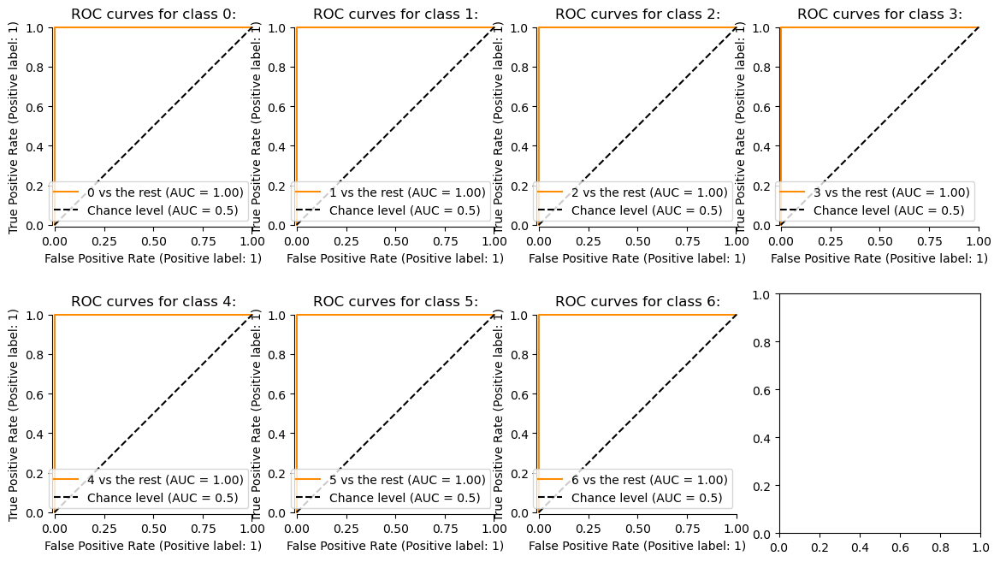

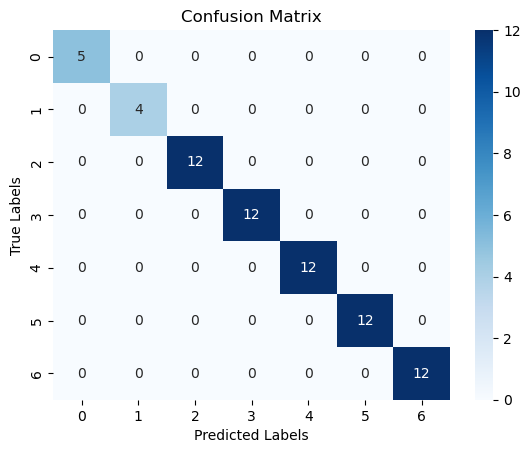

l = 18, Number of Relevant Features = 20, Features:
 Index(['max_avg_rss12', 'max_avg_rss13', 'min_avg_rss33', 'max_avg_rss14',
       'max_avg_rss15', 'min_avg_rss35', 'min_avg_rss26', 'min_avg_rss36',
       'min_avg_rss19', 'max_avg_rss111', 'max_avg_rss211', 'min_avg_rss311',
       'max_avg_rss112', 'max_avg_rss115', 'max_avg_rss215',
       '3rd_quart_avg_rss216', 'max_avg_rss117', 'min_avg_rss317',
       'min_avg_rss218', 'min_avg_rss318'],
      dtype='object')
    Model Params
0      -0.016058
1      -0.016935
2       0.326587
3      -0.029662
4      -0.058771
5       0.060773
6       0.140834
7       0.194905
8      -0.018864
9      -0.112444
10     -0.095114
11      0.136627
12     -0.035080
13     -0.013696
14     -0.003740
15     -0.000928
16     -0.004510
17      0.015726
18      0.001896
19     -0.061424


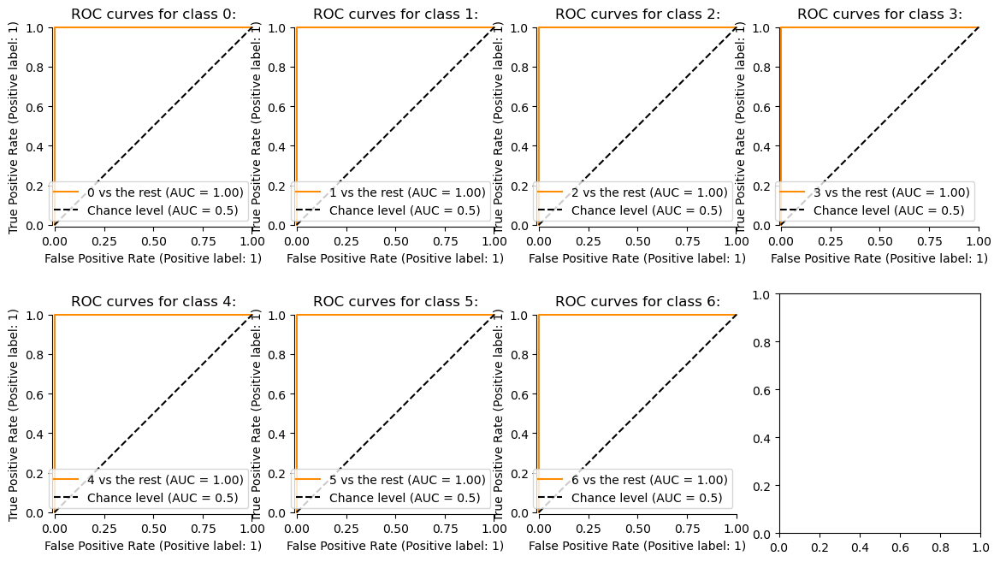

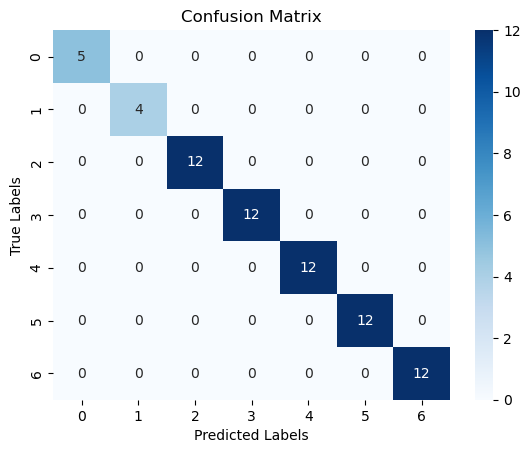

l = 19, Number of Relevant Features = 21, Features:
 Index(['min_avg_rss33', 'max_avg_rss15', 'max_avg_rss35', 'max_avg_rss16',
       '3rd_quart_avg_rss16', 'min_avg_rss26', 'min_avg_rss36',
       'min_avg_rss27', 'max_avg_rss18', 'min_avg_rss311', 'max_avg_rss112',
       'max_avg_rss212', 'max_avg_rss113', 'min_avg_rss214', 'min_avg_rss115',
       'max_avg_rss115', '1st_quart_avg_rss115', 'max_avg_rss215',
       'max_avg_rss217', '3rd_quart_avg_rss217', 'min_avg_rss319'],
      dtype='object')
    Model Params
0       0.315677
1      -0.043190
2      -0.025686
3      -0.058844
4      -0.022205
5       0.048340
6       0.090699
7       0.160279
8      -0.022277
9       0.274850
10     -0.066662
11     -0.030835
12     -0.030275
13      0.043281
14     -0.005062
15     -0.020296
16     -0.017643
17     -0.043067
18     -0.108802
19     -0.013063
20     -0.000112


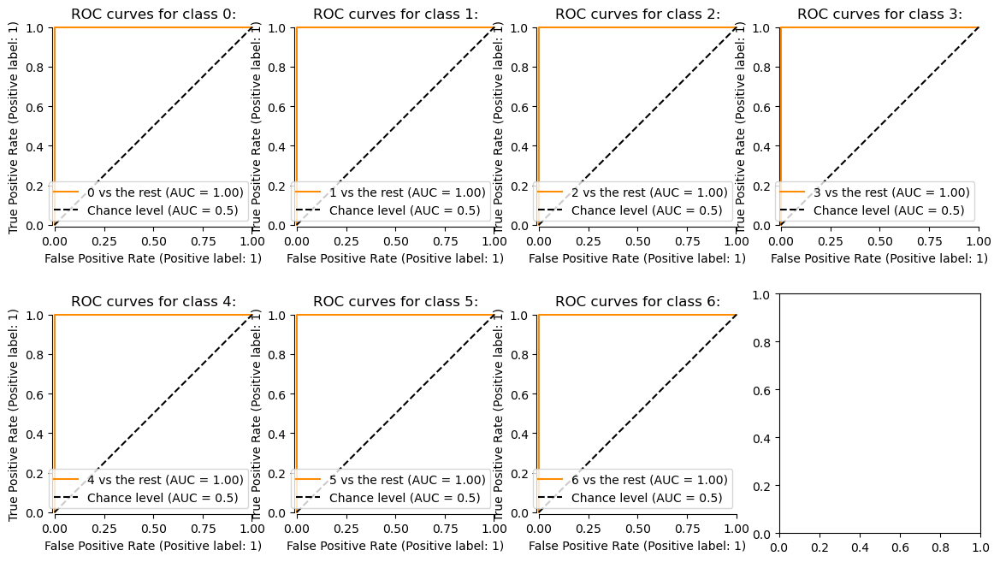

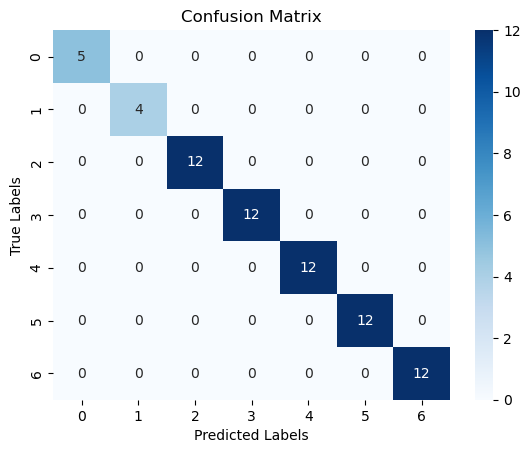

l = 20, Number of Relevant Features = 18, Features:
 Index(['max_avg_rss13', 'min_avg_rss33', 'max_avg_rss15', 'min_avg_rss26',
       'max_avg_rss17', 'min_avg_rss27', 'min_avg_rss37', 'min_avg_rss110',
       'min_avg_rss312', 'max_avg_rss113', 'max_avg_rss114',
       '3rd_quart_avg_rss114', 'min_avg_rss215', 'max_avg_rss116',
       '1st_quart_avg_rss116', 'max_avg_rss216', 'max_avg_rss117',
       'max_avg_rss119'],
      dtype='object')
    Model Params
0      -0.012638
1       0.281205
2      -0.052934
3       0.014279
4      -0.006236
5       0.185466
6       0.205759
7      -0.015183
8       0.201058
9      -0.071889
10     -0.038671
11     -0.003941
12      0.021446
13     -0.028877
14     -0.011755
15     -0.221419
16     -0.028352
17     -0.009595


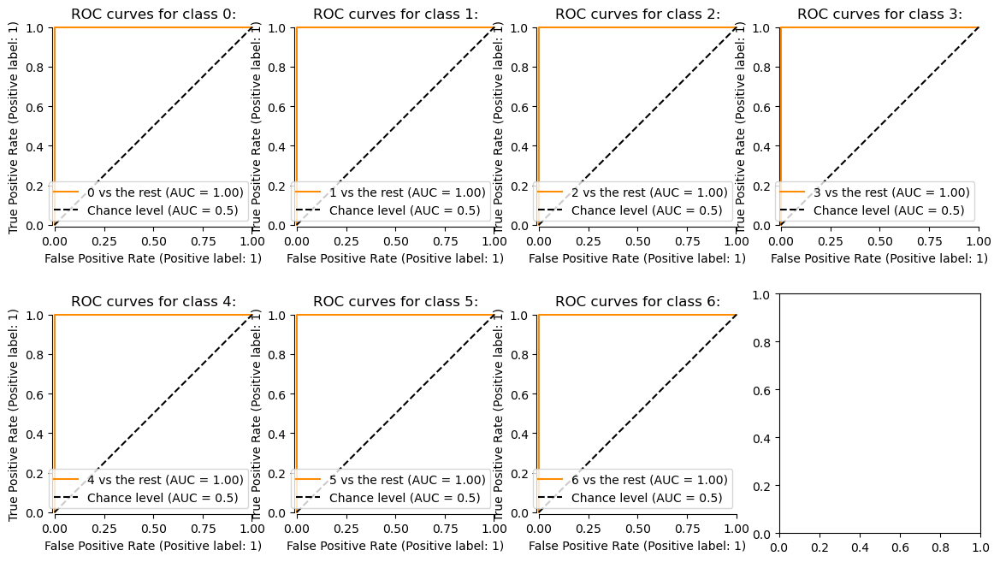

In [13]:
X_reduced_train = {}
X_reduced_test = {}
model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=100)

for l in range(1, 21, 1):
    model.fit(X_train[l], Y_train)
    Y_pred = model.predict(X_train[l])
    Y_score = model.predict_log_proba(X_train[l])

    cm = confusion_matrix(Y_train, Y_pred)
    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.show()

    fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(14, 8))

    for i in range(len(cm)):
        RocCurveDisplay.from_predictions(
            Y_onehot_train[:, i],
            Y_score[:, i],
            ax=axs[i//4, i-4],
            name=f"{i} vs the rest",
            color="darkorange",
            plot_chance_level=True,
            despine=True,
        )
        axs[i//4, i-4].set_title(f'ROC curves for class {i}:')
        axs[i//4, i-4].plot(
            xlabel="False Positive Rate",
            ylabel="True Positive Rate",
        )
    indicies = [i for i in range(len(model.coef_[0])) if model.coef_[0][i] != 0]
    X_reduced_train[l] = X_train[l].iloc[:, indicies]
    X_reduced_test[l] = X_test[l].iloc[:, indicies]
    
    print(f'l = {l}, Number of Relevant Features = {len(indicies)}, Features:\n', X_reduced_train[l].columns)
    print(pd.DataFrame({"Model Params": model.coef_[0][indicies]}))

l = 1
Cross Validation Scores: [0.71428571 0.85714286 0.64285714 0.71428571 0.76923077]
Test Accuracy: 0.6842


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


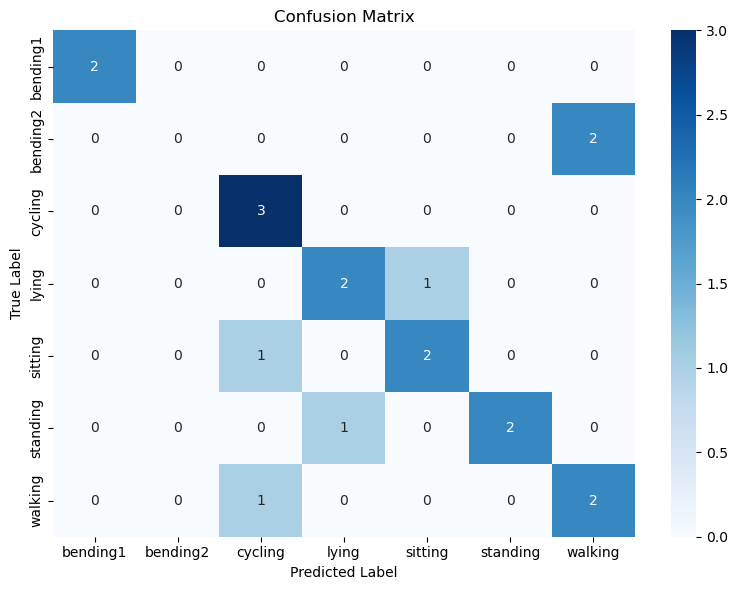

l = 2
Cross Validation Scores: [0.78571429 1.         0.57142857 0.64285714 0.61538462]
Test Accuracy: 0.6316


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


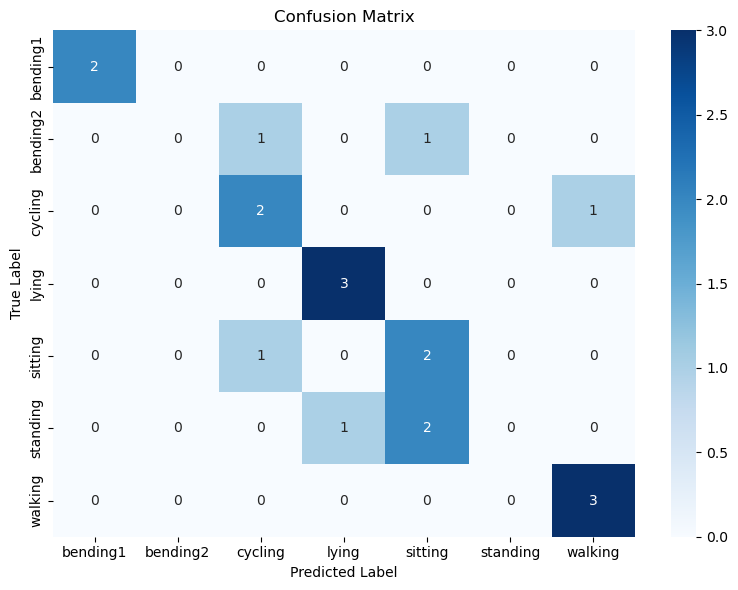

l = 3


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.92857143 0.78571429 0.57142857 0.78571429 0.84615385]
Test Accuracy: 0.7368


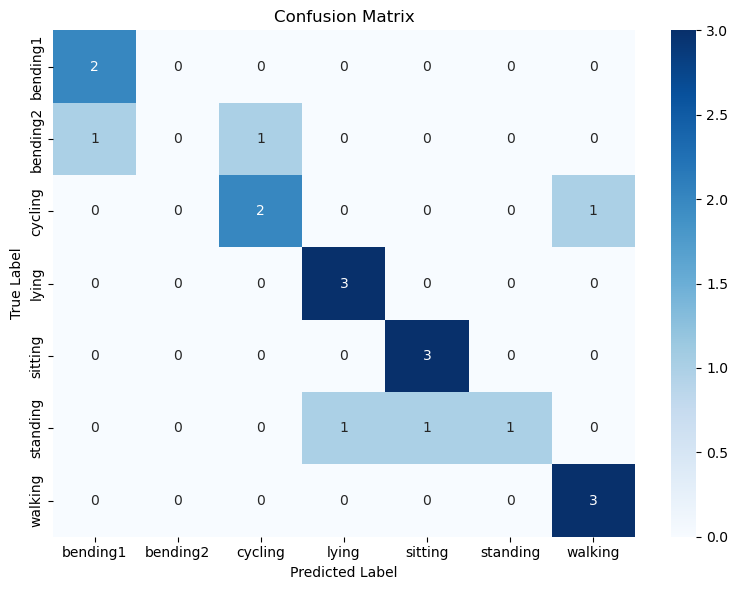

l = 4


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.78571429 0.64285714 0.57142857 0.64285714 0.61538462]
Test Accuracy: 0.6842


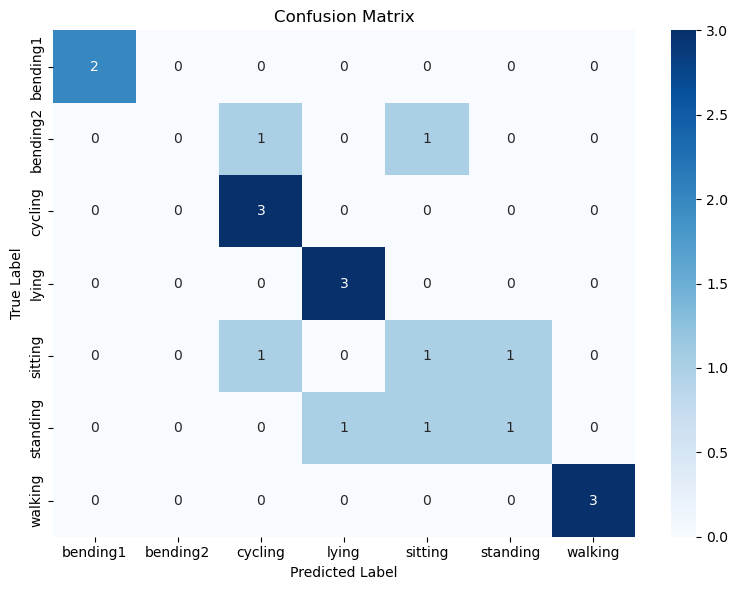

l = 5
Cross Validation Scores: [0.78571429 0.78571429 0.71428571 0.64285714 0.69230769]
Test Accuracy: 0.6842


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


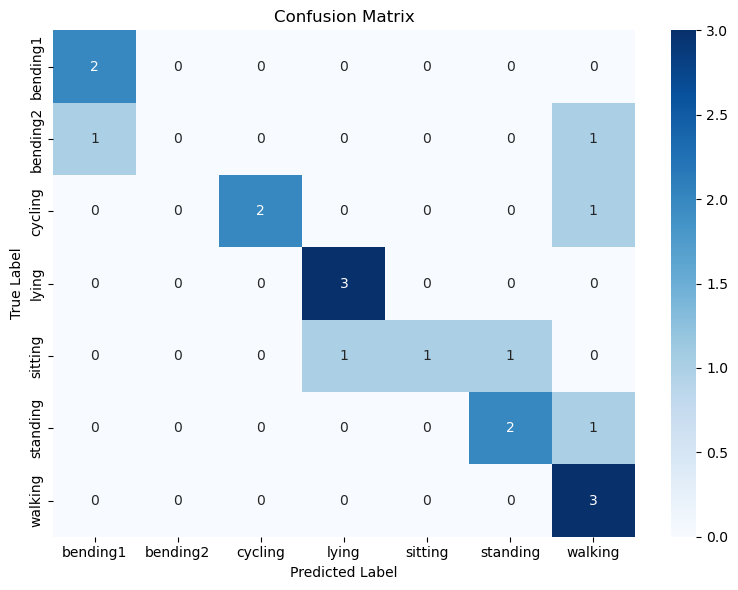

l = 6


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.57142857 0.78571429 0.71428571 0.71428571 0.76923077]
Test Accuracy: 0.5263


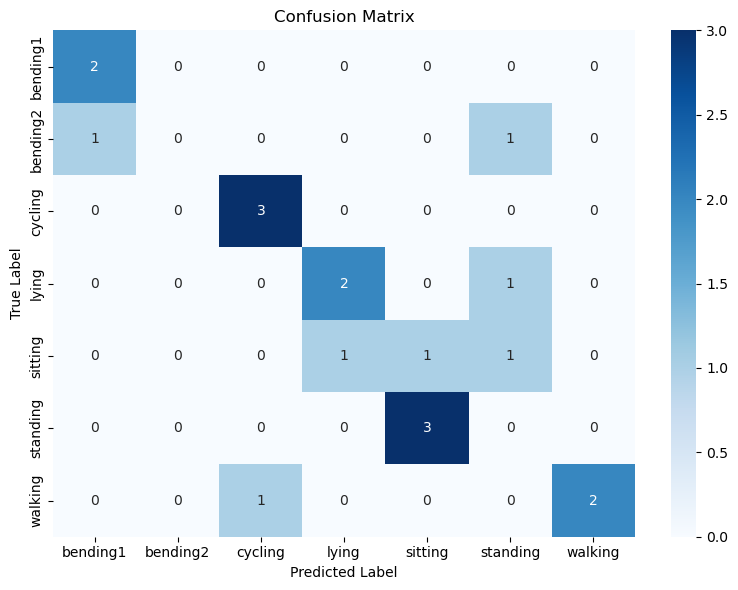

l = 7
Cross Validation Scores: [0.5        0.5        0.42857143 0.5        0.53846154]
Test Accuracy: 0.6842


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


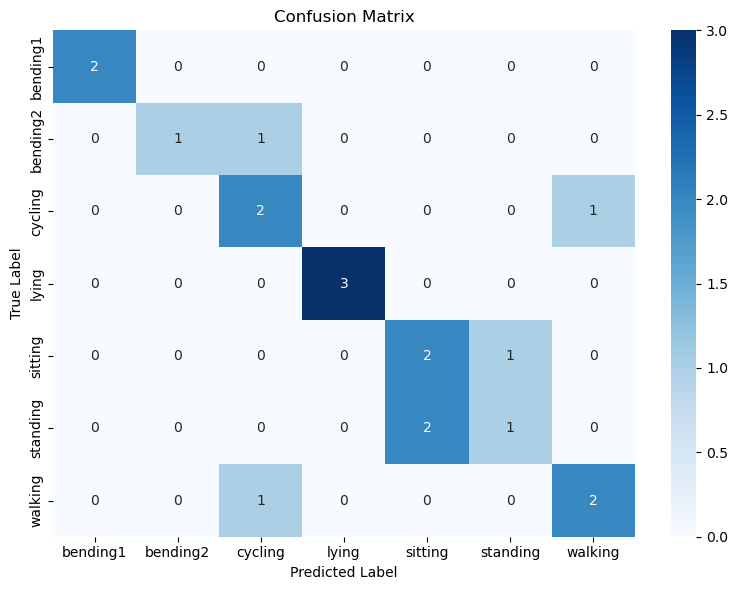

l = 8


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.5        0.64285714 0.71428571 0.57142857 0.46153846]


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Test Accuracy: 0.4737


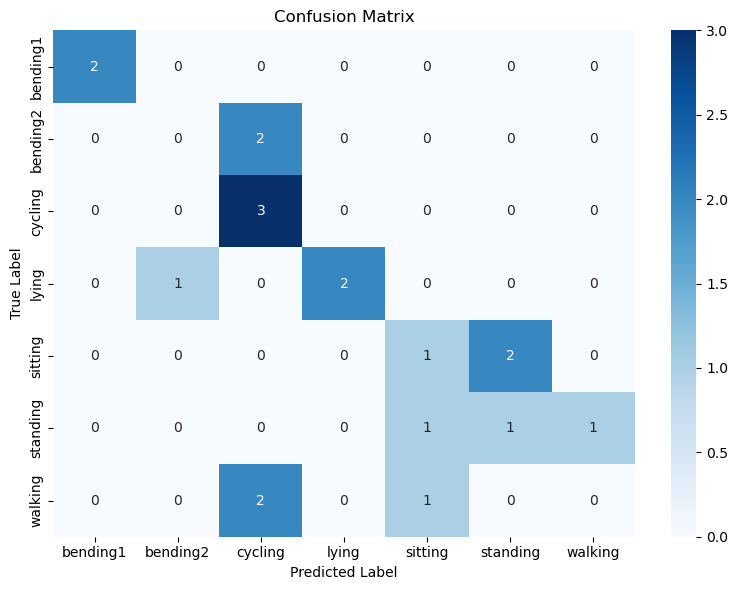

l = 9


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Cross Validation Scores: [0.71428571 0.85714286 0.57142857 0.71428571 0.61538462]
Test Accuracy: 0.6842


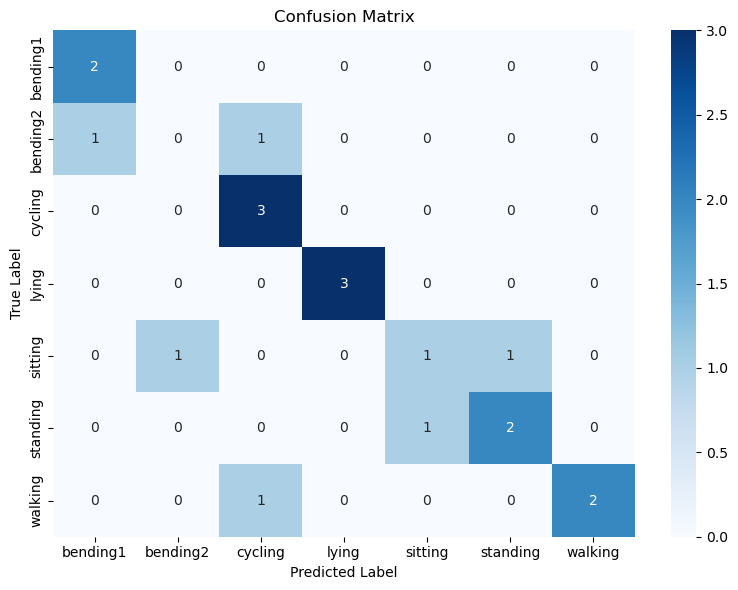

l = 10
Cross Validation Scores: [0.85714286 0.71428571 0.64285714 0.57142857 0.76923077]
Test Accuracy: 0.6316


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


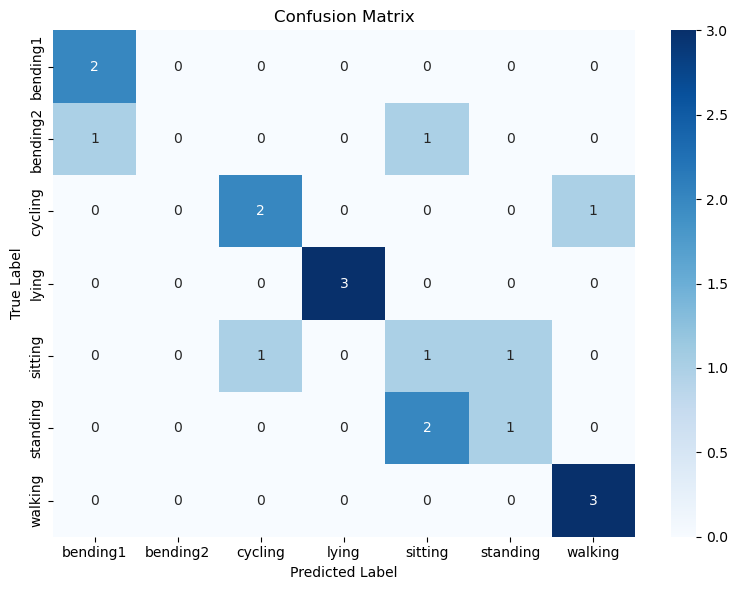

l = 11


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Cross Validation Scores: [0.5        0.64285714 0.5        0.35714286 0.38461538]
Test Accuracy: 0.3684


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


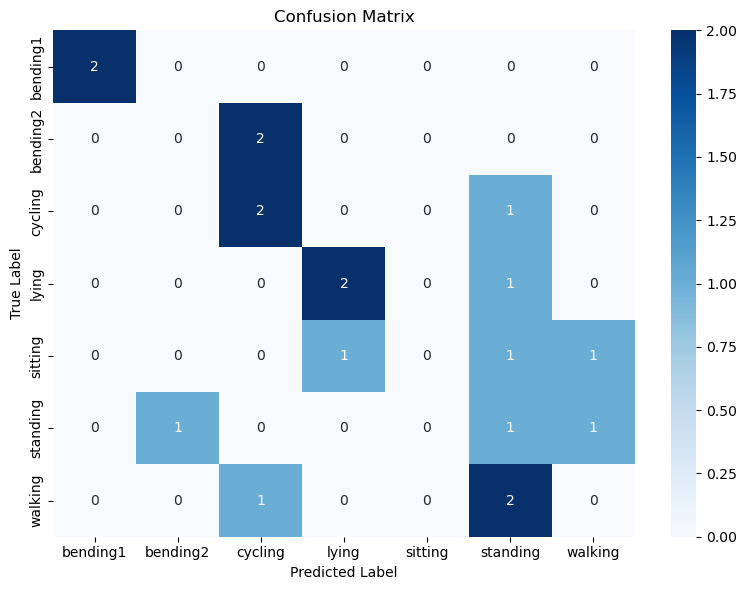

l = 12


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Cross Validation Scores: [0.64285714 0.64285714 0.57142857 0.57142857 0.61538462]
Test Accuracy: 0.6842


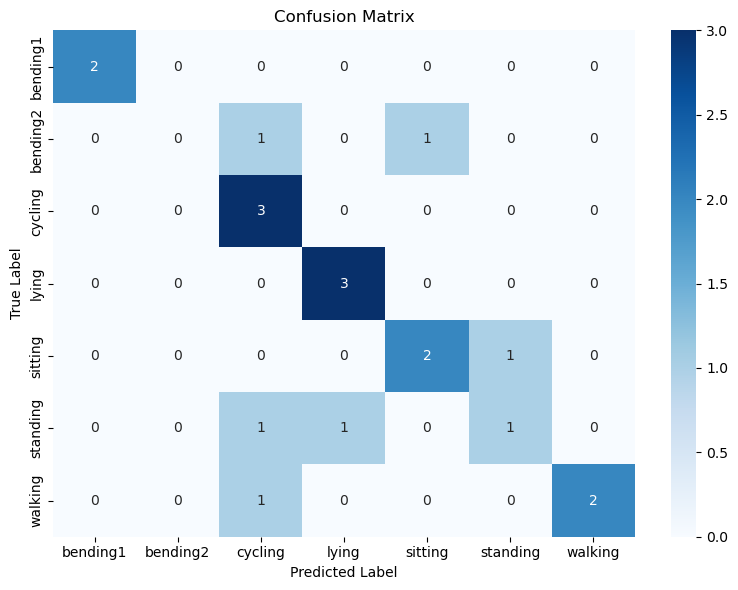

l = 13


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.71428571 0.57142857 0.57142857 0.78571429 0.69230769]
Test Accuracy: 0.5789


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


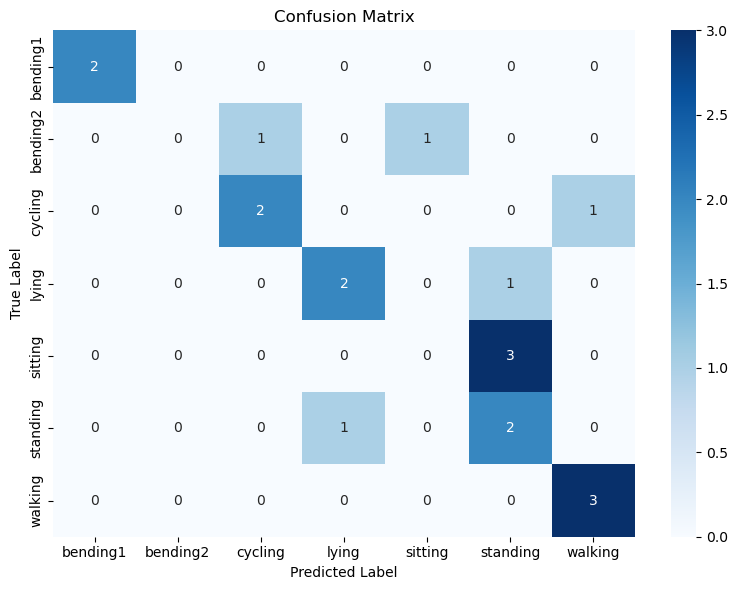

/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


l = 14
Cross Validation Scores: [0.42857143 0.57142857 0.57142857 0.57142857 0.46153846]
Test Accuracy: 0.5263


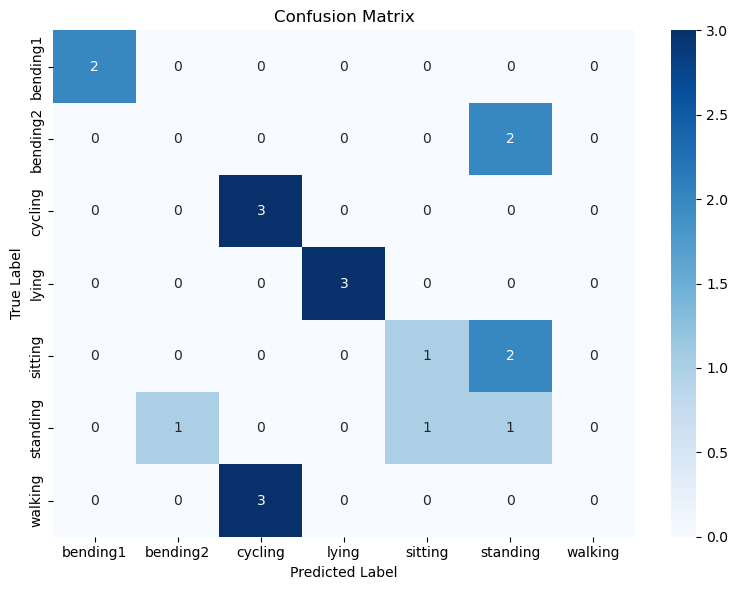

l = 15
Cross Validation Scores: [0.64285714 0.57142857 0.78571429 0.5        0.61538462]


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Test Accuracy: 0.6316


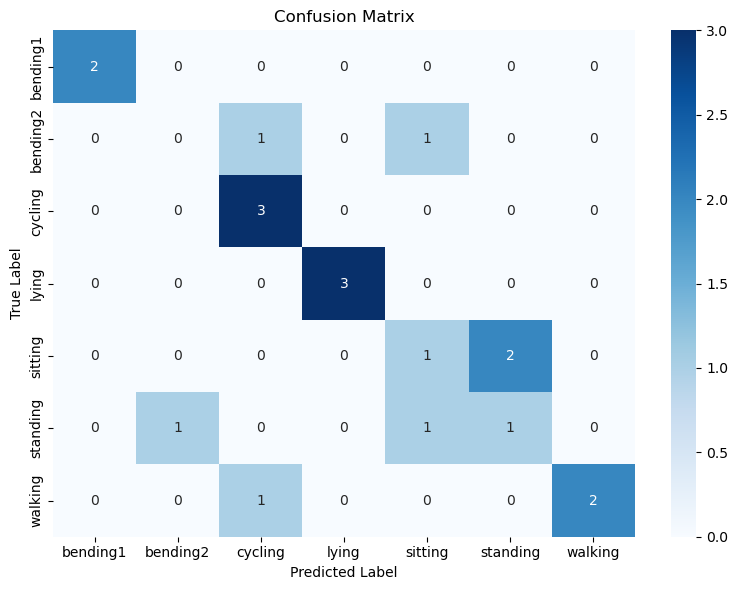

l = 16


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Cross Validation Scores: [0.64285714 0.78571429 0.71428571 0.64285714 0.46153846]
Test Accuracy: 0.7368


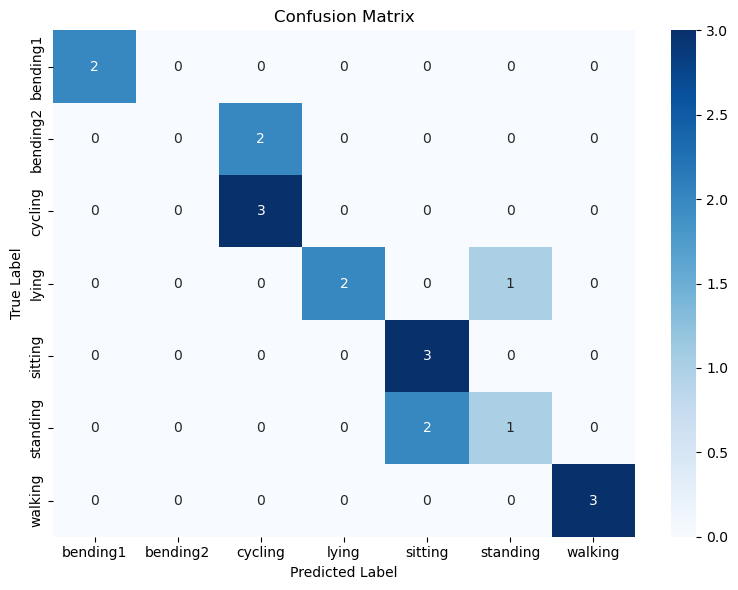

l = 17


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Cross Validation Scores: [0.5        0.5        0.42857143 0.5        0.61538462]
Test Accuracy: 0.6316


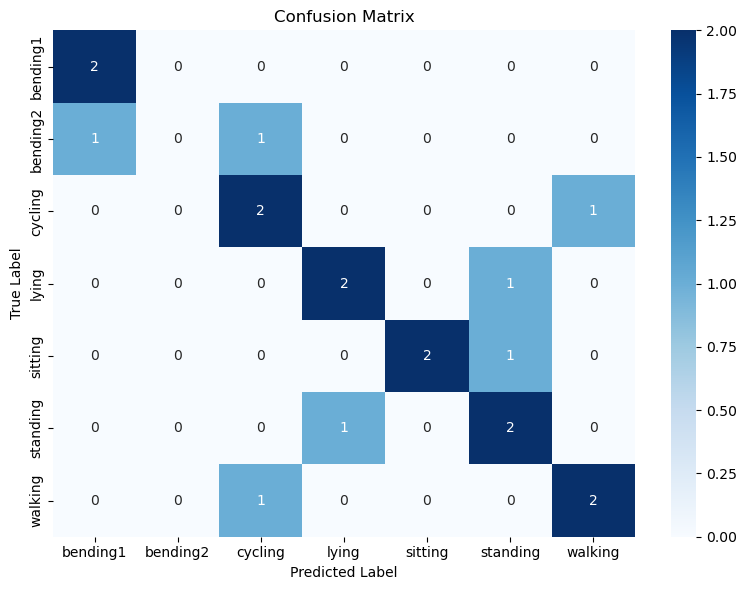

l = 18


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Cross Validation Scores: [0.5        0.57142857 0.57142857 0.78571429 0.38461538]
Test Accuracy: 0.5263


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


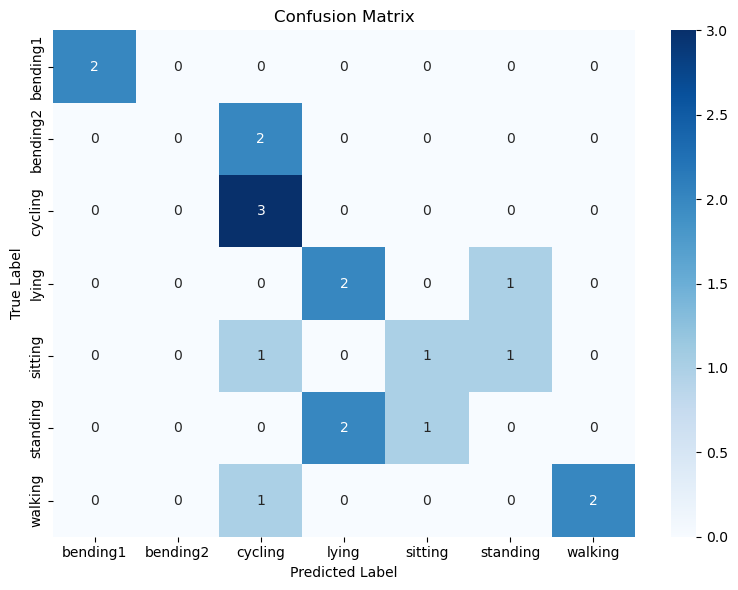

l = 19


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Cross Validation Scores: [0.71428571 0.78571429 0.42857143 0.5        0.61538462]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


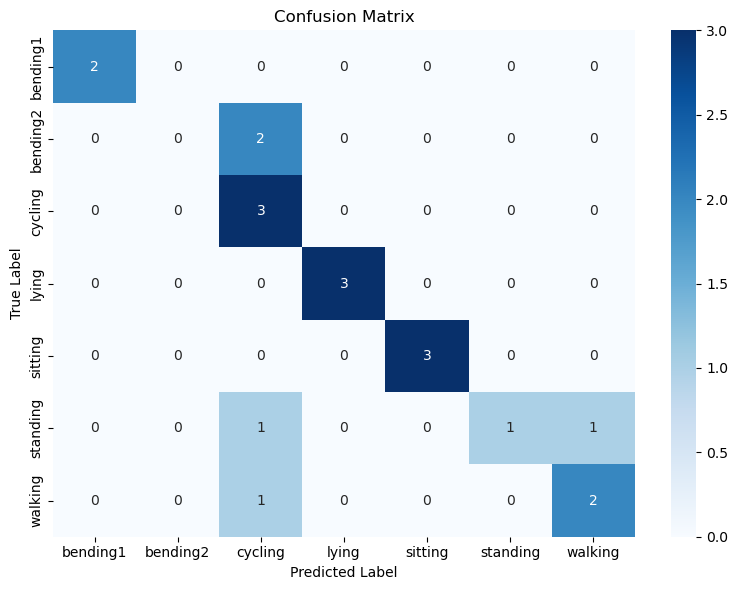

l = 20


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.5        0.5        0.57142857 0.5        0.46153846]
Test Accuracy: 0.5263


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


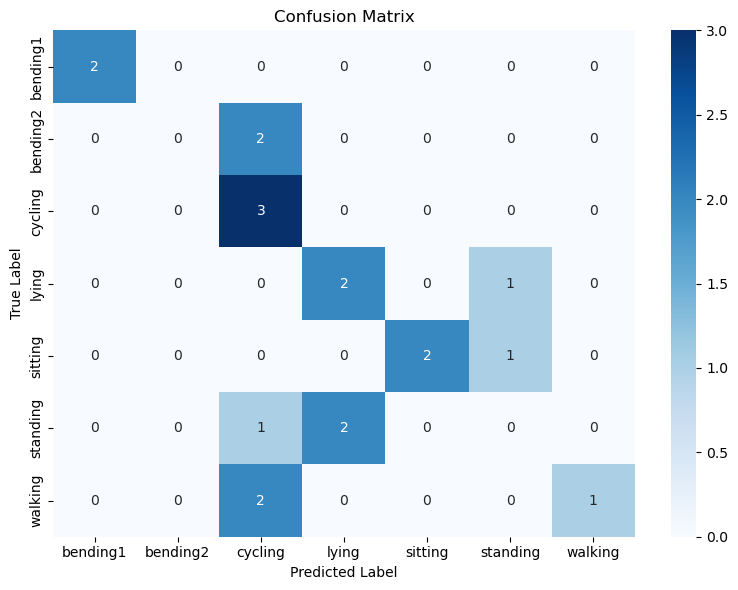

In [14]:
for l in range(1, 21, 1):
    print(f'l = {l}')
    print("Cross Validation Scores:", cross_val_score(model, X_reduced_train[l], Y_train, cv=5))
    model.fit(X_reduced_train[l], Y_train)
    Y_pred = model.predict(X_reduced_test[l])
    print(f'Test Accuracy: {accuracy_score(Y_test, Y_pred):.4f}')
    cm = confusion_matrix(Y_test, Y_pred)
    plt.figure(figsize=(8, 6))
    class_names = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()


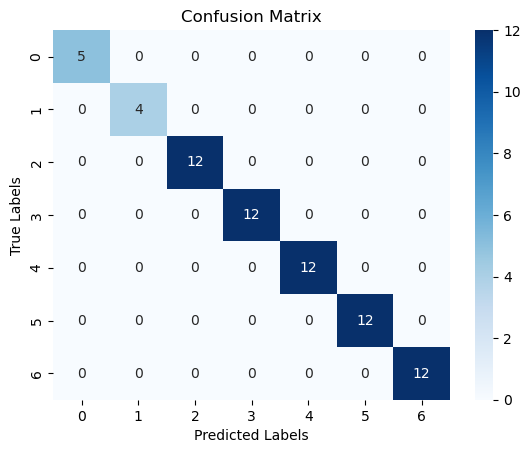

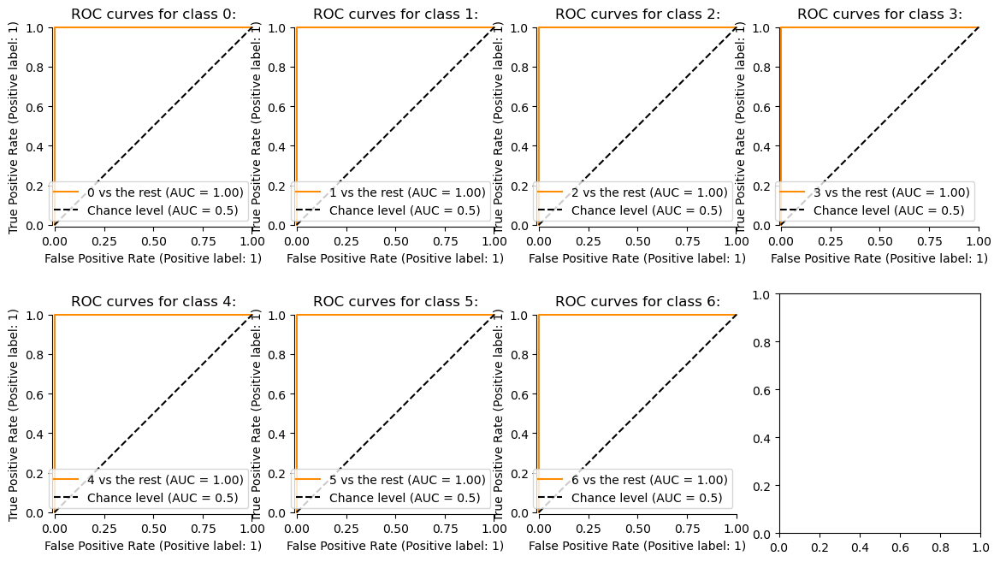

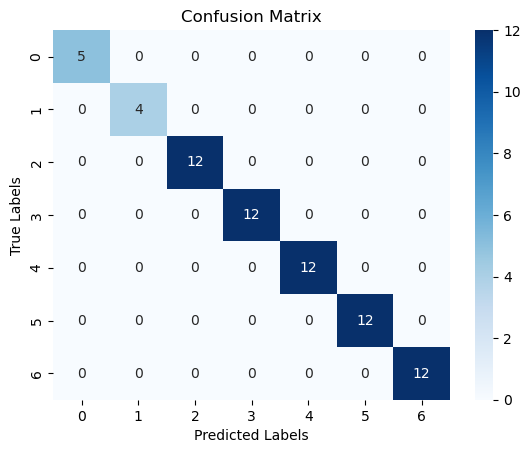

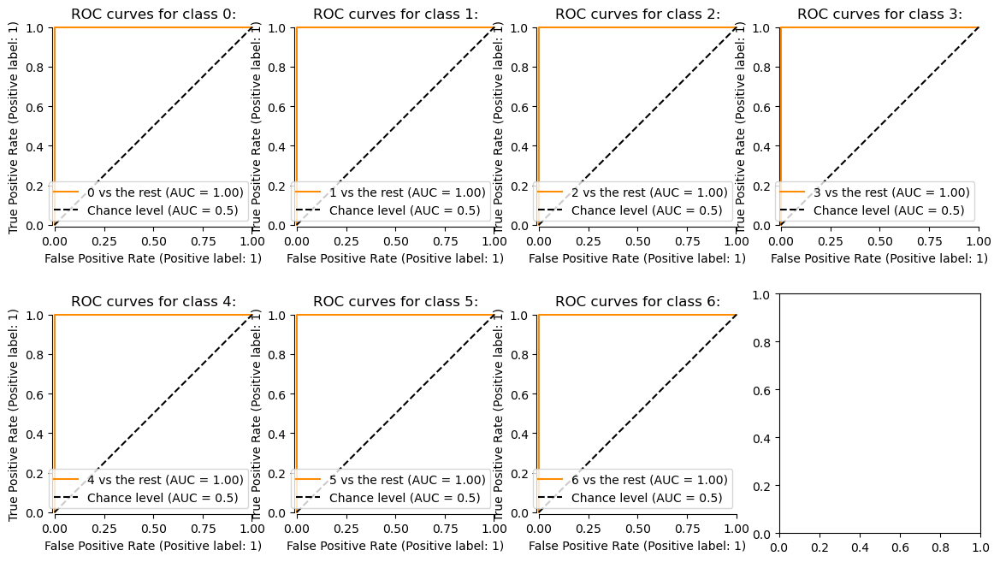

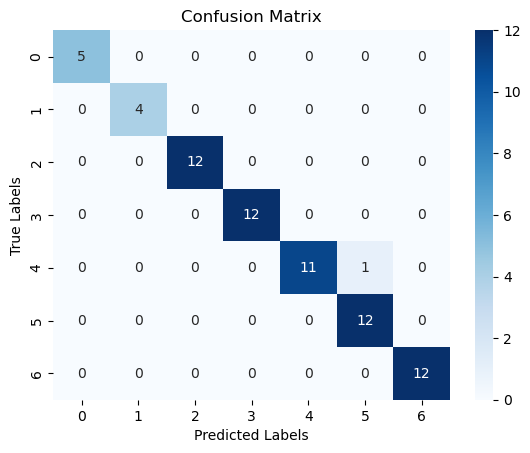

...

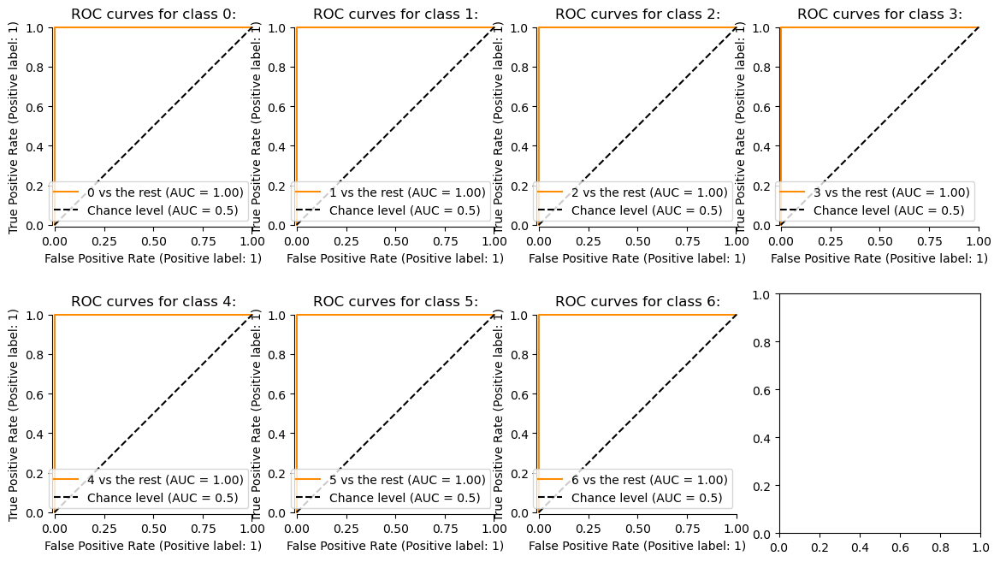

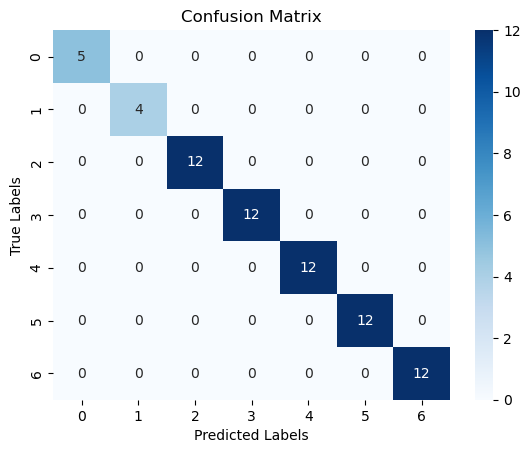

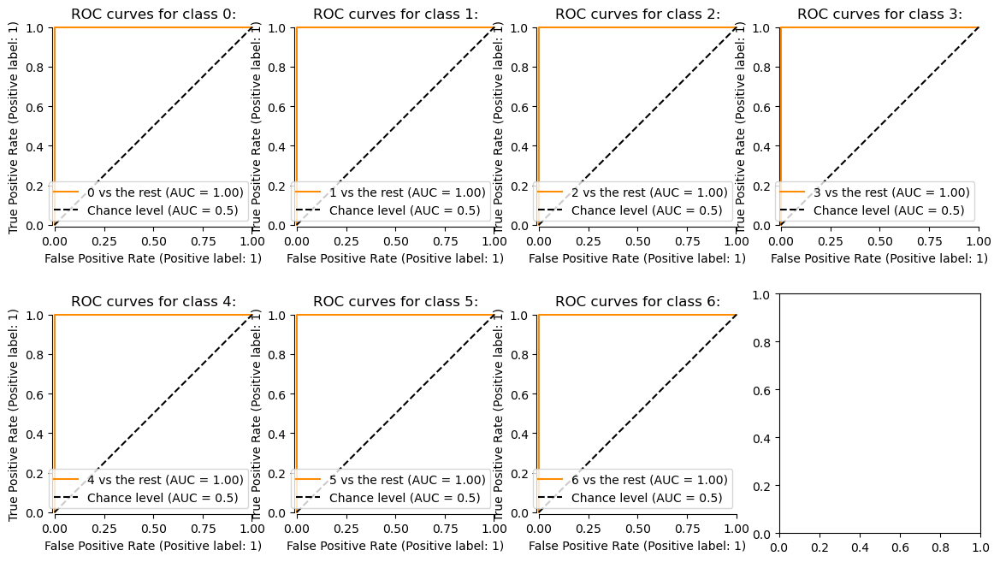

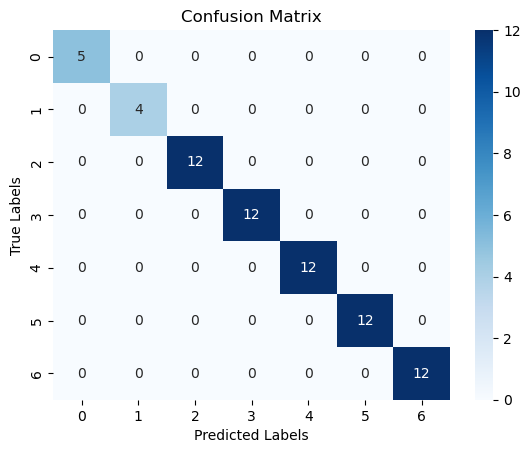

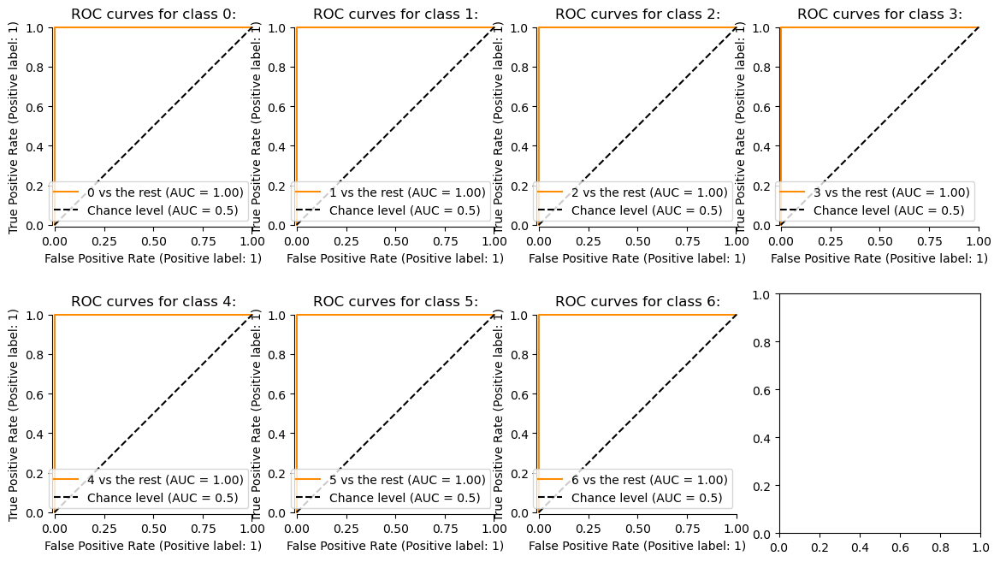

In [15]:
X_reduced_train = {}
X_reduced_test = {}
model = GaussianNB()

for l in range(1, 21, 1):
    model.fit(X_train[l], Y_train)

    Y_pred = model.predict(X_train[l])
    Y_score = model.predict_log_proba(X_train[l])

    cm = confusion_matrix(Y_train, Y_pred)
    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.show()

    fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(14, 8))

    for i in range(len(cm)):
        RocCurveDisplay.from_predictions(
            Y_onehot_train[:, i],
            Y_score[:, i],
            ax=axs[i//4, i-4],
            name=f"{i} vs the rest",
            color="darkorange",
            plot_chance_level=True,
            despine=True,
        )
        axs[i//4, i-4].set_title(f'ROC curves for class {i}:')
        axs[i//4, i-4].plot(
            xlabel="False Positive Rate",
            ylabel="True Positive Rate",
        )

l = 1
Cross Validation Scores: [0.92857143 0.78571429 0.92857143 0.92857143 0.53846154]
Test Accuracy: 0.8947


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


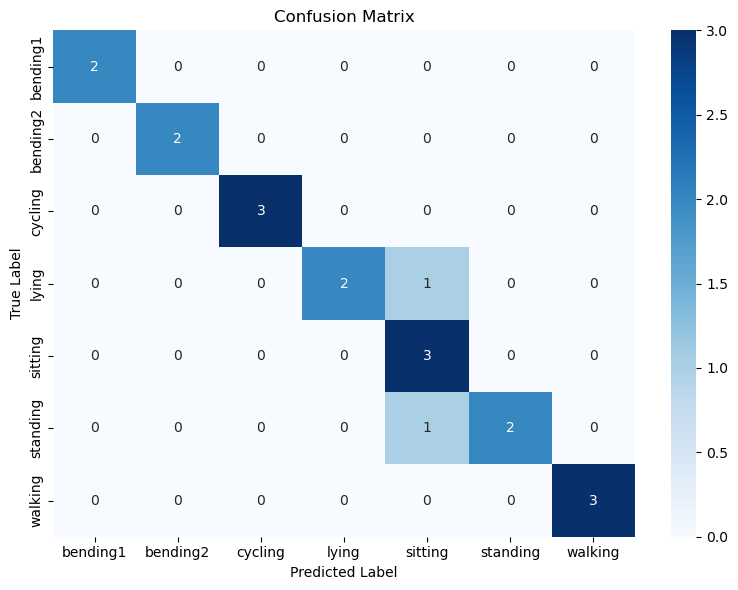

l = 2
Cross Validation Scores: [0.85714286 0.78571429 0.85714286 0.78571429 0.92307692]
Test Accuracy: 0.6316


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


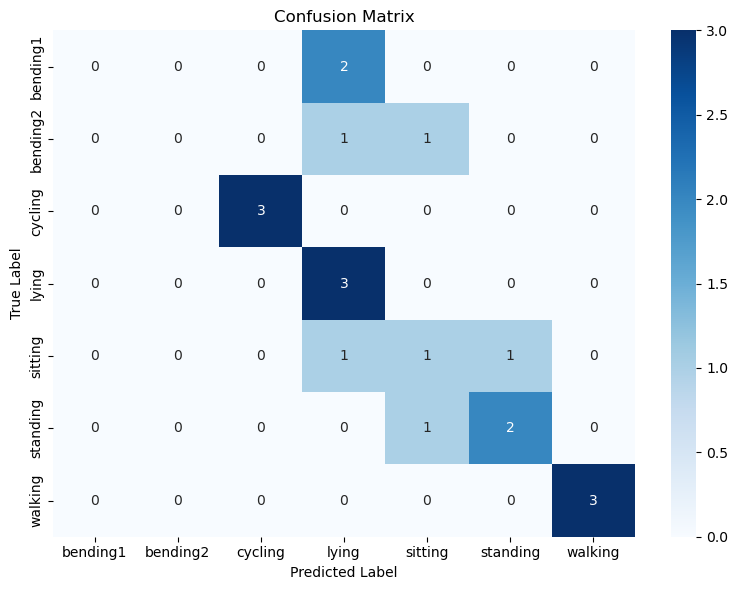

l = 3
Cross Validation Scores: [0.78571429 0.71428571 0.71428571 0.71428571 0.69230769]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


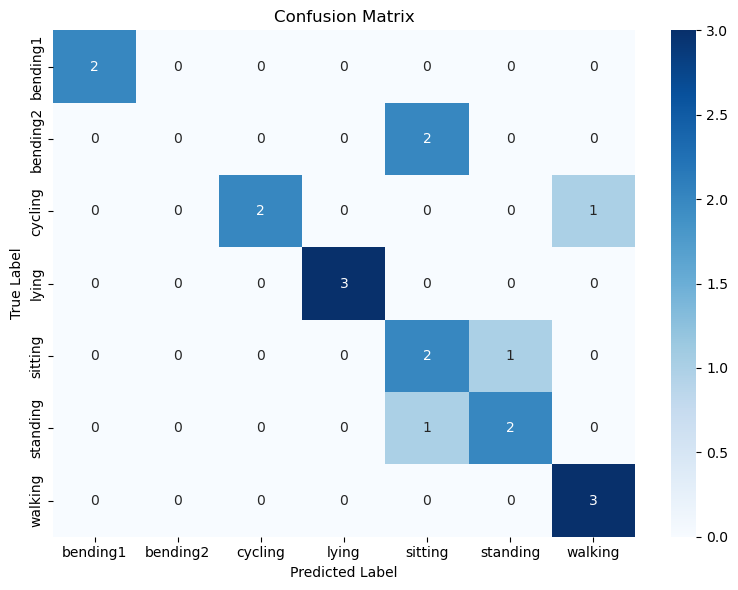

l = 4
Cross Validation Scores: [0.71428571 0.78571429 0.71428571 0.57142857 0.53846154]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


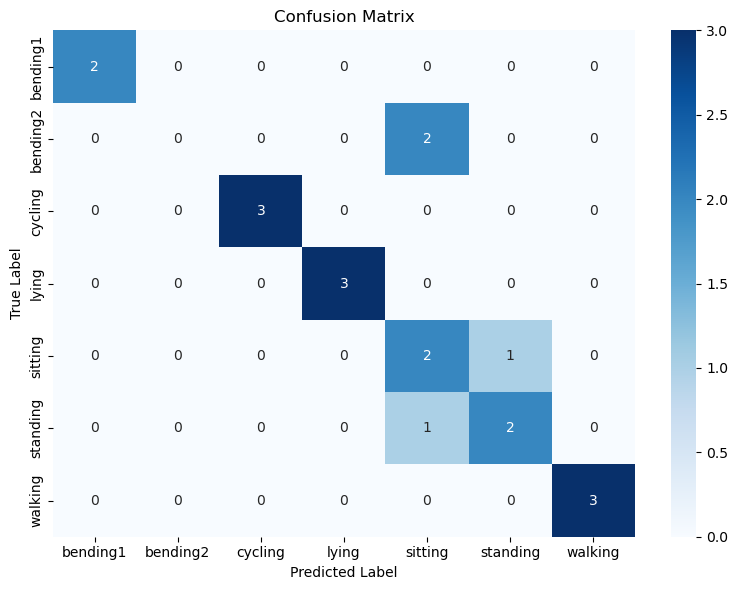

l = 5
Cross Validation Scores: [0.57142857 0.64285714 0.85714286 0.64285714 0.76923077]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


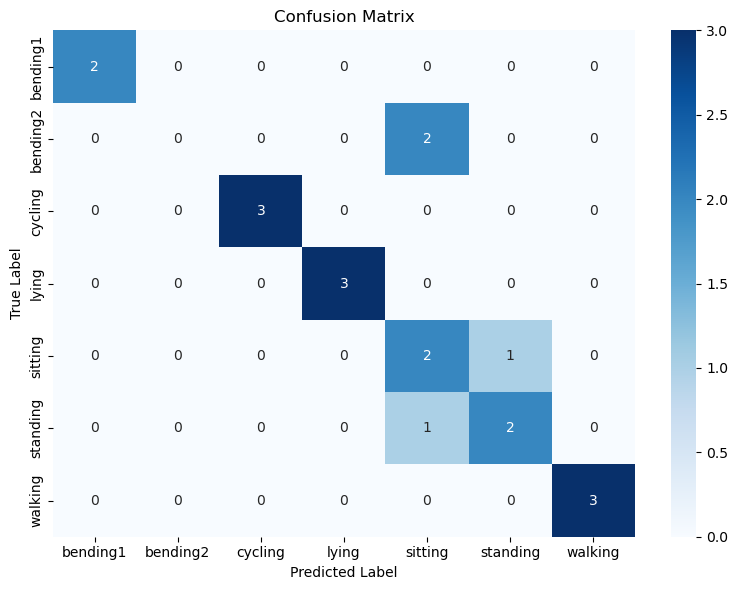

l = 6
Cross Validation Scores: [0.57142857 0.71428571 0.64285714 0.71428571 0.69230769]
Test Accuracy: 0.6316


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


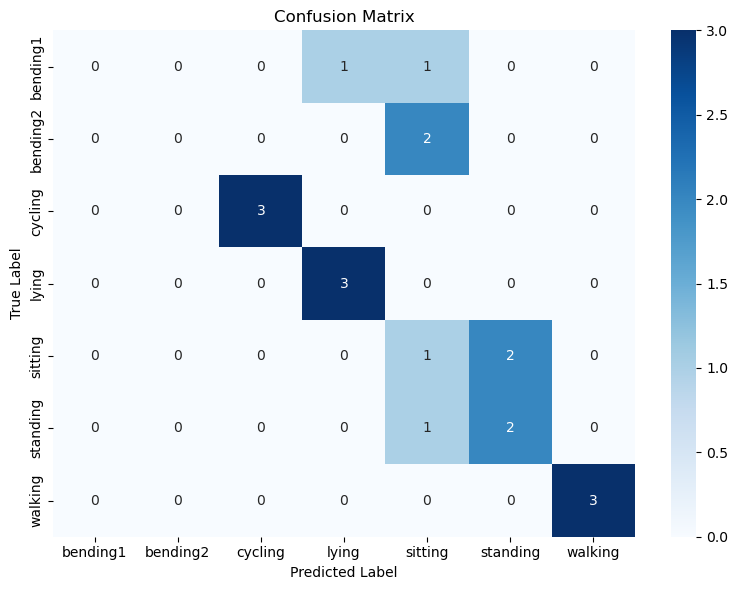

l = 7
Cross Validation Scores: [0.64285714 0.85714286 0.71428571 0.5        0.69230769]
Test Accuracy: 0.6842


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


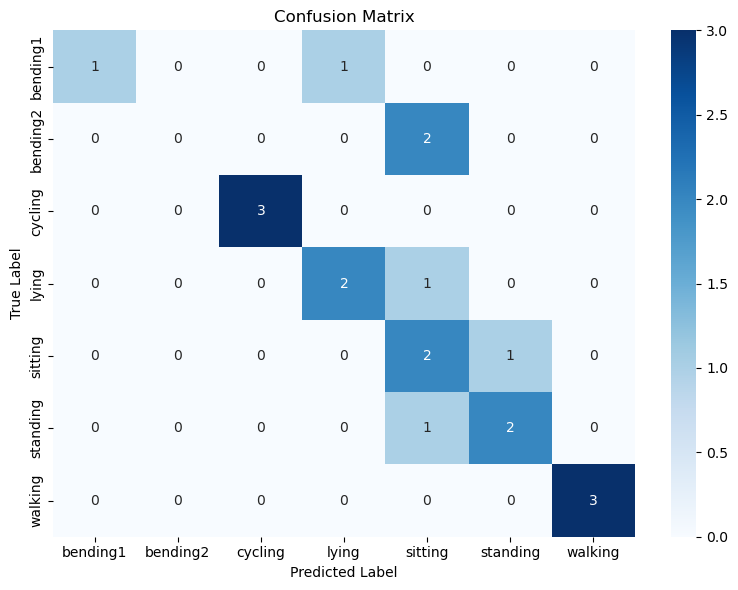

l = 8
Cross Validation Scores: [0.78571429 0.78571429 0.64285714 0.64285714 0.61538462]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


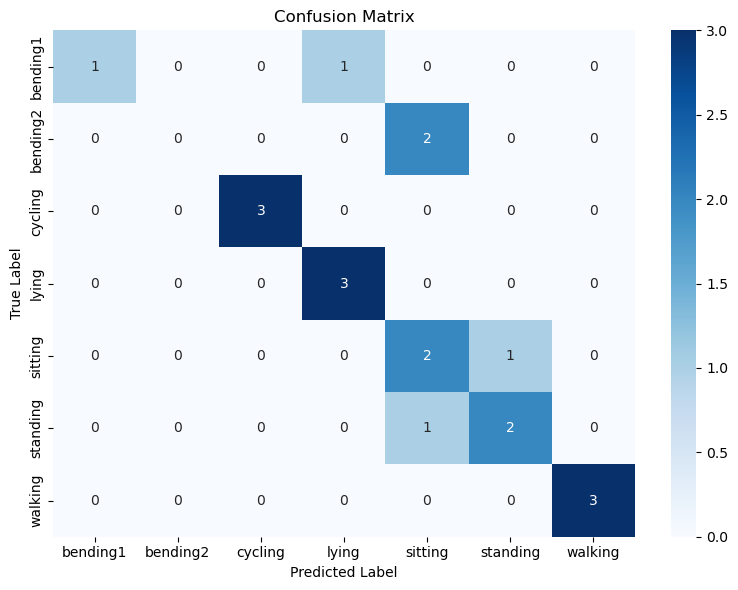

l = 9
Cross Validation Scores: [0.64285714 0.78571429 0.64285714 0.64285714 0.53846154]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


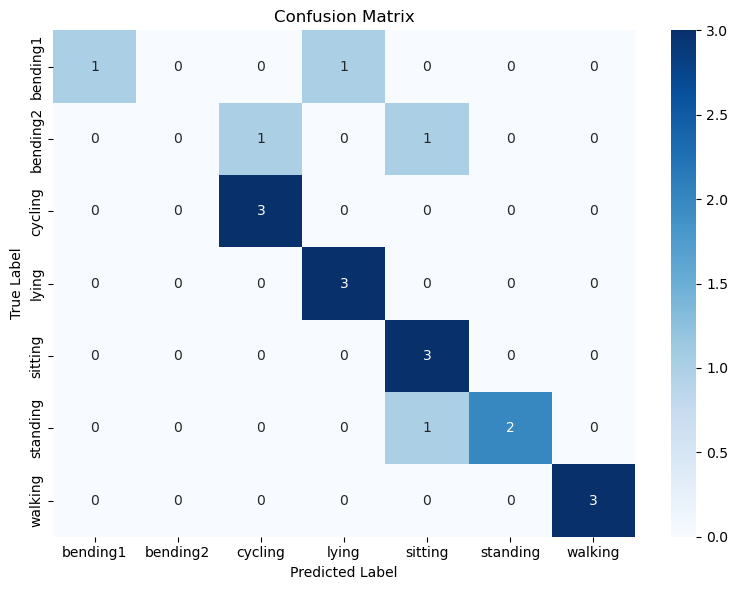

l = 10
Cross Validation Scores: [0.5        0.71428571 0.71428571 0.64285714 0.69230769]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


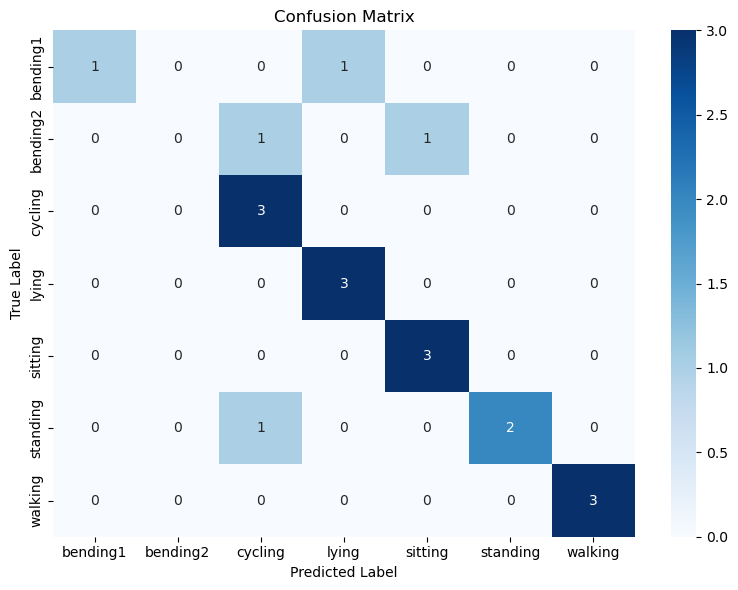

l = 11
Cross Validation Scores: [0.71428571 0.64285714 0.57142857 0.42857143 0.69230769]
Test Accuracy: 0.5789


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


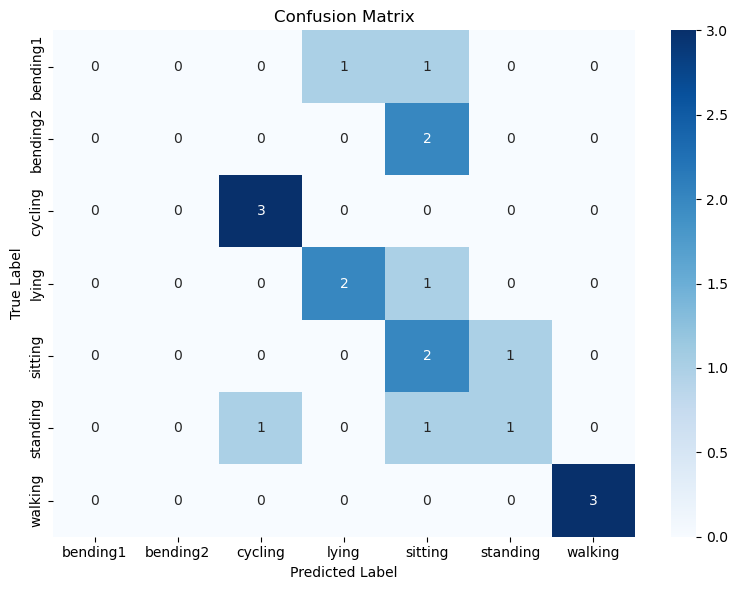

l = 12
Cross Validation Scores: [0.57142857 0.71428571 0.57142857 0.5        0.53846154]
Test Accuracy: 0.6316


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


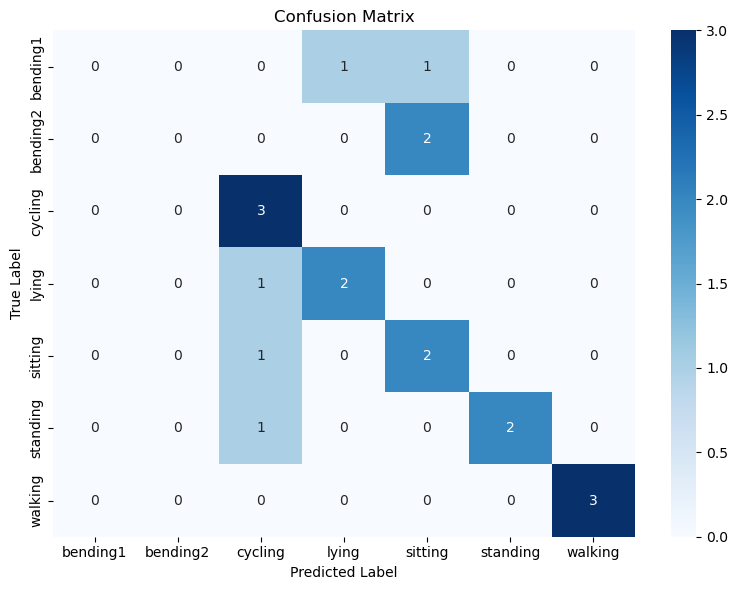

l = 13
Cross Validation Scores: [0.64285714 0.64285714 0.57142857 0.42857143 0.61538462]
Test Accuracy: 0.6842


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


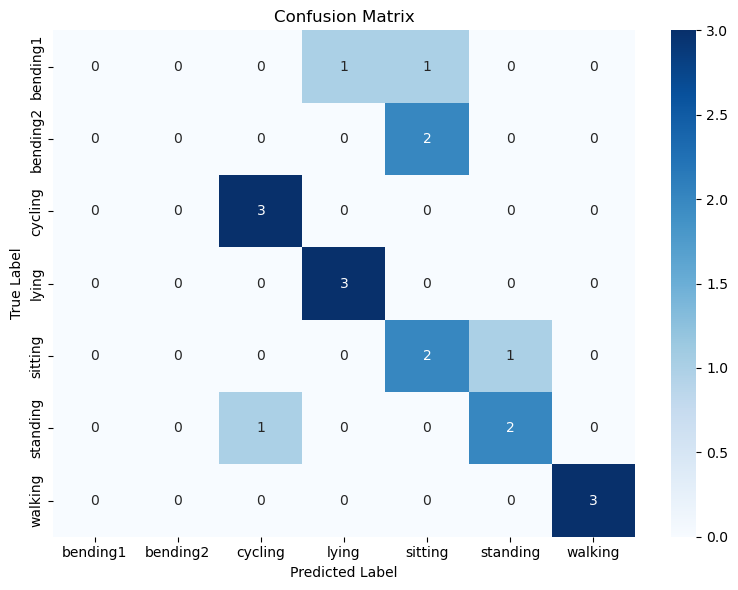

l = 14
Cross Validation Scores: [0.64285714 0.57142857 0.57142857 0.64285714 0.53846154]
Test Accuracy: 0.5789


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


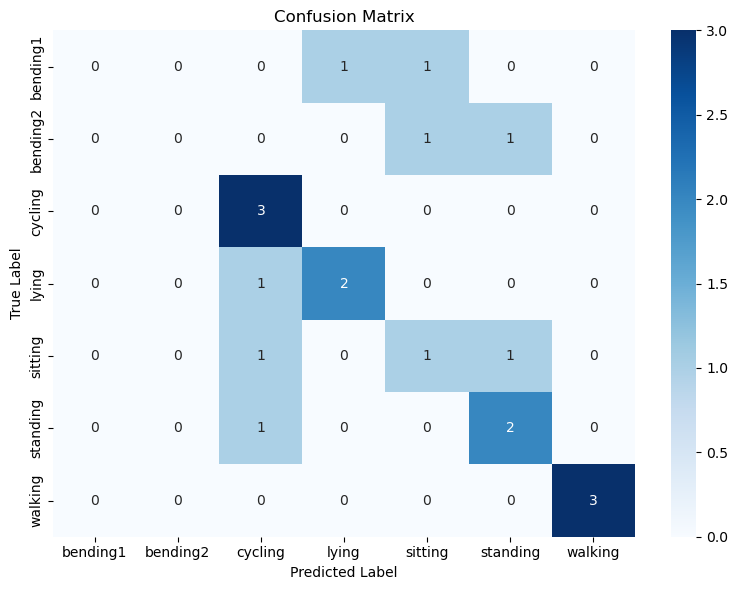

l = 15
Cross Validation Scores: [0.57142857 0.64285714 0.5        0.64285714 0.53846154]
Test Accuracy: 0.5789


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


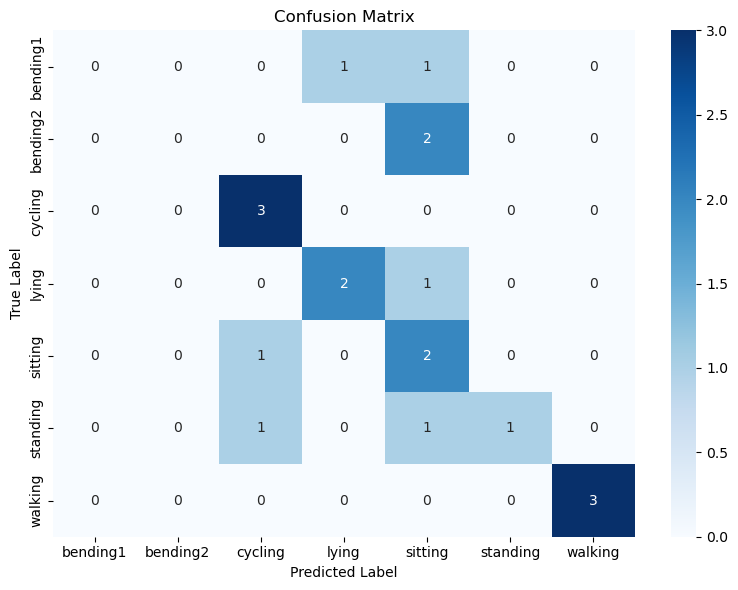

l = 16
Cross Validation Scores: [0.64285714 0.57142857 0.64285714 0.5        0.53846154]
Test Accuracy: 0.5263


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


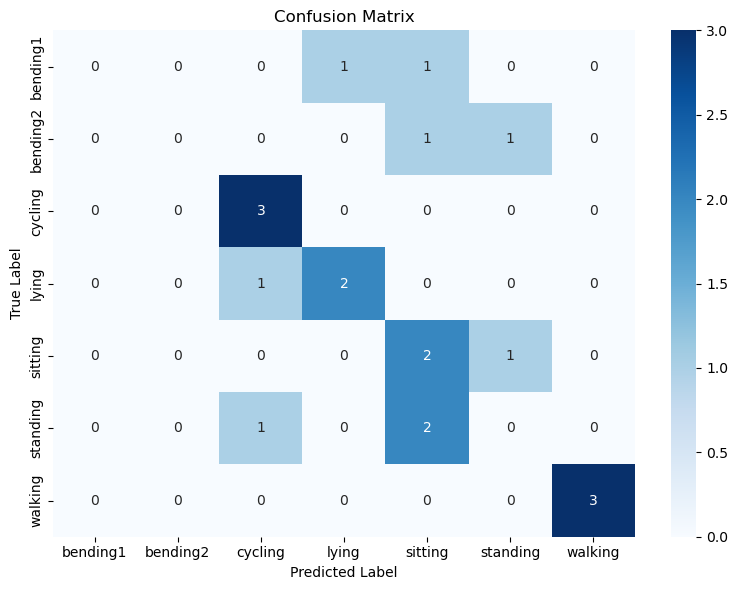

l = 17
Cross Validation Scores: [0.57142857 0.64285714 0.57142857 0.5        0.61538462]
Test Accuracy: 0.5263


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


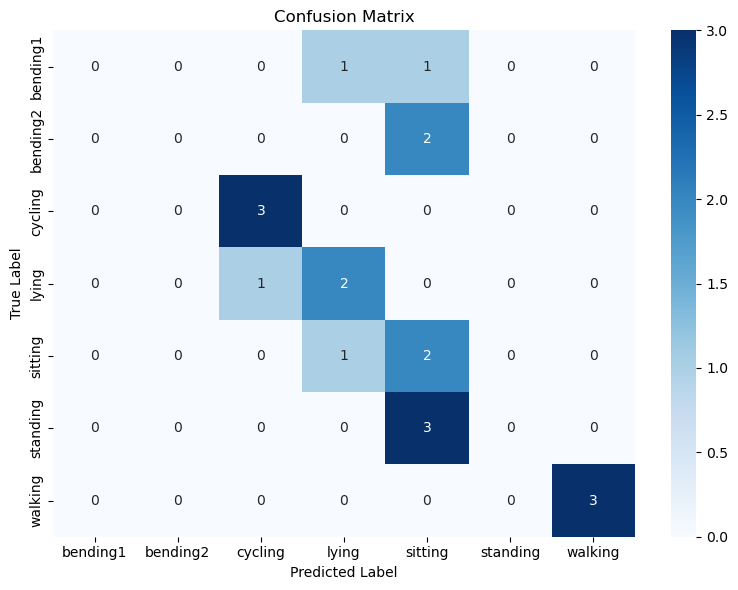

l = 18
Cross Validation Scores: [0.57142857 0.57142857 0.5        0.5        0.53846154]
Test Accuracy: 0.6316


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


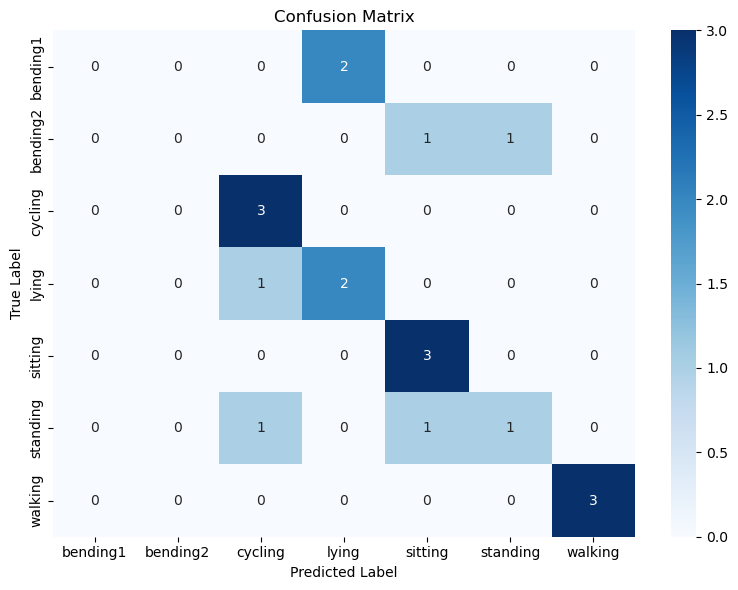

l = 19
Cross Validation Scores: [0.64285714 0.57142857 0.5        0.5        0.53846154]
Test Accuracy: 0.6316


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


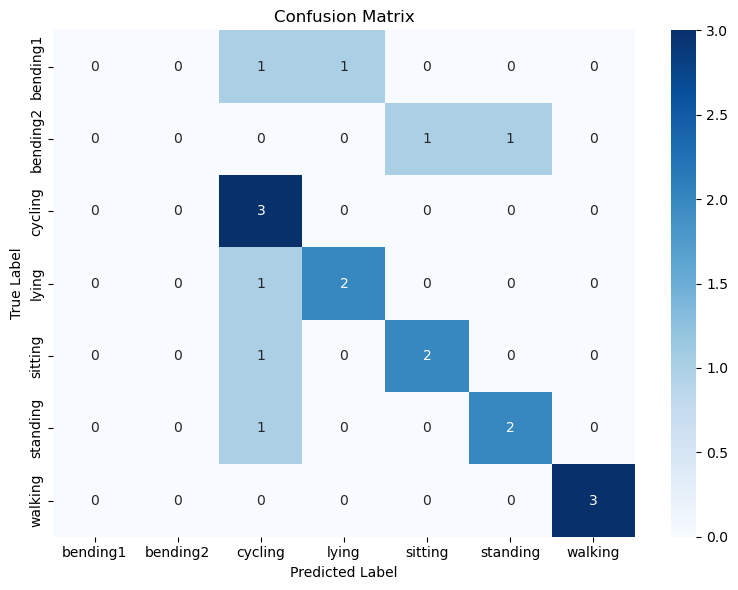

l = 20
Cross Validation Scores: [0.64285714 0.57142857 0.5        0.57142857 0.53846154]
Test Accuracy: 0.5789


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


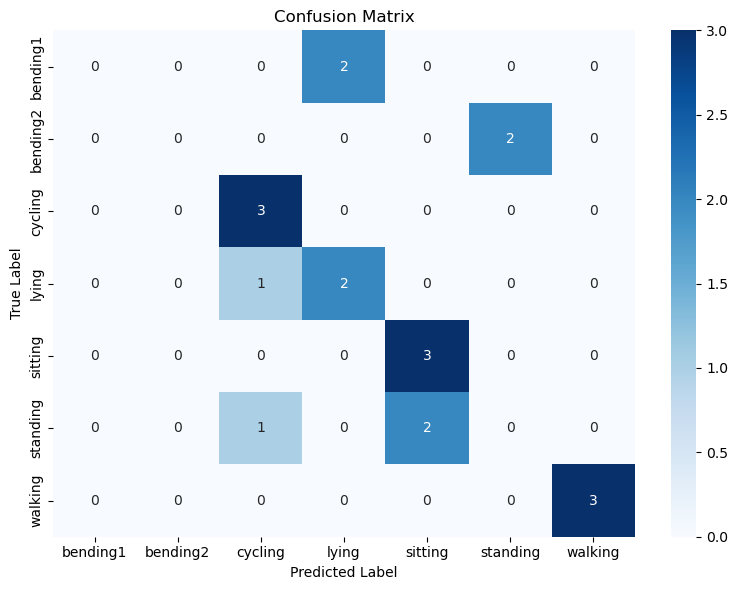

In [16]:
for l in range(1, 21, 1):
    print(f'l = {l}')
    print("Cross Validation Scores:", cross_val_score(model, X_train[l], Y_train, cv=5))
    model.fit(X_train[l], Y_train)
    Y_pred = model.predict(X_test[l])
    print(f'Test Accuracy: {accuracy_score(Y_test, Y_pred):.4f}')
    cm = confusion_matrix(Y_test, Y_pred)
    plt.figure(figsize=(8, 6))
    class_names = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()


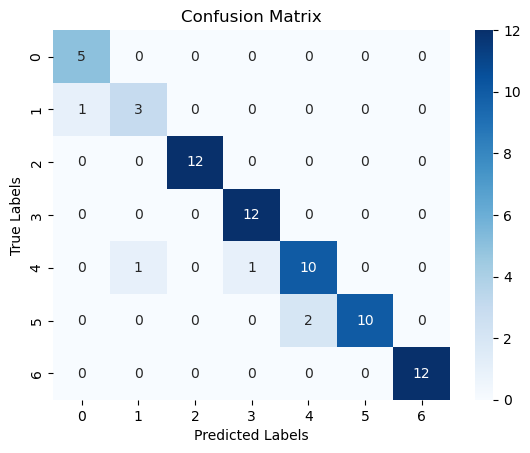

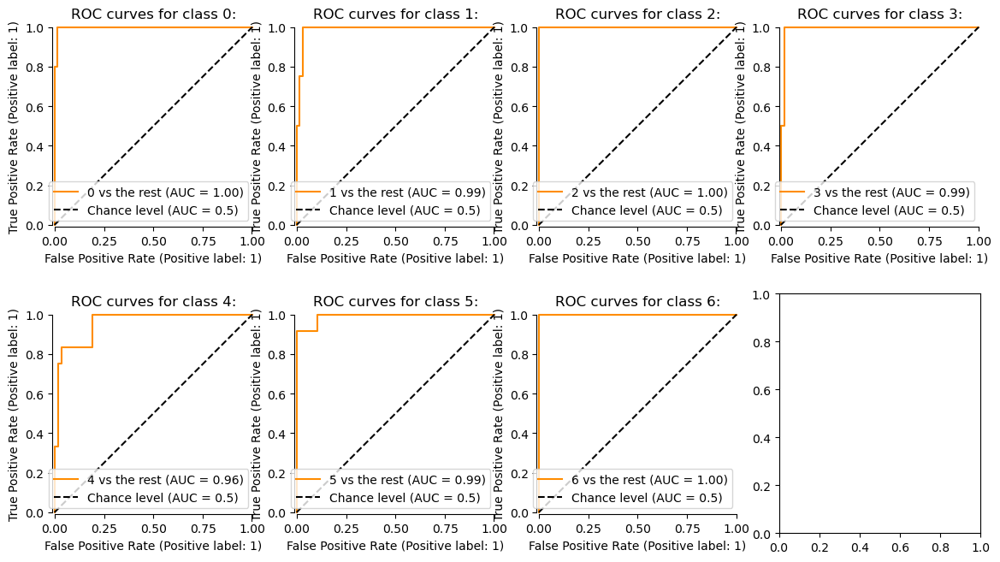

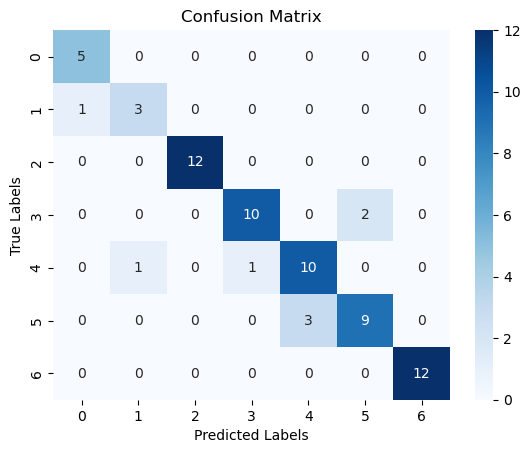

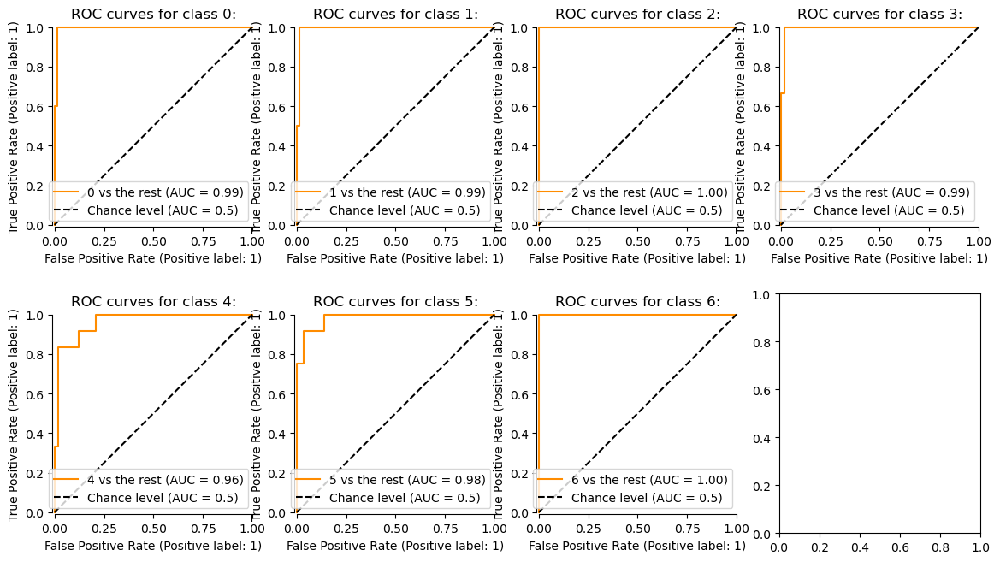

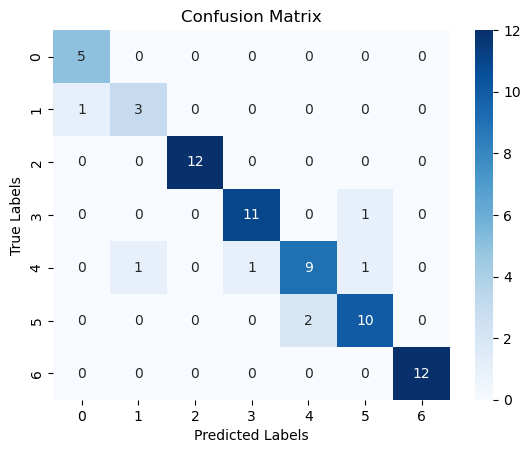

...

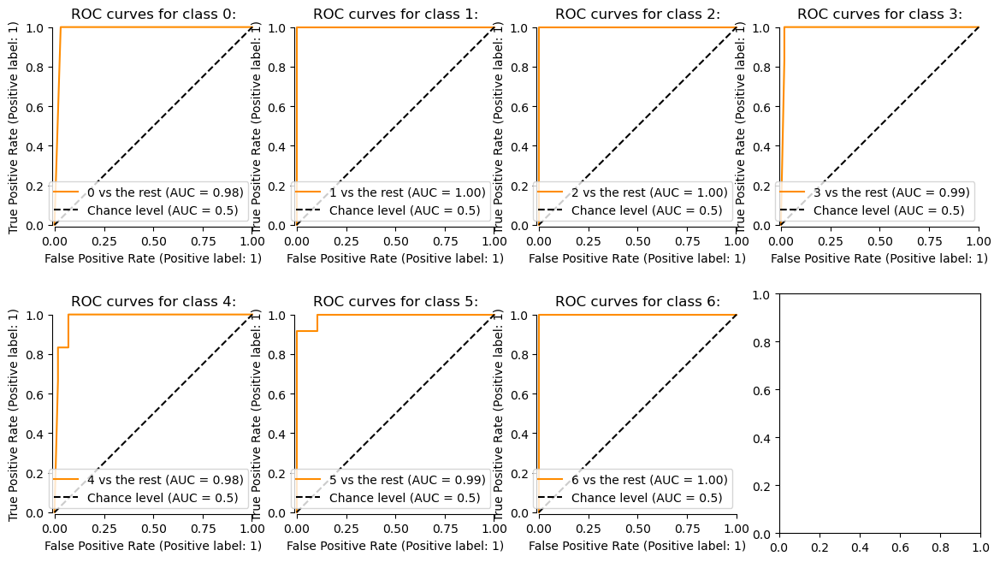

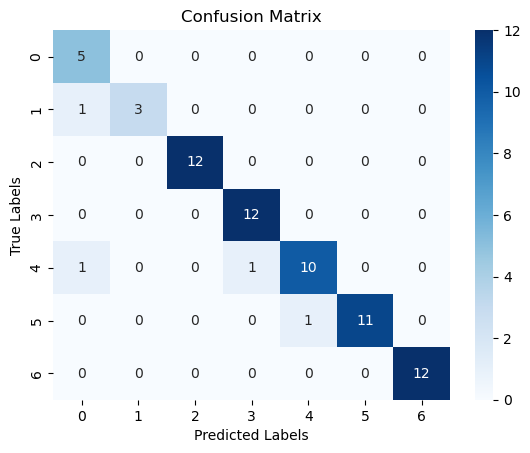

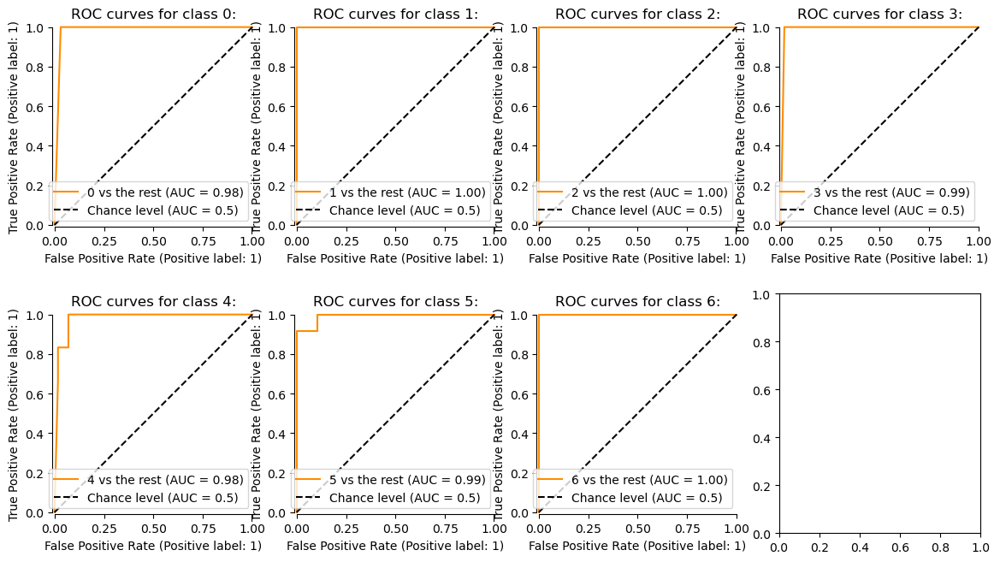

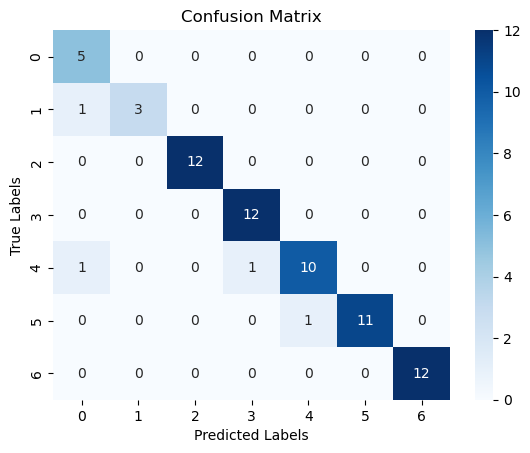

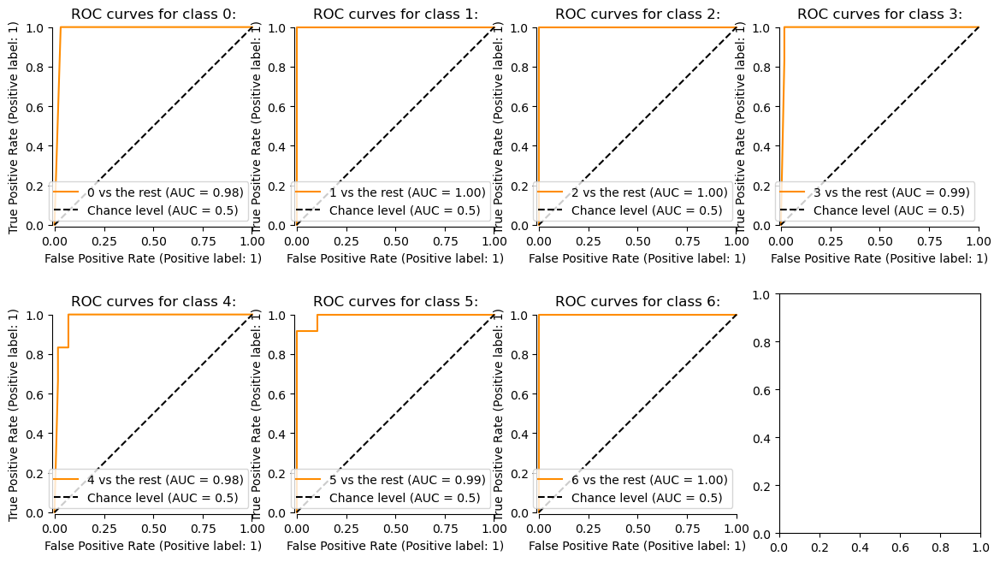

In [17]:
X_reduced_train = {}
X_reduced_test = {}
model = MultinomialNB()

for l in range(1, 21, 1):
    model.fit(X_train[l], Y_train)

    Y_pred = model.predict(X_train[l])
    Y_score = model.predict_log_proba(X_train[l])

    cm = confusion_matrix(Y_train, Y_pred)
    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.show()


    fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(14, 8))

    for i in range(len(cm)):
        RocCurveDisplay.from_predictions(
            Y_onehot_train[:, i],
            Y_score[:, i],
            ax=axs[i//4, i-4],
            name=f"{i} vs the rest",
            color="darkorange",
            plot_chance_level=True,
            despine=True,
        )
        axs[i//4, i-4].set_title(f'ROC curves for class {i}:')
        axs[i//4, i-4].plot(
            xlabel="False Positive Rate",
            ylabel="True Positive Rate",
        )


l = 1
Cross Validation Scores: [0.85714286 0.85714286 0.71428571 0.78571429 0.84615385]
Test Accuracy: 0.8947


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


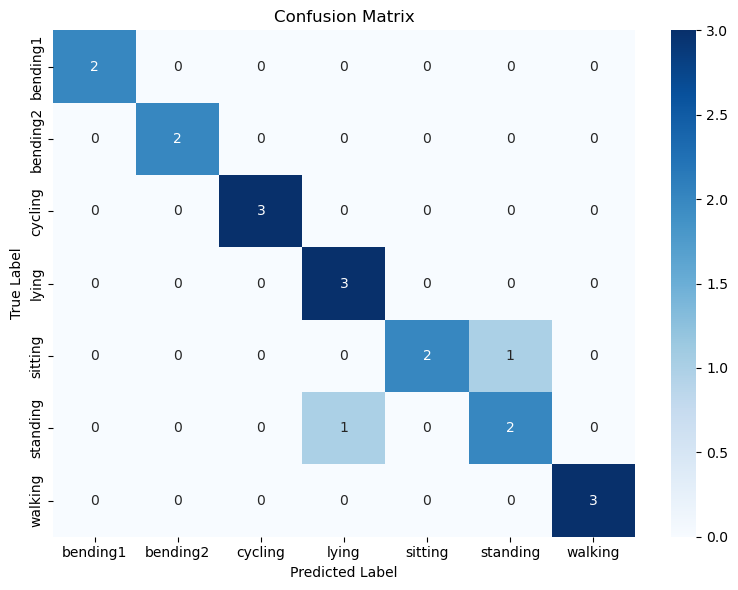

l = 2
Cross Validation Scores: [0.85714286 0.78571429 0.71428571 0.71428571 0.84615385]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


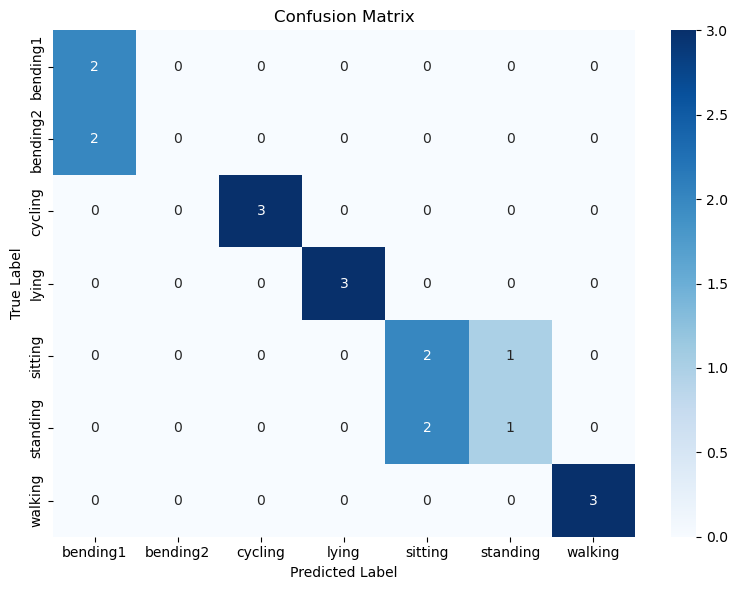

l = 3
Cross Validation Scores: [0.85714286 0.85714286 0.64285714 0.78571429 0.84615385]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


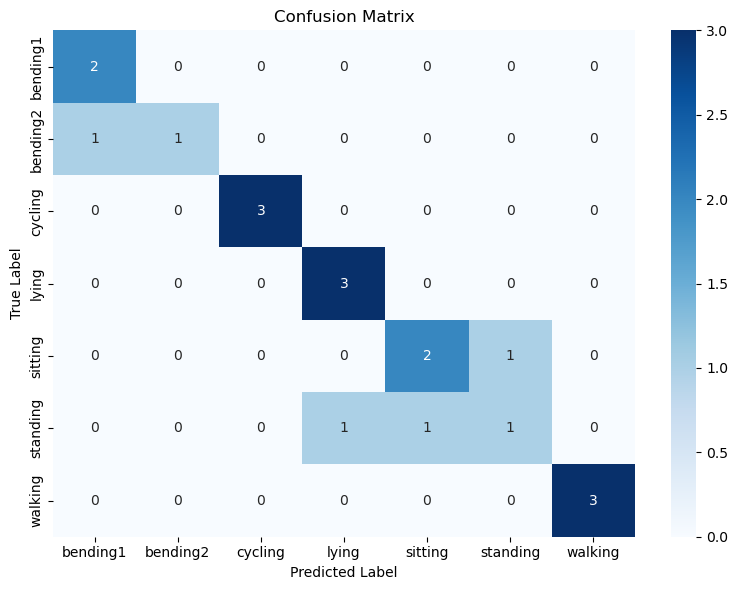

l = 4
Cross Validation Scores: [0.85714286 0.85714286 0.64285714 0.78571429 0.84615385]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


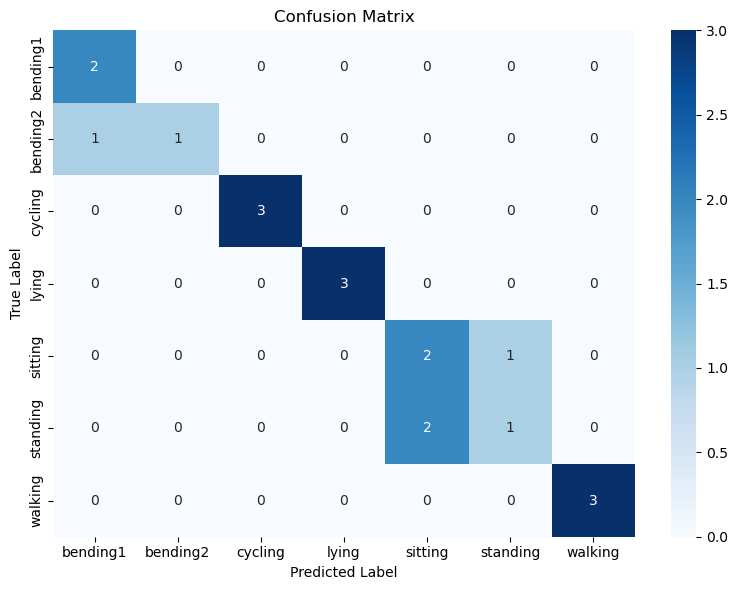

l = 5
Cross Validation Scores: [0.71428571 0.85714286 0.78571429 0.78571429 0.92307692]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


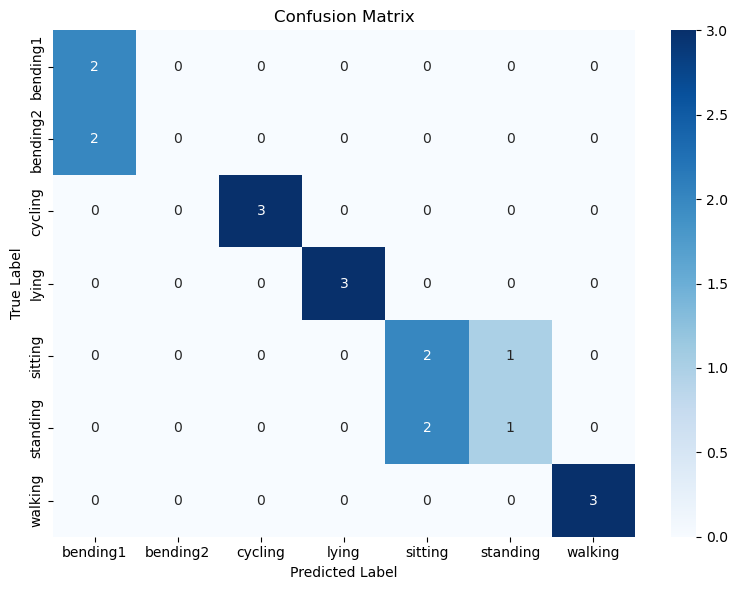

l = 6
Cross Validation Scores: [0.78571429 0.92857143 0.71428571 0.71428571 0.84615385]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


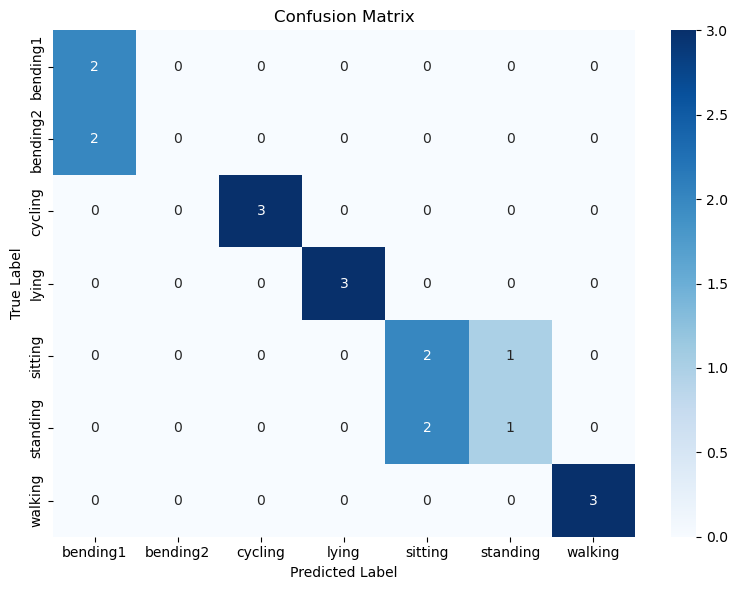

l = 7
Cross Validation Scores: [0.71428571 0.92857143 0.57142857 0.78571429 0.92307692]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


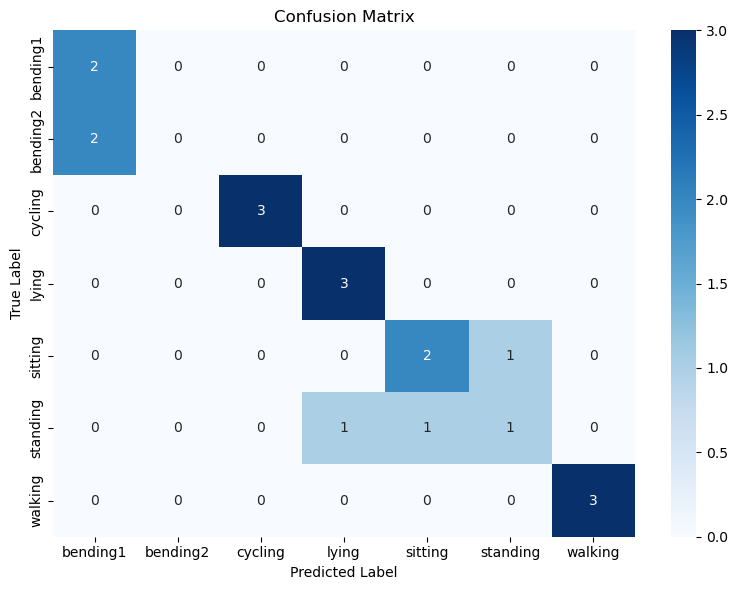

l = 8
Cross Validation Scores: [0.71428571 0.92857143 0.71428571 0.78571429 0.76923077]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


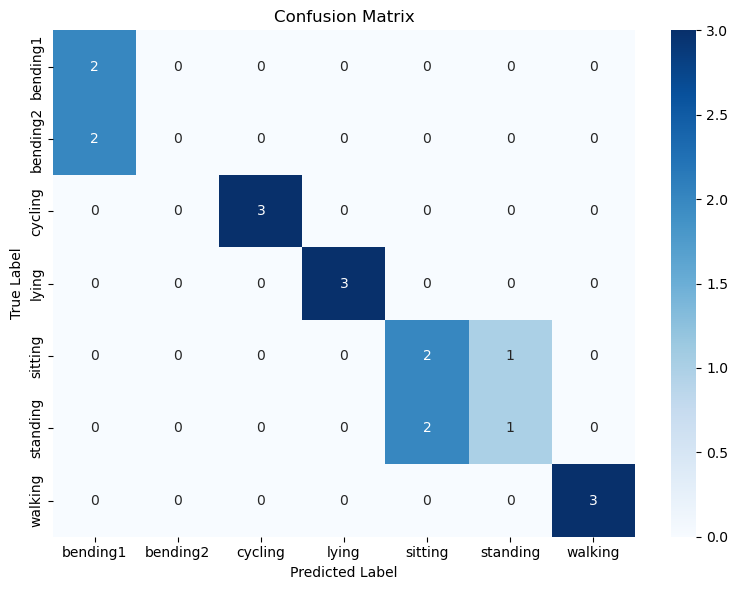

l = 9
Cross Validation Scores: [0.71428571 0.92857143 0.71428571 0.71428571 0.76923077]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


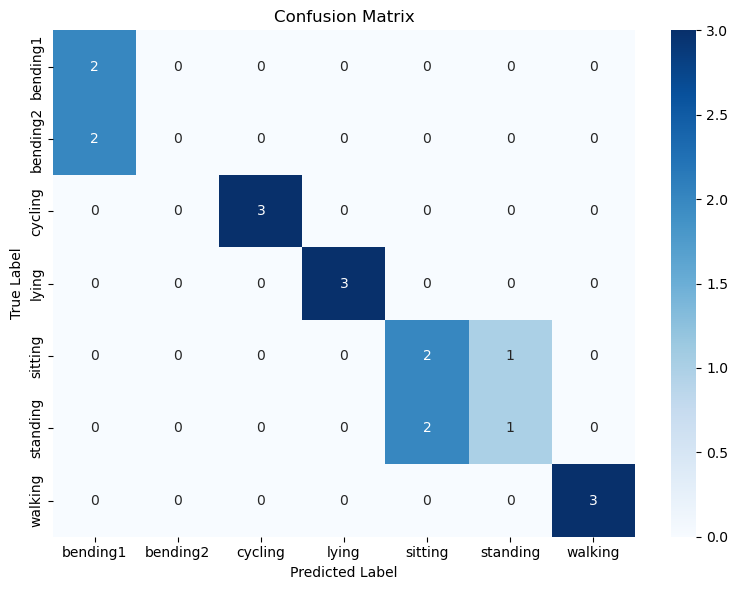

l = 10
Cross Validation Scores: [0.71428571 0.92857143 0.64285714 0.71428571 0.76923077]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


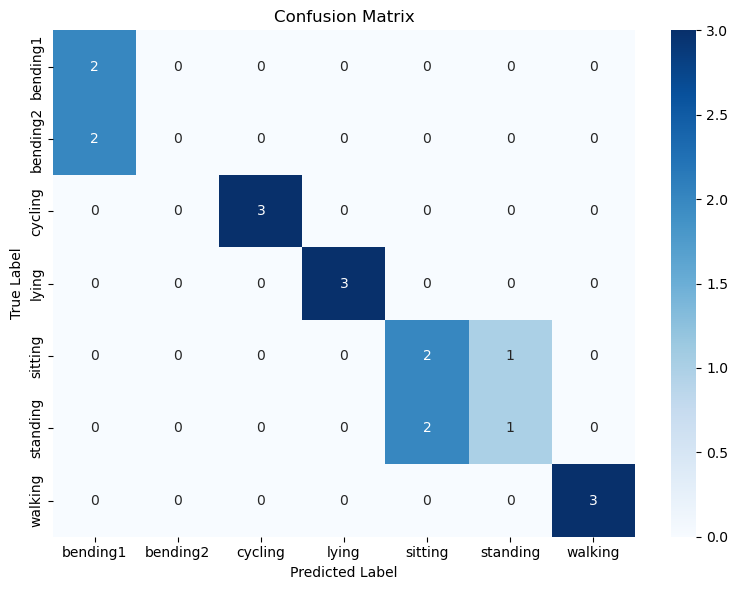

l = 11
Cross Validation Scores: [0.78571429 0.92857143 0.64285714 0.71428571 0.76923077]
Test Accuracy: 0.8421


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


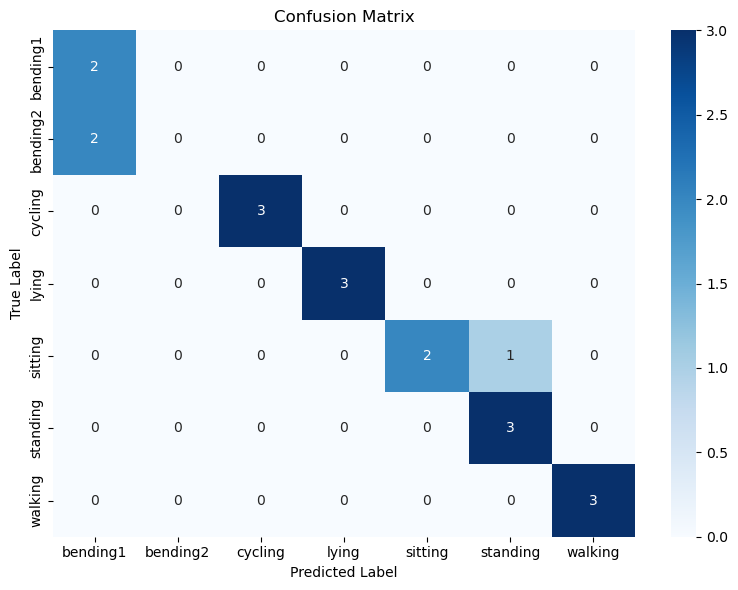

l = 12
Cross Validation Scores: [0.78571429 0.92857143 0.64285714 0.71428571 0.69230769]
Test Accuracy: 0.7368


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


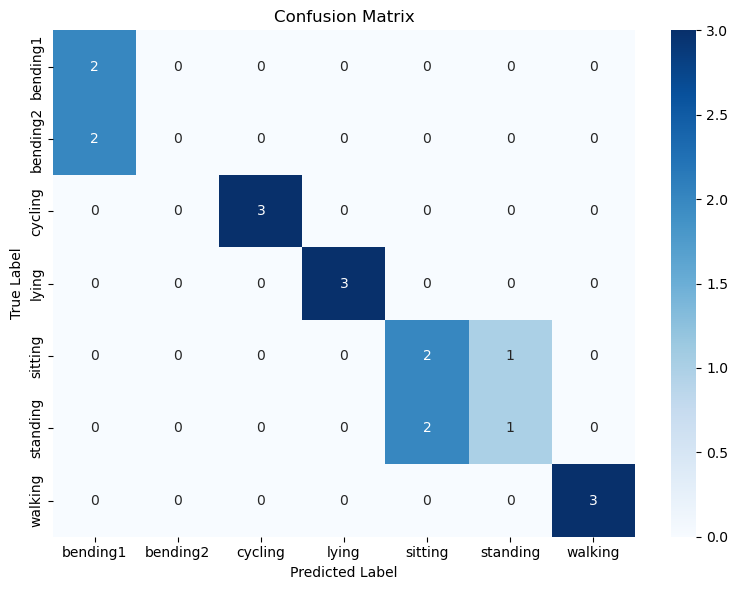

l = 13
Cross Validation Scores: [0.78571429 0.92857143 0.57142857 0.71428571 0.76923077]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


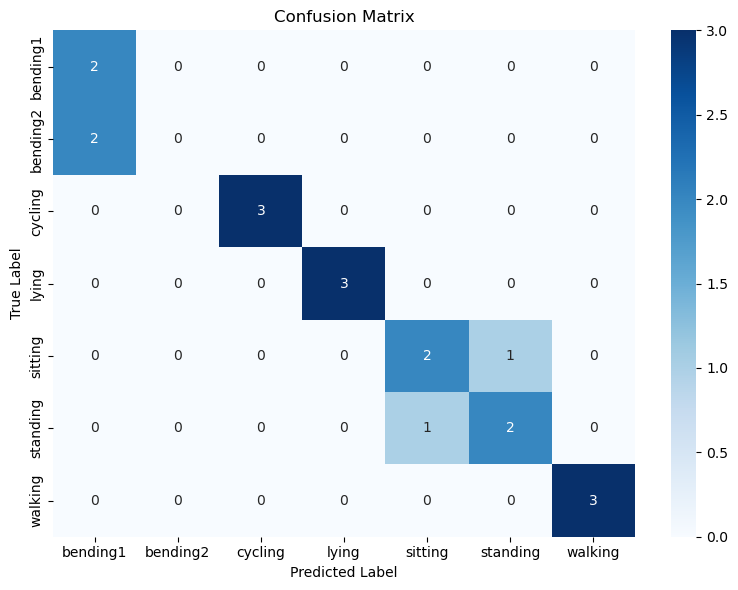

l = 14


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.78571429 0.92857143 0.71428571 0.71428571 0.69230769]
Test Accuracy: 0.7368


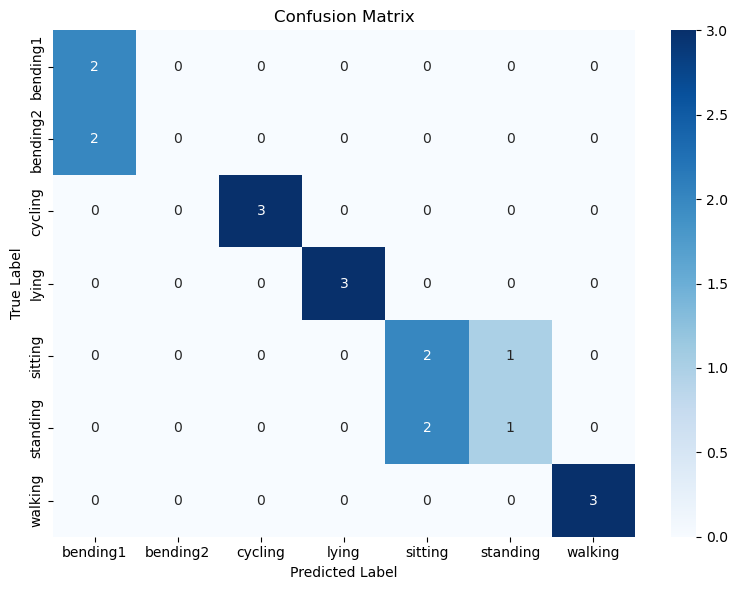

l = 15
Cross Validation Scores: [0.71428571 0.92857143 0.78571429 0.71428571 0.76923077]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


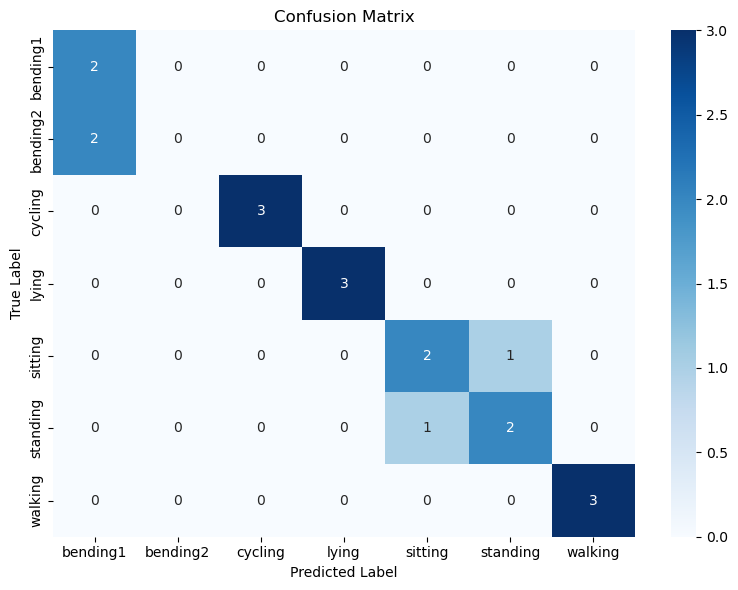

l = 16
Cross Validation Scores: [0.78571429 0.92857143 0.64285714 0.71428571 0.69230769]
Test Accuracy: 0.7895


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


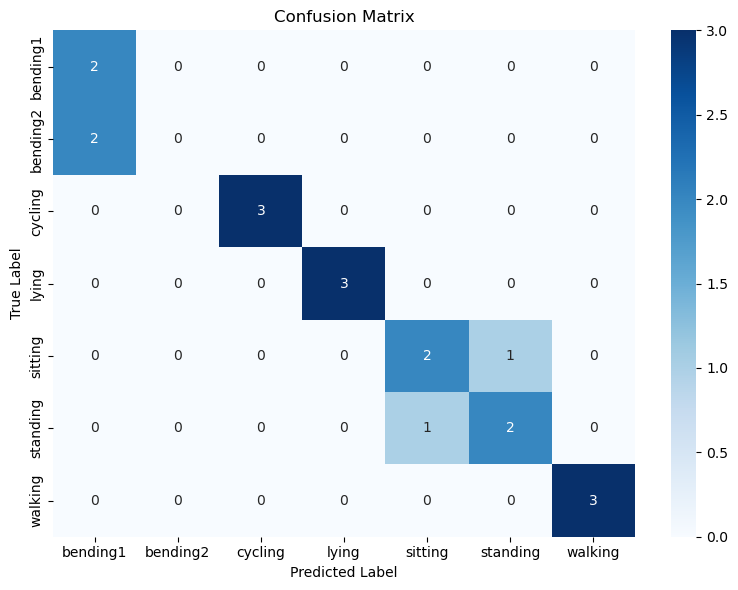

/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


l = 17
Cross Validation Scores: [0.78571429 0.92857143 0.57142857 0.71428571 0.69230769]
Test Accuracy: 0.8421


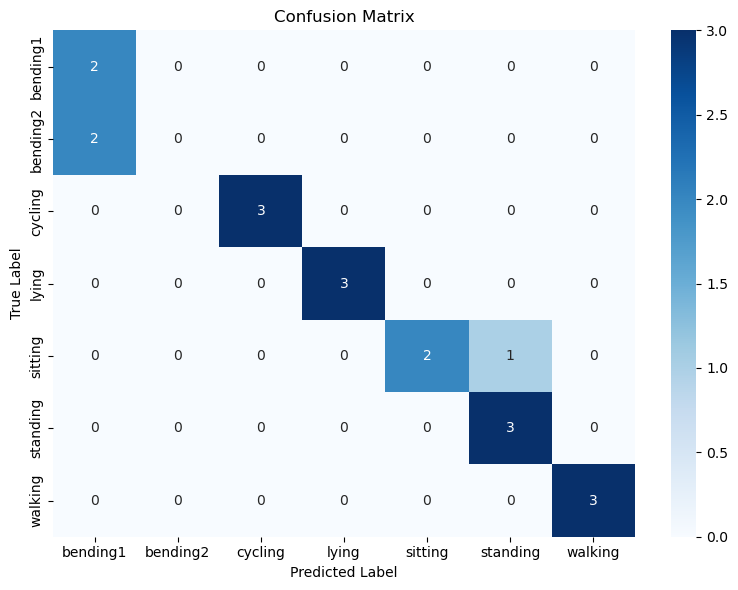

l = 18


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.78571429 0.92857143 0.64285714 0.71428571 0.69230769]
Test Accuracy: 0.7895


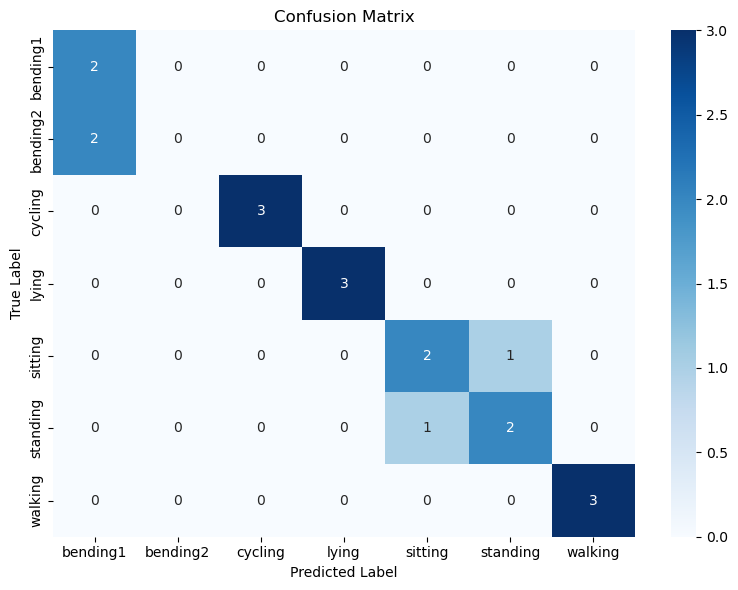

l = 19


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.78571429 0.92857143 0.57142857 0.71428571 0.69230769]
Test Accuracy: 0.8421


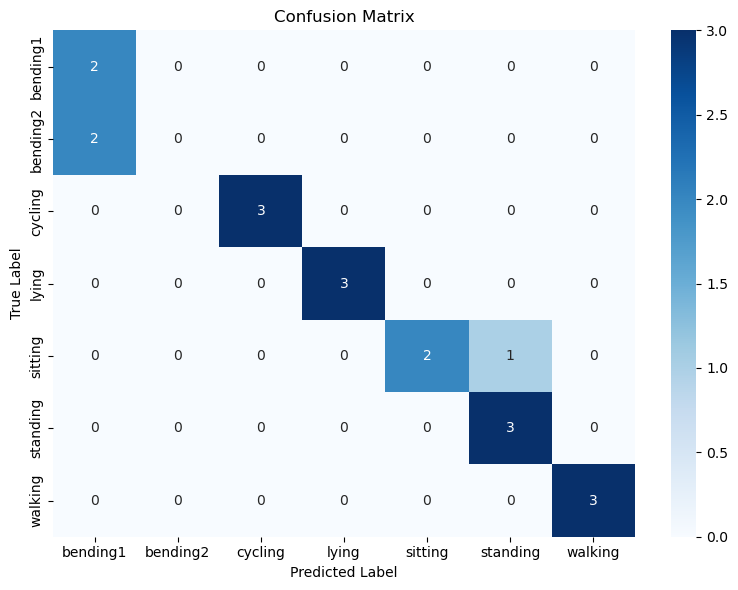

l = 20


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Cross Validation Scores: [0.78571429 0.92857143 0.64285714 0.71428571 0.69230769]
Test Accuracy: 0.8421


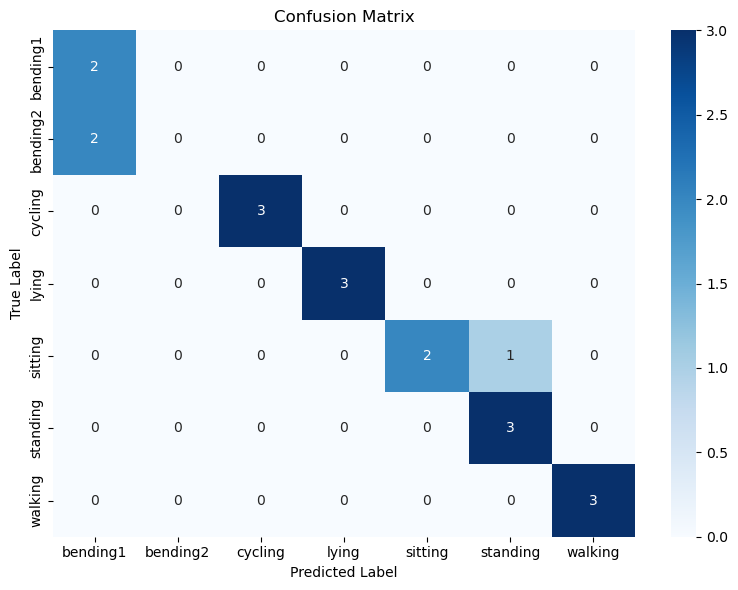

In [18]:
for l in range(1, 21, 1):
    print(f'l = {l}')
    print("Cross Validation Scores:", cross_val_score(model, X_train[l], Y_train, cv=5))
    model.fit(X_train[l], Y_train)
    Y_pred = model.predict(X_test[l])
    print(f'Test Accuracy: {accuracy_score(Y_test, Y_pred):.4f}')
    cm = confusion_matrix(Y_test, Y_pred)
    plt.figure(figsize=(8, 6))
    class_names = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()

Number of features used = 37


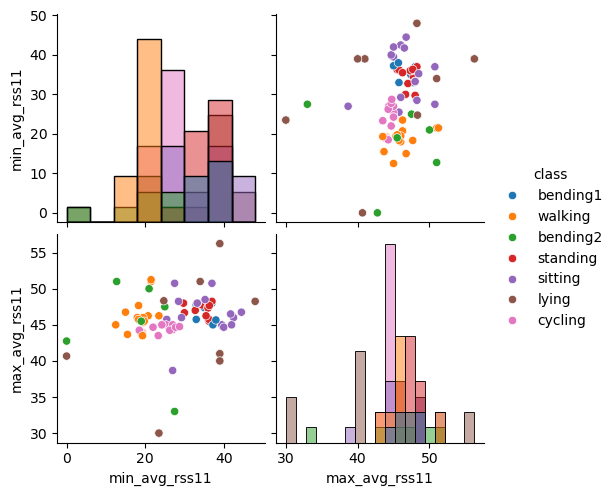

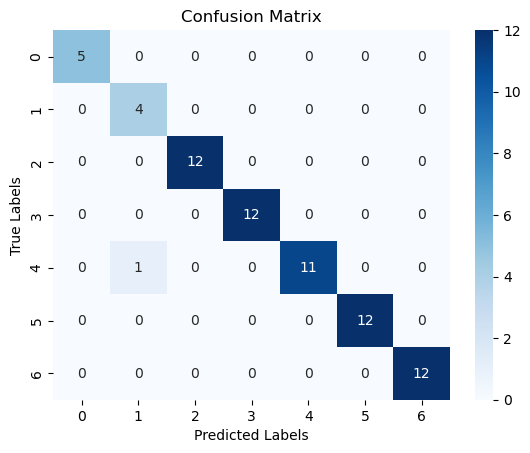

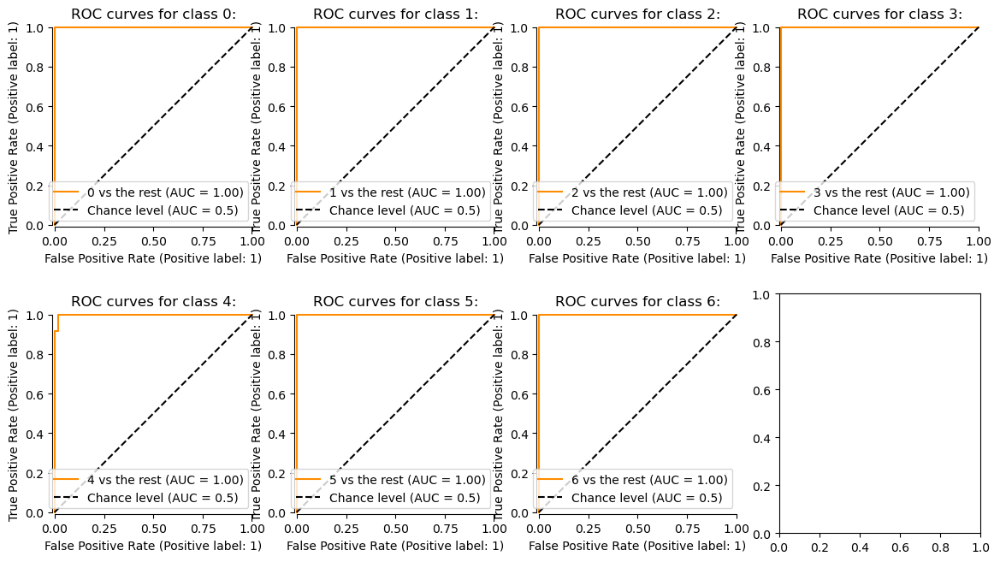

In [19]:
model = GaussianNB()

l = 1

indicies = pca_indicies
print(f'Number of features used = {len(indicies)}')
X_reduced_train = X_train[l].iloc[:, indicies]
X_reduced_test = X_test[l].iloc[:, indicies]
y_t = pd.DataFrame(Y_train, columns = ['class'])
y_tst = pd.DataFrame(Y_test, columns = ['class'])
disp = pd.concat([pd.concat([X_train[l], X_test[l]]), pd.concat([y_t, y_tst])], axis=1)
disp = disp.iloc[:, [indicies[0], indicies[1]]+[-1]]
sns.pairplot(disp, hue="class", diag_kind="hist")

model.fit(X_reduced_train, Y_train)

Y_pred = model.predict(X_reduced_train)
Y_score = model.predict_log_proba(X_reduced_train)

cm = confusion_matrix(Y_train, Y_pred)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(14, 8))

for i in range(len(cm)):
    RocCurveDisplay.from_predictions(
        Y_onehot_train[:, i],
        Y_score[:, i],
        ax=axs[i//4, i-4],
        name=f"{i} vs the rest",
        color="darkorange",
        plot_chance_level=True,
        despine=True,
    )
    axs[i//4, i-4].set_title(f'ROC curves for class {i}:')
    axs[i//4, i-4].plot(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
    )


In [20]:
print(f'l = {l}')
print("Cross Validation Scores:", cross_val_score(model, X_reduced_train, Y_train, cv=5))
model.fit(X_reduced_train, Y_train)
Y_pred = model.predict(X_reduced_test)
print(f'Test Accuracy: {accuracy_score(Y_test, Y_pred):.4f}')

l = 1
Cross Validation Scores: [0.92857143 0.85714286 0.92857143 0.92857143 0.53846154]
Test Accuracy: 0.8947


/Users/robin/miniconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


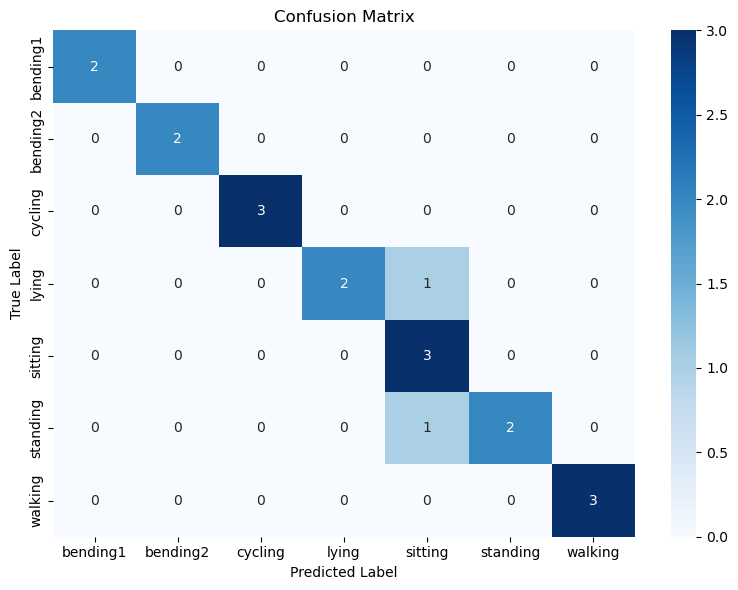

In [21]:
cm = confusion_matrix(Y_test, Y_pred)
plt.figure(figsize=(8, 6))
class_names = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()